In [52]:
%config SqlMagic.displaylimit = 50

# Projektowanie Baz Danych — Wykład 3
## SQL analityczny w praktyce: od LATERAL do widoków

**Baza:** `chinook` — trzy systemy jednocześnie:

| alias | system | schemat / styl nazw |
|---|---|---|
| `pg` | PostgreSQL 18 | `public`, `snake_case` (`invoice_date`, `billing_country`) |
| `mssql` | MS SQL Server 2025 | `dbo`, `PascalCase` (`InvoiceDate`, `BillingCountry`) |
| `oracle` | Oracle 26ai Free | `C##CHINOOK`, `UPPERCASE` (`INVOICEDATE`, `BILLINGCOUNTRY`) |

> Ten notatnik jest **przenośny**: każdy przykład uruchamiamy równolegle na trzech
> silnikach, żeby różnice dialektów widzieć na żywo, a nie tylko w tabeli na slajdach.

**Plan wykładu** (numery = sekcje notatnika):

1. LATERAL i APPLY — korelowane podzapytania w FROM
2. Funkcje daty — EXTRACT, TO_CHAR, DATEPART i przyjaciele
3. PIVOT i UNPIVOT — obracanie tabeli (i brak PIVOT w PG): COUNT
   zamiast SUM, wielokolumnowe `IN ((a, b))` w Oracle
4. CASE — swiss-army knife SQL-a (+ `NULLIF`)
5. Grupowanie wielopoziomowe — `GROUPING SETS`, `ROLLUP`, `CUBE`, `GROUPING()`
   oraz agregacja tekstowa `LISTAGG`/`STRING_AGG`
6. Funkcje okienne — teoria: partycja, ramka, kolejność wykonania
7. `OVER ()` i `PARTITION BY` — agregaty bez GROUP BY
8. `OVER (ORDER BY ...)` — sumy narastające
9. `ROWS` / `RANGE` / `GROUPS` — precyzyjne ramki
10. Funkcje rankingowe — ROW_NUMBER, RANK, DENSE_RANK, NTILE (+ `DISTINCT ON`)
11. Funkcje pozycyjne — LAG, LEAD, FIRST_VALUE, LAST_VALUE, NTH_VALUE
12. Percentyle — PERCENT_RANK, CUME_DIST, MEDIAN, PERCENTILE_CONT/DISC (+ `STDDEV`/`VARIANCE`)
13. Zabawa z oknami — ramki zależne od wiersza
14. CTE — zwykłe (wielokrotne użycie, MATERIALIZED) i rekurencyjne
   (hierarchia pracowników)
15. Tabele tymczasowe
16. Zmienne — T-SQL `DECLARE`/`@` i podstawienia SQL*Plus
17. Widoki — proste, złożone, modyfikowalne, `CREATE OR REPLACE`, CHECK OPTION, materializowane
18. Pseudokolumny — ROWID i ROWNUM (działający Top-N i stronicowanie)
19. Przykłady praktyczne — wszystko razem
20. Podsumowanie — ściąga dialektyczna

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
%reload_ext sql
# Read connection strings from environment variables
%sql $PWR_PG_CONN --alias pg
%sql $PWR_MSSQL_CONN --alias mssql
%sql $PWR_ORACLE_CONN --alias oracle



Connecting to 'pg'

Connecting and switching to connection 'mssql'

Connecting and switching to connection 'oracle'

In [7]:
%%sql oracle
-- jak w wykładzie 2: domyślny schemat sesji = C##CHINOOK
ALTER SESSION SET CURRENT_SCHEMA = C##CHINOOK


++
||
++
++

> **Uwaga praktyczna.** Konta studenckie mają w Oracle i MSSQL **tylko SELECT**
> na obiektach chinook (brak CREATE VIEW / CREATE TABLE w schematach danych).
> Dlatego część przykładów DDL (widoki w Oracle, tabele tymczasowe w Oracle,
> trwałe obiekty w MSSQL) pokazujemy **jako składnię w markdown** — a to, co da
> się wykonać, wykonujemy na tabelach/widokach **tymczasowych** (PG) lub w
> `tempdb` (MSSQL `#tabela`). 

## 1. LATERAL i APPLY — skorelowane podzapytania w FROM

Cel: **top-N wierszy na grupę** — np. 'dla każdego przedstawiciela handlowego dwóch jego najlepszych klientów'. Naturalnie powinniśmy tutaj zastosować skorelowane podzapytanie, ale ono działa tylko w ramach **SELECT / WHERE**. 

W `FROM` zwykłe podzapytanie **nie widzi** innych elementów listy FROM
(są przetwarzane równolegle). 

Zwykłe złączenie (JOIN) łączy dwie tabele na podstawie danego warunku, ale prawa strona złączenia jest stałym zbiorem, obliczanym niezależnie od bieżącego wiersza po lewej stronie. Podzapytanie w klauzuli FROM podlega temu samemu ograniczeniu: jest ewaluowane tylko raz dla całego zapytania i nie może uzyskać dostępu do wartości poszczególnych kolumn z otaczających go wierszy. 

**Podejście naiwne** — podzapytanie w FROM odwołuje się do `e`:

```sql
-- PostgreSQL
SELECT e.last_name, s.kwota
FROM employee e,
     (SELECT SUM(i.total) AS kwota
        FROM customer c JOIN invoice i USING (customer_id)
       WHERE c.support_rep_id = e.employee_id) s;   -- BŁĄD
```

> **Pułapka.** PG: `ERROR: invalid reference to FROM-clause entry for table "e"`.
> Zwykłe podzapytanie w FROM nie może odwoływać się do wcześniejszych pozycji
> listy FROM. Potrzebne słowo `LATERAL` (albo w T-SQL: `APPLY`).

Złączenie typu LATERAL znosi właśnie to ograniczenie. Dodanie słowa kluczowego LATERAL pozwala podzapytaniu w klauzuli FROM odwoływać się do kolumn z tabel poprzedzających je w tej samej klauzuli. Zatem jeśli standardowe złączenie przypomina porównywanie dwóch statycznych arkuszy kalkulacyjnych, to złączenie LATERAL jest najbliższym odpowiednikiem pętli FOR EACH w języku SQL. Wykonuje ono prawostronne podzapytanie dynamicznie dla każdego pojedynczego wiersza tabeli po lewej stronie.

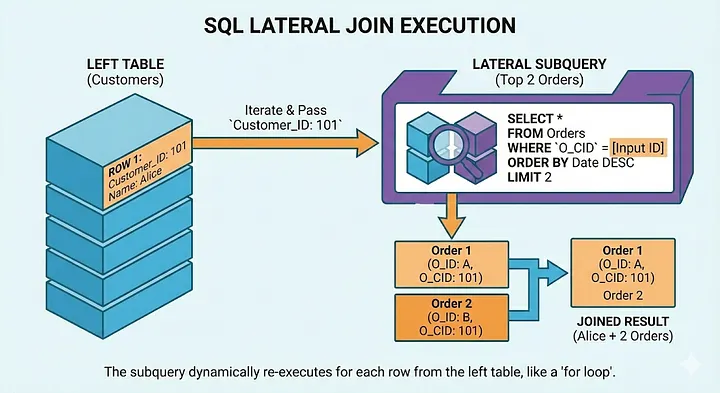

Aby uzyskać powyższy efekt, możemy zastosować słowo kluczowe `LATERAL` (standard SQL, PG i Oracle) oraz `CROSS APPLY` / `OUTER APPLY` (T-SQL). Nazwa złączenia LATERAL (LATERAL Join) pochodzi ze standardu SQL — PostgreSQL, MySQL 8.0.14+ i inne bazy danych implementują tę funkcjonalność dokładnie pod tym słowem kluczowym. SQL Server oferuje tę samą funkcjonalność pod nazwami CROSS APPLY oraz OUTER APPLY, co semantycznie odpowiada użyciu LATERAL odpowiednio z INNER JOIN lub LEFT JOIN. Oracle od wersji 12c również wspiera LATERAL, a alternatywnie także CROSS APPLY.

**PostgreSQL** — `LATERAL` w akcji (top-2 klientów per przedstawiciel):

In [55]:
%%sql pg
-- LATERAL pozwala podzapytaniu widzieć e (równoległy element FROM)
SELECT e.last_name AS przedstawiciel,
       t.klient, t.kwota
FROM employee e,
     LATERAL (SELECT c.first_name || ' ' || c.last_name AS klient,
                     ROUND(SUM(i.total), 2)              AS kwota
                FROM customer c
                JOIN invoice   i USING (customer_id)
               WHERE c.support_rep_id = e.employee_id
               GROUP BY c.customer_id, c.first_name, c.last_name
               ORDER BY kwota DESC
               LIMIT 2) t
ORDER BY e.employee_id, t.kwota DESC;


Switching to connection 'pg'

6 rows affected.

przedstawiciel,klient,kwota
Peacock,Hugh O'Reilly,45.62
Peacock,Ladislav Kovács,45.62
Park,Richard Cunningham,47.62
Park,František Wichterlová,40.62
Johnson,Helena Holý,49.62
Johnson,Luis Rojas,46.62


`LATERAL` działa jak złączenie boczne: podzapytanie jest wykonywane **osobno
dla każdego wiersza** `e` (koncepcyjnie — optymalizator może to przepisać na
zwykły join). Zauważ: Adams (GM) **wypadł** — nie ma klientów, więc `LATERAL`
(zachowaniem jak INNER JOIN) go odrzucił. Wersja z LEFT JOIN zachowa
wszystkich:

In [5]:
%%sql pg
-- LEFT JOIN LATERAL = zachowaj pracowników bez wyników (OUTER APPLY w T-SQL)
SELECT e.last_name AS przedstawiciel,
       COALESCE(t.klient, '(brak klientów)') AS klient,
       t.kwota
FROM employee e
LEFT JOIN LATERAL (SELECT c.first_name || ' ' || c.last_name AS klient,
                          ROUND(SUM(i.total), 2)              AS kwota
                     FROM customer c
                     JOIN invoice   i USING (customer_id)
                    WHERE c.support_rep_id = e.employee_id
                    GROUP BY c.customer_id, c.first_name, c.last_name
                    ORDER BY kwota DESC
                    LIMIT 2) t ON TRUE
ORDER BY e.employee_id, t.kwota DESC NULLS LAST;


11 rows affected.

przedstawiciel,klient,kwota
Adams,(brak klientów),None
Edwards,(brak klientów),None
Peacock,Hugh O'Reilly,45.62
Peacock,Ladislav Kovács,45.62
Park,Richard Cunningham,47.62
Park,František Wichterlová,40.62
Johnson,Helena Holý,49.62
Johnson,Luis Rojas,46.62
Mitchell,(brak klientów),None
King,(brak klientów),None


**Oracle** — `LATERAL` i `OUTER APPLY` (Oracle zna też APPLY od 12c):

In [6]:
%%sql oracle
-- Oracle: LATERAL + FETCH FIRST zamiast LIMIT
SELECT e.LastName AS Przedstawiciel,
       t.klient,
       t.kwota
FROM Employee e,
     LATERAL (SELECT c.FirstName || ' ' || c.LastName AS klient,
                     ROUND(SUM(i.Total), 2)           AS kwota
                FROM Customer c
                JOIN Invoice   i ON i.CustomerId = c.CustomerId
               WHERE c.SupportRepId = e.EmployeeId
               GROUP BY c.CustomerId, c.FirstName, c.LastName
               ORDER BY kwota DESC
               FETCH FIRST 2 ROWS ONLY) t
ORDER BY e.EmployeeId, t.kwota DESC;


Switching to connection 'oracle'

przedstawiciel,klient,kwota
Peacock,Ladislav Kovács,45.62
Peacock,Hugh O'Reilly,45.62
Park,Richard Cunningham,47.62
Park,František Wichterlová,40.62
Johnson,Helena Holý,49.62
Johnson,Luis Rojas,46.62


In [7]:
%%sql oracle
-- Oracle zna też CROSS/OUTER APPLY (składnia T-SQL, od 12c)
SELECT e.LastName AS Przedstawiciel,
       COALESCE(t.klient, '(brak klientów)') AS klient,
       t.kwota
FROM Employee e
OUTER APPLY (SELECT c.FirstName || ' ' || c.LastName AS klient,
                    ROUND(SUM(i.Total), 2)           AS kwota
               FROM Customer c
               JOIN Invoice   i ON i.CustomerId = c.CustomerId
              WHERE c.SupportRepId = e.EmployeeId
              GROUP BY c.CustomerId, c.FirstName, c.LastName
              ORDER BY kwota DESC
              FETCH FIRST 2 ROWS ONLY) t
ORDER BY e.EmployeeId, t.kwota DESC NULLS LAST;


przedstawiciel,klient,kwota
Adams,(brak klientów),None
Edwards,(brak klientów),None
Peacock,Ladislav Kovács,45.62
Peacock,Hugh O'Reilly,45.62
Park,Richard Cunningham,47.62
Park,František Wichterlová,40.62
Johnson,Helena Holý,49.62
Johnson,Luis Rojas,46.62
Mitchell,(brak klientów),None
King,(brak klientów),None


**MS SQL Server** — nie ma LATERAL, za to ma APPLY:

In [8]:
%%sql mssql
-- T-SQL: CROSS APPLY = LATERAL (INNER), OUTER APPLY = LEFT JOIN LATERAL
SELECT e.LastName AS Przedstawiciel,
       COALESCE(t.klient, N'(brak klientów)') AS klient,
       t.kwota
FROM Employee e
OUTER APPLY (SELECT TOP (2) c.FirstName + N' ' + c.LastName AS klient,
                    ROUND(SUM(i.Total), 2)               AS kwota
               FROM Customer c
               JOIN Invoice   i ON i.CustomerId = c.CustomerId
              WHERE c.SupportRepId = e.EmployeeId
              GROUP BY c.CustomerId, c.FirstName, c.LastName
              ORDER BY kwota DESC) t
ORDER BY e.EmployeeId, t.kwota DESC;


Switching to connection 'mssql'

Przedstawiciel,klient,kwota
Adams,(brak klientów),None
Edwards,(brak klientów),None
Peacock,Ladislav Kovács,45.62
Peacock,Hugh O'Reilly,45.62
Park,Richard Cunningham,47.62
Park,František Wichterlová,40.62
Johnson,Helena Holý,49.62
Johnson,Luis Rojas,46.62
Mitchell,(brak klientów),None
King,(brak klientów),None


> **Pułapka (T-SQL).** `LATERAL` w MSSQL nie istnieje:
> `Msg 156: Incorrect syntax near the keyword 'SELECT'`.
> Symetria pojęć: `CROSS APPLY` ≡ `LATERAL` (semantyka INNER), `OUTER APPLY` ≡
> `LEFT JOIN LATERAL ... ON TRUE` (semantyka LEFT). Zwykłe złączenie tego nie
> zastąpi, bo w podzapytaniu jest **per grupa** `TOP`/`LIMIT` + `ORDER BY`.

| | PostgreSQL | MS SQL | Oracle |
|---|---|---|---|
| skorelowane podzapytanie w FROM | `LATERAL` | brak → `APPLY` | `LATERAL` |
| wariant zewnętrzny | `LEFT JOIN LATERAL ... ON TRUE` | `OUTER APPLY` | `OUTER APPLY` |
| TOP-N w podzapytaniu | `ORDER BY ... LIMIT n` | `ORDER BY ... TOP (n)` | `ORDER BY ... FETCH FIRST n ROWS ONLY` |

## 2. Funkcje daty — EXTRACT, TO_CHAR, DATEPART i przyjaciele

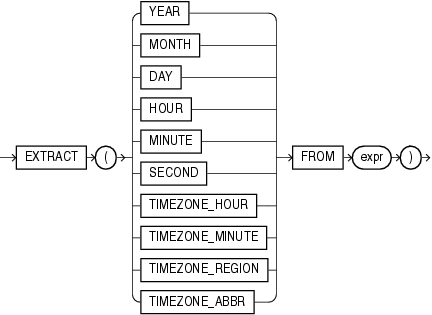

Przypomnienie z wykładu 2 (§ 15): każdy silnik ma własną rodzinę
funkcji daty — tu je zestawiamy i dopowiamy braki. Typowe zadania:
rok/kwartał/miesiąc, dzień tygodnia, pierwsza/ostatnia dnia miesiąca,
różnica, formatowanie. Każdy silnik ma własną rodzinę funkcji —
najprzenośniejszy rdzeń to `EXTRACT` (…z wyjątkiem MSSQL!).

**PostgreSQL** — `EXTRACT`, `DATE_TRUNC`, `AGE`, `make_date`:

In [9]:
%%sql pg
-- EXTRACT zwraca typu numeric (uwaga na DOW: niedziela = 0!)
SELECT EXTRACT(YEAR     FROM invoice_date) AS rok,
       EXTRACT(QUARTER  FROM invoice_date) AS kwartal,
       EXTRACT(MONTH    FROM invoice_date) AS miesiac,
       COUNT(*)                            AS faktur
FROM invoice
GROUP BY 1, 2, 3
ORDER BY 1, 2, 3
LIMIT 12;


Switching to connection 'pg'

12 rows affected.

rok,kwartal,miesiac,faktur
2021,1,1,6
2021,1,2,7
2021,1,3,7
2021,2,4,7
2021,2,5,7
2021,2,6,7
2021,3,7,7
2021,3,8,7
2021,3,9,7
2021,4,10,7


In [10]:
%%sql pg
-- praca z "ostatnim dniem miesiąca" i stażem
SELECT DATE_TRUNC('month', invoice_date)      AS pocz_mies,
       (DATE_TRUNC('month', invoice_date) + INTERVAL '1 month - 1 day')::date AS kon_mies,
       COUNT(*)                               AS faktur
FROM invoice
WHERE EXTRACT(YEAR FROM invoice_date) = 2025
GROUP BY 1
ORDER BY 1;


12 rows affected.

pocz_mies,kon_mies,faktur
2025-01-01 00:00:00,2025-01-31,7
2025-02-01 00:00:00,2025-02-28,5
2025-03-01 00:00:00,2025-03-31,7
2025-04-01 00:00:00,2025-04-30,5
2025-05-01 00:00:00,2025-05-31,7
2025-06-01 00:00:00,2025-06-30,7
2025-07-01 00:00:00,2025-07-31,7
2025-08-01 00:00:00,2025-08-31,7
2025-09-01 00:00:00,2025-09-30,7
2025-10-01 00:00:00,2025-10-31,7


In [11]:
%%sql pg
SELECT first_name || ' ' || last_name AS pracownik,
       hire_date,
       AGE(hire_date)                  AS staz,      -- interval
       DATE_PART('year', AGE(hire_date))::int AS lat_stazu
FROM employee
ORDER BY hire_date;


8 rows affected.

pracownik,hire_date,staz,lat_stazu
Jane Peacock,2002-04-01 00:00:00,"8970 days, 0:00:00",24
Nancy Edwards,2002-05-01 00:00:00,"8940 days, 0:00:00",24
Andrew Adams,2002-08-14 00:00:00,"8837 days, 0:00:00",24
Margaret Park,2003-05-03 00:00:00,"8573 days, 0:00:00",23
Steve Johnson,2003-10-17 00:00:00,"8409 days, 0:00:00",23
Michael Mitchell,2003-10-17 00:00:00,"8409 days, 0:00:00",23
Robert King,2004-01-02 00:00:00,"8329 days, 0:00:00",22
Laura Callahan,2004-03-04 00:00:00,"8267 days, 0:00:00",22


**Oracle** — `EXTRACT`, `TO_CHAR`, `ADD_MONTHS`, `LAST_DAY`, `MONTHS_BETWEEN`:

In [12]:
%%sql oracle
SELECT EXTRACT(YEAR  FROM InvoiceDate) AS Rok,
       EXTRACT(MONTH FROM InvoiceDate) AS Miesiac,
       COUNT(*)                         AS Faktur
FROM Invoice
GROUP BY EXTRACT(YEAR FROM InvoiceDate), EXTRACT(MONTH FROM InvoiceDate)
ORDER BY Rok, Faktur DESC, Miesiac
FETCH FIRST 12 ROWS ONLY;


Switching to connection 'oracle'

rok,miesiac,faktur
2021,2,7
2021,3,7
2021,4,7
2021,5,7
2021,6,7
2021,7,7
2021,8,7
2021,9,7
2021,10,7
2021,11,7


In [13]:
%%sql oracle
-- TO_CHAR: formatowanie + słowna nazwa miesiąca (NLS_DATE_LANGUAGE!)
SELECT LastName                        AS Pracownik,
       HireDate                        AS Zatrudniony,
       TO_CHAR(HireDate, 'YYYY-MM-DD') AS Iso,
       TO_CHAR(HireDate, 'DD Mon YYYY', 'NLS_DATE_LANGUAGE=POLISH') AS Slownie,
       ROUND(MONTHS_BETWEEN(SYSDATE, HireDate)) AS Miesiecy_stazu
FROM Employee
ORDER BY HireDate;


pracownik,zatrudniony,iso,slownie,miesiecy_stazu
Peacock,2002-04-01 00:00:00,2002-04-01,01 Kwi 2002,295
Edwards,2002-05-01 00:00:00,2002-05-01,01 Maj 2002,294
Adams,2002-08-14 00:00:00,2002-08-14,14 Sie 2002,291
Park,2003-05-03 00:00:00,2003-05-03,03 Maj 2003,282
Johnson,2003-10-17 00:00:00,2003-10-17,17 Paź 2003,276
Mitchell,2003-10-17 00:00:00,2003-10-17,17 Paź 2003,276
King,2004-01-02 00:00:00,2004-01-02,02 Sty 2004,274
Callahan,2004-03-04 00:00:00,2004-03-04,04 Mar 2004,272


In [14]:
%%sql oracle
-- ADD_MONTHS / LAST_DAY / TRUNC — klasyka raportów okresowych
SELECT SYSDATE                        AS Teraz,
       ADD_MONTHS(SYSDATE, -6)        AS Pol_roku_temu,
       LAST_DAY(SYSDATE)              AS Ostatni_dzn_mies,
       TRUNC(SYSDATE, 'MM')           AS Pierwszy_dzn_mies
FROM DUAL;


teraz,pol_roku_temu,ostatni_dzn_mies,pierwszy_dzn_mies
2026-10-31 21:31:16,2026-04-30 21:31:16,2026-10-31 21:31:16,2026-10-01 00:00:00


**MS SQL Server** — `YEAR`/`DATEPART`/`DATEADD`/`DATEDIFF`/`EOMONTH`:

In [15]:
%%sql mssql
SELECT YEAR(InvoiceDate)                AS Rok,
       DATEPART(QUARTER, InvoiceDate)   AS Kwartal,
       MONTH(InvoiceDate)               AS Miesiac,
       COUNT(*)                         AS Faktur
FROM Invoice
GROUP BY YEAR(InvoiceDate), DATEPART(QUARTER, InvoiceDate), MONTH(InvoiceDate)
ORDER BY Rok, Miesiac;


Switching to connection 'mssql'

Rok,Kwartal,Miesiac,Faktur
2021,1,1,6
2021,1,2,7
2021,1,3,7
2021,2,4,7
2021,2,5,7
2021,2,6,7
2021,3,7,7
2021,3,8,7
2021,3,9,7
2021,4,10,7


In [16]:
%%sql mssql
SELECT FORMAT(HireDate, 'dddd', 'pl-PL')      AS DzienTygodnia,
       CONVERT(varchar(10), HireDate, 105)   AS Eu,   -- dd-mm-yyyy
       CONVERT(varchar(10), HireDate, 120)   AS Iso,  -- yyyy-mm-dd
       DATEDIFF(YEAR, HireDate, GETDATE())   AS LatStazu
FROM Employee
ORDER BY HireDate;


DzienTygodnia,Eu,Iso,LatStazu
poniedziałek,01-04-2002,2002-04-01,24
środa,01-05-2002,2002-05-01,24
środa,14-08-2002,2002-08-14,24
sobota,03-05-2003,2003-05-03,23
piątek,17-10-2003,2003-10-17,23
piątek,17-10-2003,2003-10-17,23
piątek,02-01-2004,2004-01-02,22
czwartek,04-03-2004,2004-03-04,22


In [17]:
%%sql mssql
SELECT GETDATE()            AS Teraz,
       DATEADD(MONTH, -6, GETDATE()) AS PolRokuTemu,
       EOMONTH(GETDATE())   AS OstatniDzienMies,
       DATEFROMPARTS(2025, 3, 1)     AS ZCzesci;


Teraz,PolRokuTemu,OstatniDzienMies,ZCzesci
2026-10-31 21:31:16.180000,2026-04-30 21:31:16.180000,2026-10-31,2025-03-01


> **Pułapka 1 (MSSQL).** Nie ma `EXTRACT` — `Msg 195: 'EXTRACT' is not
> a recognized built-in function name`. Odpowiednikiem jest `DATEPART`.
>
> **Pułapka 2 (numeracja dni tygodnia).** Wszędzie inaczej:
> - PG: `EXTRACT(DOW ...)` → niedziela = **0**, sobota = 6; wariant
>   `ISODOW` (poniedziałek = **1**) zgodny z ISO-8601;
> - Oracle: `TO_CHAR(d, 'D')` zależy od `NLS_TERRITORY`;
> - MSSQL: `DATEPART(DW, ...)` zależy od `SET DATEFIRST` (domyślnie USA:
>   niedziela = 1). **Przenośny sposób**: porównać nazwę dnia
>   (`TO_CHAR` / `FORMAT` / `DATENAME`), nie numer.
>
> **Pułapka 3 (TO_CHAR 'Day').** Nazwy dni są dopełniane spacjami do
> szerokości wzorca (`'Friday   '`) — ucina się przez `TRIM` albo modyfikator
> `fm`: `TO_CHAR(d,'fmDay')` (działa w Oracle i w PG).

| zadanie | PostgreSQL | MS SQL | Oracle |
|---|---|---|---|
| rok / miesiąc | `EXTRACT(YEAR FROM d)` / `date_part('year', d)` | `YEAR(d)` / `MONTH(d)` / `DATEPART(...)` | `EXTRACT(YEAR FROM d)` / `TO_CHAR(d,'YYYY')` |
| kwartał | `EXTRACT(QUARTER FROM d)` | `DATEPART(QUARTER, d)` | `TO_CHAR(d,'Q')` |
| dziś / teraz | `CURRENT_DATE` / `now()` | `CAST(GETDATE() AS date)` / `GETDATE()` | `TRUNC(SYSDATE)` / `SYSDATE` |
| dodaj miesiące | `d + INTERVAL 'n month'` | `DATEADD(MONTH, n, d)` | `ADD_MONTHS(d, n)` |
| koniec miesiąca | `(DATE_TRUNC('month', d) + INTERVAL '1 month - 1 day')::date` | `EOMONTH(d)` | `LAST_DAY(d)` |
| różnica (daty) | `AGE(d1, d2)` → interval | `DATEDIFF(YEAR, d2, d1)` (liczy **przekroczenia granicy**) | `MONTHS_BETWEEN(d1, d2)` |
| format | `TO_CHAR(d, 'YYYY-MM-DD')` (zapożyczona od Oracle) | `FORMAT(d, 'yyyy-MM-dd')` / `CONVERT(varchar, d, 120)` | `TO_CHAR(d, 'YYYY-MM-DD')` |

## 3. PIVOT i UNPIVOT — obracanie tabeli

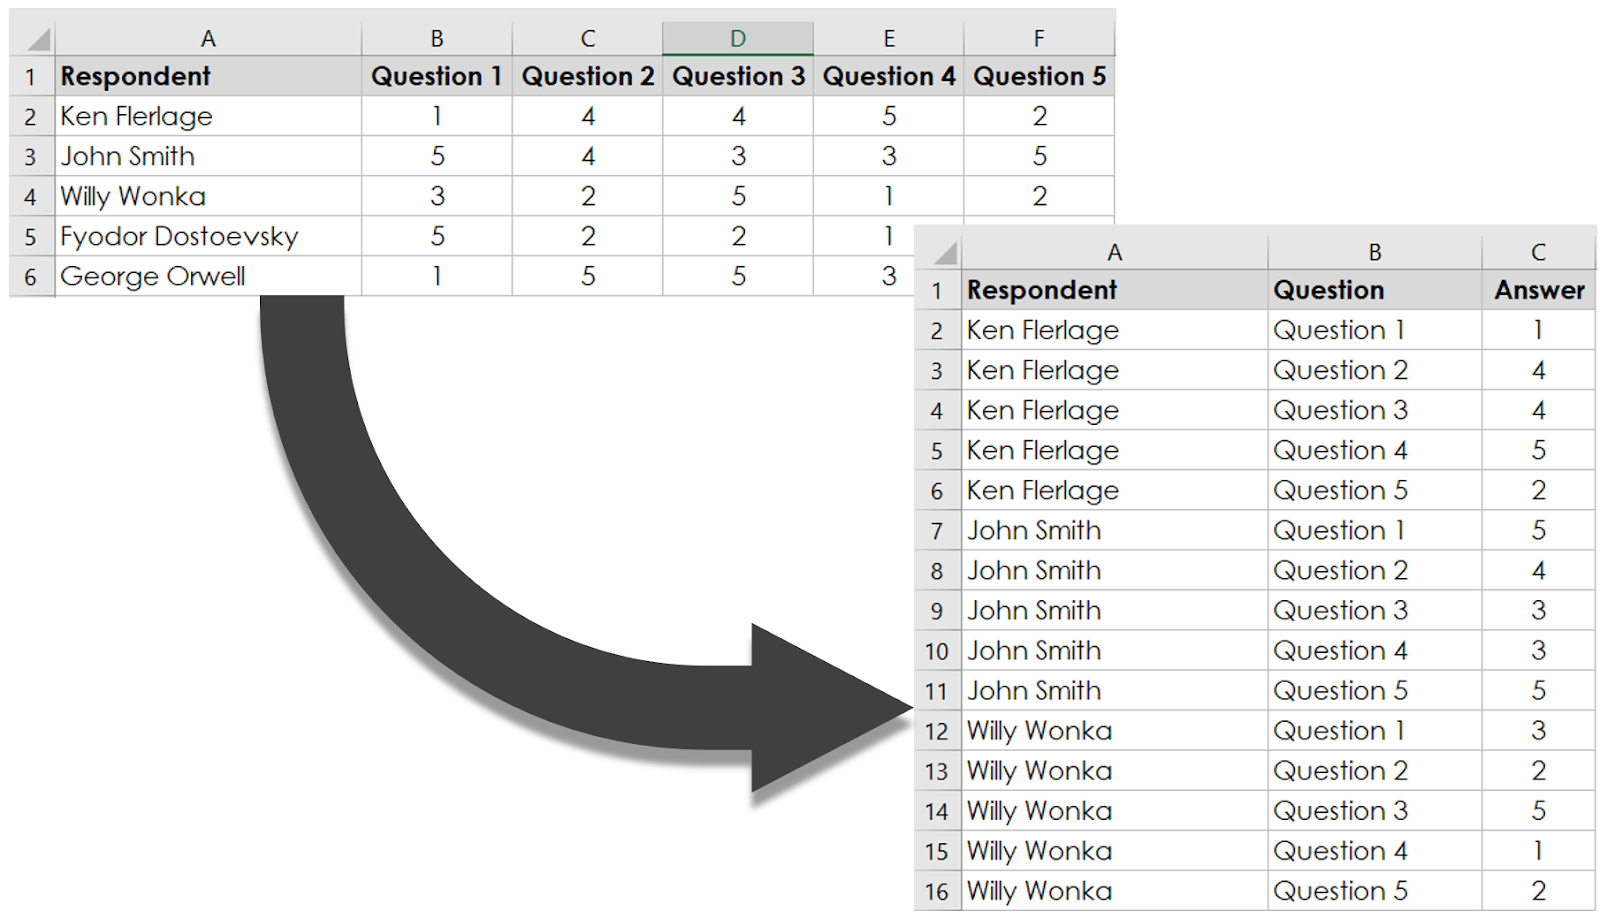

**PIVOT**: wiersze (np. lata) → kolumny (`Y2021`, `Y2022`, ...).
**UNPIVOT**: kolumny → wiersze. Innymi słowy: zwykła tabela vs 'szeroki format'
raportów. Kluczowa własność: **lista obrotowych wartości jest statyczna** —
musi być wypisana w `IN (...)`.

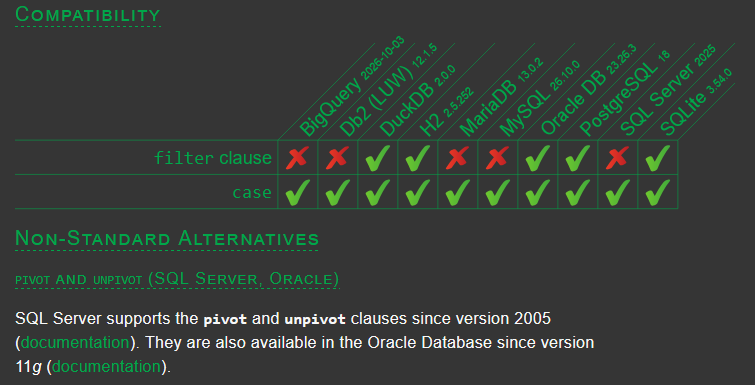

Mimo że klauzula FILTER została wprowadzona w standardzie SQL:2003, do dziś jest rzadko wspierana.


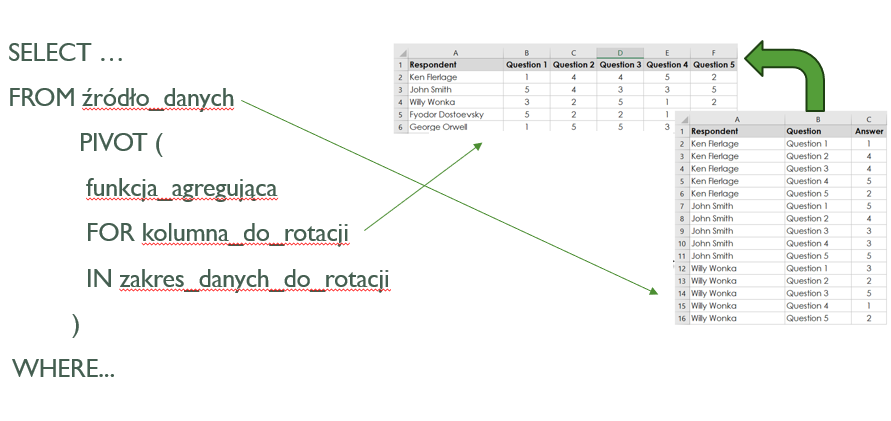

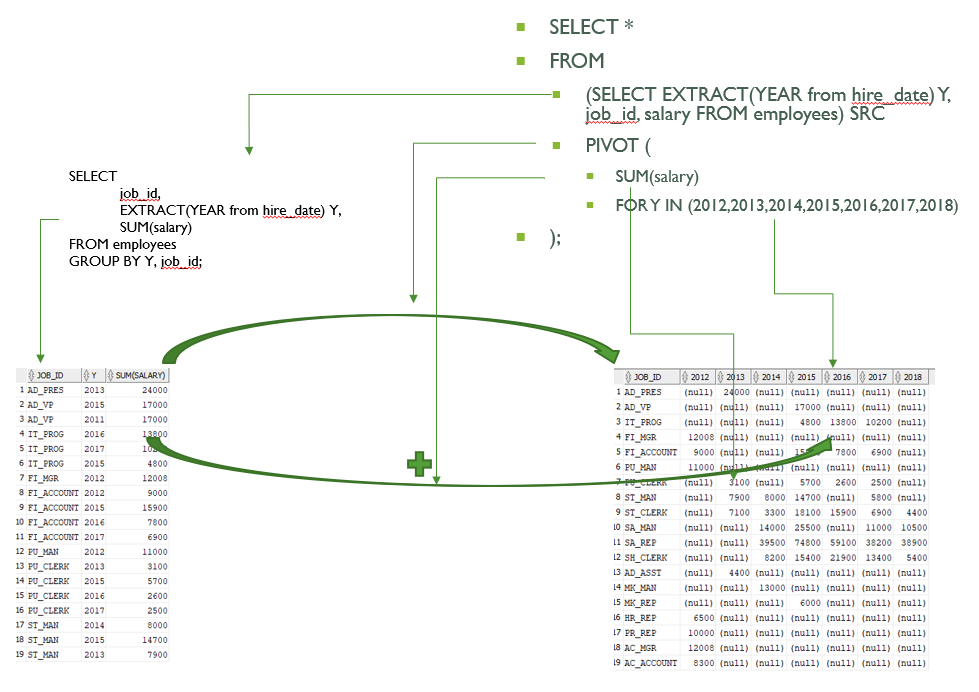

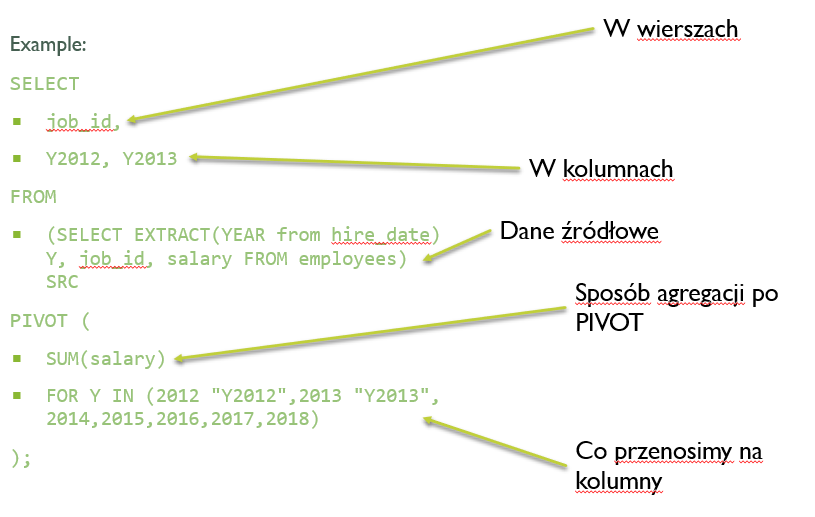

**Oracle** — PIVOT (suma sprzedaży: kraj × rok):

In [ ]:
%%sql oracle
-- Oraclowy PIVOT: wartości z IN stają się kolumnami; aliasy pomagają w nazywaniu
SELECT *
FROM (SELECT BillingCountry                    AS Kraj,
             EXTRACT(YEAR FROM InvoiceDate)    AS Rok,
             Total
      FROM Invoice)
PIVOT (SUM(Total) FOR Rok IN (2021 AS R2021, 2022 AS R2022, 2023 AS R2023,
                              2024 AS R2024, 2025 AS R2025))
ORDER BY Kraj
FETCH FIRST 8 ROWS ONLY;


Switching to connection 'oracle'

kraj,r2021,r2022,r2023,r2024,r2025
Argentina,None,11.88,0.99,None,24.75
Australia,11.88,0.99,1.98,22.77,None
Austria,1.98,27.77,None,11.88,0.99
Belgium,6.93,None,24.75,None,5.94
Brazil,37.62,41.6,19.8,53.46,37.62
Canada,57.42,76.26,55.44,42.57,72.27
Chile,15.84,17.91,5.94,6.93,None
Czech Republic,10.89,9.9,12.87,19.83,36.75


> Kolumny wyjściowe PIVOT nazywają się jak wartości z `IN` — dla lat byłyby
> to `2021`, `2022`… (identyfikator zaczynający się cyfrą wymaga w Oracle
> cudzysłowu przy odwołaniu). Aliasy `IN (2021 AS R2021, ...)` — jak wyżej —
> ratują sytuację: wynik ma czytelne `R2021`...`R2025`.

**MS SQL** — PIVOT (identyczna semantyka, nawiasy wokół wartości):

In [19]:
%%sql mssql
SELECT Kraj, [2021], [2022], [2023], [2024], [2025]
FROM (SELECT BillingCountry AS Kraj,
             YEAR(InvoiceDate) AS Rok,
             Total
      FROM Invoice) AS src
PIVOT (SUM(Total) FOR Rok IN ([2021], [2022], [2023], [2024], [2025])) AS pt
ORDER BY Kraj;


Switching to connection 'mssql'

Kraj,2021,2022,2023,2024,2025
Argentina,None,11.88,0.99,None,24.75
Australia,11.88,0.99,1.98,22.77,None
Austria,1.98,27.77,None,11.88,0.99
Belgium,6.93,None,24.75,None,5.94
Brazil,37.62,41.60,19.80,53.46,37.62
Canada,57.42,76.26,55.44,42.57,72.27
Chile,15.84,17.91,5.94,6.93,None
Czech Republic,10.89,9.90,12.87,19.83,36.75
Denmark,5.94,6.93,None,15.84,8.91
Finland,8.91,None,15.88,0.99,15.84


**PostgreSQL** — **nie ma PIVOT** (ani UNPIVOT). Zamiast tego: agregaty
warunkowe — klauzula `FILTER` (idiomatycznie PG) albo `CASE` (uniwersalnie).

 W ogólności istnieją różne sytuacje, kiedy chcemy dokonoć pivotu danych, jednakże zazwyczaj proces ten składa się z dwóch etapów: grupowanie oraz rotacja. Analogicznie sytuacja w przypadku składki wykorzystującej klazulę FILTER. W pierwszym kroku standardowo grupujemy dany na żądym poziomie aggregacji poprzez GROUP BY (np. z miesięcy na kwartały, czy półrocza), a następnie każdą z grup wartości "przenosimy" na kolumny korzystając z FILTER.

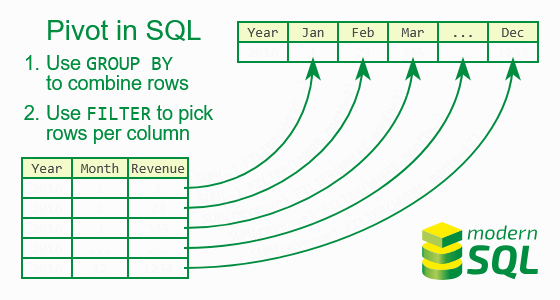

In [20]:
%%sql pg
-- FILTER: agregacja tylko nad podzbiorem wierszy — czytelniej niż CASE
SELECT billing_country AS kraj,
       ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2021), 2) AS y2021,
       ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2022), 2) AS y2022,
       ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2023), 2) AS y2023,
       ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2024), 2) AS y2024,
       ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2025), 2) AS y2025
FROM invoice
GROUP BY billing_country
ORDER BY kraj
LIMIT 8;


Switching to connection 'pg'

8 rows affected.

kraj,y2021,y2022,y2023,y2024,y2025
Argentina,None,11.88,0.99,None,24.75
Australia,11.88,0.99,1.98,22.77,None
Austria,1.98,27.77,None,11.88,0.99
Belgium,6.93,None,24.75,None,5.94
Brazil,37.62,41.60,19.80,53.46,37.62
Canada,57.42,76.26,55.44,42.57,72.27
Chile,15.84,17.91,5.94,6.93,None
Czech Republic,10.89,9.90,12.87,19.83,36.75


> **Pułapka 1 (PG).** `PIVOT` w PG to błąd składniowy
> (`syntax error at or near "("`). W zamian `FILTER` — a `CASE` działa
> wszędzie. `FILTER` istnieje też w… żadnym z pozostałych dwóch:
> MSSQL zgłasza `Incorrect syntax near 'WHERE'`.
>
> **Pułapka 2 (NULL po PIVOT).** Kraj bez faktur w danym roku → NULL.
> Ze slajdów: oznaczanie zer — `NVL(x, 0)` (Oracle) / `ISNULL(x, 0)` (MSSQL) /
> `COALESCE(x, 0)` (standard; w PG).

In [21]:
%%sql pg
-- COALESCE/Round + sortowanie po 2025: raport 'jak dziś wygląda sprzedaż'
SELECT billing_country AS kraj,
       COALESCE(ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2024), 2), 0) AS y2024,
       COALESCE(ROUND(SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2025), 2), 0) AS y2025
FROM invoice
GROUP BY billing_country
ORDER BY y2025 DESC
LIMIT 6;


6 rows affected.

kraj,y2024,y2025
USA,127.98,85.14
Canada,42.57,72.27
France,36.66,40.59
Brazil,53.46,37.62
Czech Republic,19.83,36.75
United Kingdom,9.90,28.71


In [22]:
%%sql mssql
-- ISNULL po PIVOT (podzapytanie, bo po prostu kolumny liczone dalej)
SELECT Kraj,
       ISNULL([2024], 0) AS Y2024,
       ISNULL([2025], 0) AS Y2025
FROM (SELECT BillingCountry AS Kraj, YEAR(InvoiceDate) AS Rok, Total
      FROM Invoice) AS src
PIVOT (SUM(Total) FOR Rok IN ([2024], [2025])) AS pt
ORDER BY Y2025 DESC;


Switching to connection 'mssql'

Kraj,Y2024,Y2025
USA,127.98,85.14
Canada,42.57,72.27
France,36.66,40.59
Brazil,53.46,37.62
Czech Republic,19.83,36.75
United Kingdom,9.90,28.71
Portugal,24.77,24.75
Argentina,0.00,24.75
Finland,0.99,15.84
Netherlands,0.99,15.84


In [23]:
%%sql oracle
-- NVL po PIVOT
SELECT Kraj,
       NVL(R2024, 0) AS R2024,
       NVL(R2025, 0) AS R2025
FROM (SELECT BillingCountry AS Kraj,
             EXTRACT(YEAR FROM InvoiceDate) AS Rok,
             Total
      FROM Invoice)
PIVOT (SUM(Total) FOR Rok IN (2024 AS R2024, 2025 AS R2025))
ORDER BY 3 DESC
FETCH FIRST 6 ROWS ONLY;


Switching to connection 'oracle'

kraj,r2024,r2025
USA,127.98,85.14
Canada,42.57,72.27
France,36.66,40.59
Brazil,53.46,37.62
Czech Republic,19.83,36.75
United Kingdom,9.9,28.71


### PIVOT z COUNT — liczność zamiast sum

Często chcemy też dokonać pivotu na agregacji zliczającej - **liczniku** — zdarzenia, rekordy, faktury. Zatem chcielibyśmy mieć ten sam efekt, ale inny agregat: np. liczba faktur (kraj / rok):

In [24]:
%%sql oracle
SELECT *
FROM (SELECT BillingCountry AS Kraj,
             EXTRACT(YEAR FROM InvoiceDate) AS Rok
      FROM Invoice)
PIVOT (COUNT(*) FOR Rok IN (2023 AS Y2023, 2024 AS Y2024, 2025 AS Y2025))
ORDER BY Kraj
FETCH FIRST 6 ROWS ONLY;

kraj,y2023,y2024,y2025
Argentina,1,0,3
Australia,1,2,0
Austria,0,3,1
Belgium,3,0,2
Brazil,4,9,7
Canada,11,9,14


In [25]:
%%sql mssql
-- MSSQL: COUNT(*) w PIVOT nie działa (Msg 102) — licz po kolumnie źródłowej
SELECT Kraj, [2023], [2024], [2025]
FROM (SELECT BillingCountry AS Kraj, YEAR(InvoiceDate) AS Rok
      FROM Invoice) AS src
PIVOT (COUNT(Rok) FOR Rok IN ([2023], [2024], [2025])) AS pt
ORDER BY Kraj;

Switching to connection 'mssql'

Kraj,2023,2024,2025
Argentina,1,0,3
Australia,1,2,0
Austria,0,3,1
Belgium,3,0,2
Brazil,4,9,7
Canada,11,9,14
Chile,2,2,0
Czech Republic,4,3,3
Denmark,0,2,1
Finland,3,1,2


> **Pułapka (COUNT(*) — „Msg 102" tylko w MSSQL).** Oracle przyjmie
> `PIVOT (COUNT(*) ...)`, a SQL Server odpowiada:
> `Msg 102, Level 15 ... Incorrect syntax near '*'.` — w T-SQL agregat
> w PIVOT musi liczyć po konkretnej kolumnie: `COUNT(Rok)`, `COUNT(InvoiceId)`.
> To nie kwestia stylu, gramatyka T-SQL po prostu tego nie ma.

In [26]:
%%sql pg
-- PG: PIVOT-a nie ma, ale FILTER liczy równie krótko
SELECT billing_country AS kraj,
       COUNT(*) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2023) AS y2023,
       COUNT(*) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2024) AS y2024,
       COUNT(*) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2025) AS y2025
FROM invoice
GROUP BY billing_country
ORDER BY y2025 DESC, kraj
LIMIT 6;

Switching to connection 'pg'

6 rows affected.

kraj,y2023,y2024,y2025
USA,19,21,16
Canada,11,9,14
Brazil,4,9,7
France,8,7,6
United Kingdom,4,2,6
Argentina,1,0,3


> Analogicznie inne funkcje agregujące, jak **SUM()**, **AVG()**, **MIN()**, itp.

### Wielokolumnowe `IN` — obracanie po parach (rozszerzenie Oracle)

Zwykły PIVOT rozprowadza **jedną** kolumnę na n nazw. Oracle idzie dalej:
`FOR (a, b) IN ((w1a, w1b) AS alias, ...)` — każda **para** wartości staje
się osobną kolumną wyniku. „Kraj × rok × kwartał" zwęża się do wybranych
par (rok, kwartał):

In [21]:
%%sql oracle
-- pary (rok, kwartał) jako kolumny; kwartał liczony CASE-em w podzapytaniu
SELECT *
FROM (SELECT BillingCountry AS Kraj,
             EXTRACT(YEAR FROM InvoiceDate) AS rok,
             CASE WHEN EXTRACT(MONTH FROM InvoiceDate) BETWEEN 1 AND 3 THEN 1
                  WHEN EXTRACT(MONTH FROM InvoiceDate) BETWEEN 4 AND 6 THEN 2
                  WHEN EXTRACT(MONTH FROM InvoiceDate) BETWEEN 7 AND 9 THEN 3
                  ELSE 4 END AS kwartal
      FROM Invoice)
PIVOT (COUNT(*) FOR (rok, kwartal) IN
   ( (2025, 1) AS Q1_2025,
     (2025, 2) AS Q2_2025,
     (2025, 3) AS Q3_2025,
     (2024, 4) AS Q4_2024 ))
ORDER BY Kraj
FETCH FIRST 8 ROWS ONLY;

kraj,q1_2025,q2_2025,q3_2025,q4_2024
Argentina,2,0,0,0
Australia,0,0,0,0
Austria,0,1,0,1
Belgium,0,0,1,0
Brazil,2,0,4,3
Canada,5,4,4,2
Chile,0,0,0,1
Czech Republic,0,1,0,0


> **Pułapka 1 (MSSQL — wielokolumnowe IN nie istnieje).** `FOR (Rok, Q)
> IN ((2024, 4), (2025, 1))` w T-SQL kończy się
> `Msg 102 ... Incorrect syntax near '('.` — nawet z `COUNT(Rok)` zamiast
> `COUNT(*)`. Standardowe obejście: skleić parę w jeden klucz
> (`CONCAT(YEAR(InvoiceDate), '_Q', DATEPART(QUARTER, InvoiceDate))`)
> i obracać po pojedynczej kolumnie — albo ręczny pivot z `CASE`,
> który działa wszędzie.
>
> **Pułapka 2 (Oracle — `EXTRACT(QUARTER ...)` w źródle PIVOT).** Kwartał
> wprost z `EXTRACT` w podzapytaniu źródłowym kończy się
> `ORA-00907: missing right parenthesis` — Oracle w ogóle nie obsługuje
> kwartału w `EXTRACT` (do kwartału służy `TO_CHAR(d, 'Q')`;
> patrz sekcja 2). Dlatego kwartał wyżej policzył `CASE`.

W Oracle możemy też zrobić kilka agregacji na raz:

In [16]:
%%sql oracle
-- pary (rok, kwartał) jako kolumny; kwartał liczony CASE-em w podzapytaniu
SELECT *
FROM (SELECT BillingCountry AS Kraj, total, 
             EXTRACT(YEAR FROM InvoiceDate) AS rok,
             CASE WHEN EXTRACT(MONTH FROM InvoiceDate) BETWEEN 1 AND 3 THEN 1
                  WHEN EXTRACT(MONTH FROM InvoiceDate) BETWEEN 4 AND 6 THEN 2
                  WHEN EXTRACT(MONTH FROM InvoiceDate) BETWEEN 7 AND 9 THEN 3
                  ELSE 4 END AS kwartal
      FROM Invoice)
PIVOT (COUNT(*) c, SUM(total) t FOR (rok, kwartal) IN
   ( (2025, 1) AS Q1_2025,
     (2025, 2) AS Q2_2025,
     (2025, 3) AS Q3_2025,
     (2024, 4) AS Q4_2024 ))
ORDER BY Kraj
FETCH FIRST 8 ROWS ONLY;

kraj,q1_2025_c,q1_2025_t,q2_2025_c,q2_2025_t,q3_2025_c,q3_2025_t,q4_2024_c,q4_2024_t
Argentina,2,15.84,0,None,0,None,0,None
Australia,0,None,0,None,0,None,0,None
Austria,0,None,1,0.99,0,None,1,5.94
Belgium,0,None,0,None,1,1.98,0,None
Brazil,2,2.97,0,None,4,28.71,3,24.75
Canada,5,19.8,4,21.78,4,24.75,2,4.95
Chile,0,None,0,None,0,None,1,0.99
Czech Republic,0,None,1,8.91,0,None,0,None


Zwróćcie uwagę na nazwy kolumn. 

Kolejność kolumn jak w `IN`: Q1–Q3 2025, potem Q4 2024. Kraje bez
trafień w wybranych parach mają **zera, nie NULL-e** — `COUNT` nad
pustym zbiorem to zawsze 0 (Australia 0/0/0/0); NULL pojawiłby się
dopiero przy `SUM`/`MAX` (przykład 2024/2025 wyżej w tej sekcji —
tam maskowało je `COALESCE`). W Q3 2025 wypadło łącznie **21 faktur**:
Brazil **2/0/4/3**, Canada **5/4/4/2**, Austria **0/1/0/1**.

### UNPIVOT — szeroko → wąsko

Mamy raport kraje × lata (wygenerowany CASE/FILTER w CTE) i chcemy wrócić do
formatu wierszowego — np. żeby załadować do innego systemu.

In [28]:
%%sql oracle
WITH szer AS (
  SELECT BillingCountry AS Kraj,
         SUM(CASE WHEN EXTRACT(YEAR FROM InvoiceDate) = 2022
                  THEN Total END)                AS Y2022,
         SUM(CASE WHEN EXTRACT(YEAR FROM InvoiceDate) = 2023
                  THEN Total END)                AS Y2023
  FROM Invoice
  GROUP BY BillingCountry
)
SELECT *
FROM szer
UNPIVOT (Kwota FOR Rok IN (Y2022 AS 'Rok 2022',
                           Y2023 AS 'Rok 2023'))
ORDER BY Kraj, Kwota DESC
FETCH FIRST 10 ROWS ONLY;


kraj,rok,kwota
Argentina,Rok 2022,11.88
Argentina,Rok 2023,0.99
Australia,Rok 2023,1.98
Australia,Rok 2022,0.99
Austria,Rok 2022,27.77
Belgium,Rok 2023,24.75
Brazil,Rok 2022,41.6
Brazil,Rok 2023,19.8
Canada,Rok 2022,76.26
Canada,Rok 2023,55.44


In [17]:
%%sql mssql
WITH szer AS (
  SELECT BillingCountry AS Kraj,
         SUM(CASE WHEN YEAR(InvoiceDate) = 2022 THEN Total END) AS Y2022,
         SUM(CASE WHEN YEAR(InvoiceDate) = 2023 THEN Total END) AS Y2023
  FROM Invoice
  GROUP BY BillingCountry
)
SELECT Kraj, Rok, Kwota
FROM szer
UNPIVOT (Kwota FOR Rok IN (Y2022, Y2023)) AS up
ORDER BY Kraj, Kwota DESC;


Switching to connection 'mssql'

Kraj,Rok,Kwota
Argentina,Y2022,11.88
Argentina,Y2023,0.99
Australia,Y2023,1.98
Australia,Y2022,0.99
Austria,Y2022,27.77
Belgium,Y2023,24.75
Brazil,Y2022,41.60
Brazil,Y2023,19.80
Canada,Y2022,76.26
Canada,Y2023,55.44


> **Pułapka (UNPIVOT gubi NULL-e).** Zarówno Oracle, jak i MSSQL **domyślnie
> pomijają** wiersze, w których rozwijana kolumna jest NULL. Oracle ma
> `UNPIVOT INCLUDE NULLS`; **MSSQL nie ma takiej opcji** — trzeba najpierw
> `ISNULL(kolumna, 0)`. 

In [18]:
%%sql pg
-- UNPIVOT "ręcznie": LATERAL + VALUES — pełna kontrola nad NULL-ami
WITH szer AS (
  SELECT billing_country AS kraj,
         SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2022) AS y2022,
         SUM(total) FILTER (WHERE EXTRACT(YEAR FROM invoice_date) = 2023) AS y2023
  FROM invoice
  GROUP BY billing_country
)
SELECT s.kraj, v.rok, v.kwota
FROM szer s
CROSS JOIN LATERAL (VALUES ('Rok 2022', s.y2022),
                            ('Rok 2023', s.y2023)) AS v(rok, kwota)
ORDER BY s.kraj DESC, v.kwota DESC NULLS LAST
LIMIT 10;


Switching to connection 'pg'

10 rows affected.

kraj,rok,kwota
USA,Rok 2023,103.01
USA,Rok 2022,102.98
United Kingdom,Rok 2022,30.69
United Kingdom,Rok 2023,17.82
Sweden,Rok 2022,7.93
Sweden,Rok 2023,None
Spain,Rok 2023,22.77
Spain,Rok 2022,1.98
Portugal,Rok 2023,8.91
Portugal,Rok 2022,6.93


W przypadku PostgreSQL możemy zastosować **VALUES()** oraz **JOIN LATERAL** w celu odwrócenia pivotu. 

Przypomnienie **VALUES()**:
- Czyste wyrażenie VALUES:
    - VALUES (1, 'one'), (2, 'two'), (3, 'three');
    - zwraca tabelę o dwóch kolumnach i trzech wierszach 
- Jest równoważne wyrażeniu:
    - SELECT 1 AS column1, 'one' AS column2
    - UNION ALL
    - SELECT 2, 'two'
    - UNION ALL
    - SELECT 3, 'three';
- Finalnie możemy zdefiniować prostą tabelę **tableName**:
    - VALUES (1, 'one'), (2, 'two'), (3, 'three') AS tableName(columnA, columnB)
    - VALUES (1, 'one'), (2, 'two'), (3, 'three') tableName(columnA, columnB)

Zatem możemy łatwo zdefiniować zestaw znanych nam wartości (z nazw kolumn) i zestawić je z wartościami z oryginalnej tabeli korzystając z mechanizmu podzapytań. Inaczej, każdy wiersz z tabeli źródłowej chcemy "powtórzyć" tyle razy, ile kolumn na których realizujemy unpivot. Realizujemy to tworząc tymczasową tabelę, która dla każdego wiersza przechowuje wymagane składowe. Następnie łączymy ją z wymaganymi dany identyfikującymi (tymi które pozostają, a nie biorą udziału unpivot). Aby móc coś takiego uzyskać musimy złączenie zrealizować w ramach części FROM, zatem musimy wykorzystać `LATERAL` join. 

Podsumowując:
> W PG nie ma UNPIVOT i konieczne jest zastosowanie `[CROSS] JOIN LATERAL (VALUES ...)` albo `UNION ALL`.

Dalej, ponieważ znamy wartości (tutaj nazwy kolumn), które chcemy wpisać jako kolejne wiersze, możemy stworzyć bazową tabelę i zestawić ją z wartościami z oryginalnej tabeli poprzez podzapytanie. Wykorzystamy w tym celu, omawianą już wcześniej, operację JOIN LATERAL. 

In [ ]:
%%sql pg 
SELECT 
    c."CustomerId",
    contact_type,
    contact_value
FROM "Customer" c
JOIN LATERAL (
    VALUES 
        ('Phone', c."Phone"),
        ('Fax',   c."Fax"),
        ('Email', c."Email")
) AS contact(contact_type, contact_value) ON TRUE;

In [ ]:
%%sql pg 
SELECT 
    c."CustomerId",
    contact_type,
    contact_value
FROM "Customer" c
CROSS JOIN LATERAL (
    VALUES 
        ('Phone', c."Phone"),
        ('Fax',   c."Fax"),
        ('Email', c."Email")
) AS contact(contact_type, contact_value);

Podsumowując:

| | PostgreSQL | MS SQL | Oracle |
|---|---|---|---|
| PIVOT | ✗ (FILTER / CASE) | ✓ `PIVOT (... FOR k IN ([v1],[v2]))` | ✓ `PIVOT (... FOR k IN (v1, v2))` |
| UNPIVOT | ✗ (LATERAL VALUES / UNION ALL) | ✓ (NULL-e gubi, bez opcji) | ✓ `UNPIVOT [INCLUDE NULLS]` |
| NULL → 0 | `COALESCE(x, 0)` | `ISNULL(x, 0)` | `NVL(x, 0)` |
| agregat warunkowy | `SUM(x) FILTER (WHERE …)` | `SUM(CASE WHEN … THEN x END)` | `SUM(CASE WHEN … THEN x END)` |

## 4. CASE 

Trzy wcielenia: **simple** (`CASE x WHEN v THEN ...`), **searched**
(`CASE WHEN war THEN ...`), oraz CASE jako **generator kolumn** (pivot
ręczny). 

Poniżej CASE jako rozwinięcie `DECODE`/`CASE` z wykładu 2 (§ 16) — tu w roli
analitycznej. Działa identycznie we wszystkich trzech silnikach.

In [31]:
%%sql pg
-- searched CASE: klasyfikacja faktur + simple CASE: metoda płatności? nie mamy --
-- więc prosta etykieta wielkości zamówienia
SELECT invoice_id,
       total,
       CASE WHEN total <  7 THEN 'małe'
            WHEN total < 15 THEN 'średnie'
            ELSE                  'duże'
       END AS kategoria
FROM invoice
ORDER BY invoice_id
LIMIT 10;


10 rows affected.

invoice_id,total,kategoria
1,1.98,małe
2,3.96,małe
3,5.94,małe
4,8.91,średnie
5,13.86,średnie
6,0.99,małe
7,1.98,małe
8,1.98,małe
9,3.96,małe
10,5.94,małe


In [32]:
%%sql mssql
-- simple CASE (wyrażenie = lista wartości) na jakości klienta
SELECT TOP (10)
       i.InvoiceId,
       i.Total,
       CASE i.BillingCountry
            WHEN 'USA'    THEN N'dom'
            WHEN 'Canada' THEN N'sąsiad'
            WHEN 'Poland' THEN N'nasza'
            ELSE N'zagranica'
       END AS Rynek
FROM Invoice i
ORDER BY i.InvoiceId;


Switching to connection 'mssql'

InvoiceId,Total,Rynek
1,1.98,zagranica
2,3.96,zagranica
3,5.94,zagranica
4,8.91,sąsiad
5,13.86,dom
6,0.99,zagranica
7,1.98,zagranica
8,1.98,zagranica
9,3.96,zagranica
10,5.94,zagranica


In [33]:
%%sql oracle
-- CASE w GROUP BY: zamiana wartości na etykiety PRZED grupowaniem
SELECT CASE WHEN Total <  7 THEN 'małe'
            WHEN Total < 15 THEN 'średnie'
            ELSE                 'duże'
       END            AS Kategoria,
       COUNT(*)       AS Faktur,
       ROUND(SUM(Total), 2) AS Suma
FROM Invoice
GROUP BY CASE WHEN Total <  7 THEN 'małe'
              WHEN Total < 15 THEN 'średnie'
              ELSE                 'duże'
         END
ORDER BY Suma DESC;


Switching to connection 'oracle'

kategoria,faktur,suma
średnie,111,1243.72
małe,290,870.37
duże,11,214.51


**Ręczny PIVOT przez CASE** — najbardziej przenośna forma obrotu tabeli
(właśnie taka konstrukcja siedzi w środku `FILTER`-owego przykładu powyżej).
Ten sam wynik osiąga Oracle przez PIVOT, MSSQL przez PIVOT, a PG tylko tak:

**Rozkład kwartalny sum sprzedaży dla 2025 (wszystkie 3 systemy) — PG:**

In [34]:
%%sql pg
SELECT billing_country AS kraj,
       ROUND(SUM(CASE WHEN EXTRACT(QUARTER FROM invoice_date) = 1 THEN total END), 2) AS q1,
       ROUND(SUM(CASE WHEN EXTRACT(QUARTER FROM invoice_date) = 2 THEN total END), 2) AS q2,
       ROUND(SUM(CASE WHEN EXTRACT(QUARTER FROM invoice_date) = 3 THEN total END), 2) AS q3,
       ROUND(SUM(CASE WHEN EXTRACT(QUARTER FROM invoice_date) = 4 THEN total END), 2) AS q4
FROM invoice
WHERE EXTRACT(YEAR FROM invoice_date) = 2025
GROUP BY billing_country
ORDER BY kraj;


Switching to connection 'pg'

21 rows affected.

kraj,q1,q2,q3,q4
Argentina,15.84,None,None,8.91
Austria,None,0.99,None,None
Belgium,None,None,1.98,3.96
Brazil,2.97,None,28.71,5.94
Canada,19.80,21.78,24.75,5.94
Czech Republic,None,8.91,None,27.84
Denmark,8.91,None,None,None
Finland,None,None,None,15.84
France,19.80,8.91,8.91,2.97
Germany,3.96,5.94,None,None


Co ważne, wyrażenie **(CASE WHEN EXTRACT(QUARTER FROM invoice_date) = 1 THEN total END)** zwraca wartość total dla faktur ze stycznia. Natomiast dla wszystkich innych przyjmuje wartość null (zakłada się domyślne **else null**), a wartość null nie zmienia wyniku funkcji agregacji SUM. 

In [35]:
%%sql oracle
SELECT BillingCountry AS Kraj,
       ROUND(SUM(CASE WHEN TO_CHAR(InvoiceDate, 'Q') = '1' THEN Total END), 2) AS Q1,
       ROUND(SUM(CASE WHEN TO_CHAR(InvoiceDate, 'Q') = '2' THEN Total END), 2) AS Q2,
       ROUND(SUM(CASE WHEN TO_CHAR(InvoiceDate, 'Q') = '3' THEN Total END), 2) AS Q3,
       ROUND(SUM(CASE WHEN TO_CHAR(InvoiceDate, 'Q') = '4' THEN Total END), 2) AS Q4
FROM Invoice
WHERE EXTRACT(YEAR FROM InvoiceDate) = 2025
GROUP BY BillingCountry
ORDER BY Kraj;


Switching to connection 'oracle'

kraj,q1,q2,q3,q4
Argentina,15.84,None,None,8.91
Austria,None,0.99,None,None
Belgium,None,None,1.98,3.96
Brazil,2.97,None,28.71,5.94
Canada,19.8,21.78,24.75,5.94
Czech Republic,None,8.91,None,27.84
Denmark,8.91,None,None,None
Finland,None,None,None,15.84
France,19.8,8.91,8.91,2.97
Germany,3.96,5.94,None,None


In [36]:
%%sql mssql
SELECT BillingCountry AS Kraj,
       ROUND(SUM(CASE WHEN DATEPART(QUARTER, InvoiceDate) = 1 THEN Total END), 2) AS Q1,
       ROUND(SUM(CASE WHEN DATEPART(QUARTER, InvoiceDate) = 2 THEN Total END), 2) AS Q2,
       ROUND(SUM(CASE WHEN DATEPART(QUARTER, InvoiceDate) = 3 THEN Total END), 2) AS Q3,
       ROUND(SUM(CASE WHEN DATEPART(QUARTER, InvoiceDate) = 4 THEN Total END), 2) AS Q4
FROM Invoice
WHERE YEAR(InvoiceDate) = 2025
GROUP BY BillingCountry
ORDER BY Kraj;


Switching to connection 'mssql'

Kraj,Q1,Q2,Q3,Q4
Argentina,15.84,None,None,8.91
Austria,None,0.99,None,None
Belgium,None,None,1.98,3.96
Brazil,2.97,None,28.71,5.94
Canada,19.80,21.78,24.75,5.94
Czech Republic,None,8.91,None,27.84
Denmark,8.91,None,None,None
Finland,None,None,None,15.84
France,19.80,8.91,8.91,2.97
Germany,3.96,5.94,None,None


> **Ciekawostka z optymalizacji.** CASE-pivot zwykle planuje się **kolumnowo**
> (jeden przebieg nad danymi), więc dla wielu kolumn bywa szybszy niż
> wielokrotne skany... ale to zależy od silnika. 

> Praktyczna reguła:
> tego, co da się policzyć **jednym GROUP BY + CASE/FILTER**, nie przepisuj
> na PIVOT tylko dlatego, że 'wygląda ładniej'.

**Różne agregaty w różnych kwartałach** — CASE wybiera
i funkcję, i kwartał:

In [37]:
%%sql pg
SELECT billing_country AS kraj,
       ROUND(SUM(CASE WHEN EXTRACT(QUARTER FROM invoice_date)=1 THEN total END),2) AS q1_suma,
       ROUND(AVG(CASE WHEN EXTRACT(QUARTER FROM invoice_date)=2 THEN total END),2) AS q2_srednia,
       MIN(CASE WHEN EXTRACT(QUARTER FROM invoice_date)=3 THEN total END)           AS q3_min,
       MAX(CASE WHEN EXTRACT(QUARTER FROM invoice_date)=4 THEN total END)           AS q4_max
FROM invoice
WHERE EXTRACT(YEAR FROM invoice_date) = 2025
GROUP BY billing_country
ORDER BY kraj
LIMIT 8;


Switching to connection 'pg'

8 rows affected.

kraj,q1_suma,q2_srednia,q3_min,q4_max
Argentina,15.84,None,None,8.91
Austria,None,0.99,None,None
Belgium,None,None,1.98,3.96
Brazil,2.97,None,1.98,5.94
Canada,19.80,5.45,0.99,5.94
Czech Republic,None,8.91,None,25.86
Denmark,8.91,None,None,None
Finland,None,None,None,13.86


| | PostgreSQL | MS SQL | Oracle |
|---|---|---|---|
| simple CASE | ✓ | ✓ | ✓ |
| searched CASE | ✓ | ✓ | ✓ |
| CASE w GROUP BY | ✓ | ✓ | ✓ |
| NULL-y w THEN | `ELSE` domyślnie NULL | tak samo | tak samo |
| dekodowanie w stylu Oracle | `DECODE`? nie lecz `CASE` | `CASE` | `DECODE()` (legacy) |

### `NULLIF(a, b)` — CASE, który zwraca NULL

Skrót za trzech warunków naraz: `NULLIF(a, b)` zwraca `a`, gdy `a ≠ b`,
w przeciwnym razie **NULL** (to samo co
`CASE WHEN a = b THEN NULL ELSE a END`). Standard SQL — działa identycznie
we wszystkich trzech silnikach. W notatniku z wykładu 2 poznaliśmy
podmianę NULL w drugą stronę (`NVL`/`COALESCE`, wykład 2 § 12);
`NULLIF` to jego odwrotność — zamiast NULL **wstawiający** NULL **usuwający**
określoną wartość (albo „zamieniający powtarzalny wynik na brak wyniku").

Klasyka: **uniknięcie dzielenia przez zero** oraz „wytłumienie" dominującej
wartości w raporcie:

In [38]:
%%sql pg
-- NULLIF gasi wartość 1.98 (dominanta wśród kwot faktur)
SELECT invoice_id, total,
       CASE WHEN total = 1.98 THEN NULL ELSE total END AS przez_CASE,
       NULLIF(total, 1.98)                     AS przez_NULLIF
FROM invoice
ORDER BY invoice_id
LIMIT 5;

5 rows affected.

invoice_id,total,przez_case,przez_nullif
1,1.98,None,None
2,3.96,3.96,3.96
3,5.94,5.94,5.94
4,8.91,8.91,8.91
5,13.86,13.86,13.86


In [39]:
%%sql mssql
-- dzielenie przez zero? NULLIF(COUNT(*), 0) ratuje sytuację
SELECT TOP (5) CustomerId,
       COUNT(*)                                AS faktur,
       CAST(SUM(Total) AS DECIMAL(10,2))       AS razem,
       CAST(SUM(Total) / NULLIF(COUNT(*), 0) AS DECIMAL(10,2)) AS srednia
FROM Invoice
GROUP BY CustomerId
ORDER BY CustomerId;

Switching to connection 'mssql'

CustomerId,faktur,razem,srednia
1,7,39.62,5.66
2,7,37.62,5.37
3,7,39.62,5.66
4,7,39.62,5.66
5,7,40.62,5.80


In [40]:
%%sql oracle
SELECT CustomerId,
       COUNT(*)                                     AS Faktur,
       SUM(Total)                                   AS Razem,
       ROUND(SUM(Total) / NULLIF(COUNT(*), 0), 2)   AS Srednia
FROM Invoice
GROUP BY CustomerId
ORDER BY CustomerId
FETCH FIRST 5 ROWS ONLY;

Switching to connection 'oracle'

customerid,faktur,razem,srednia
1,7,39.62,5.66
2,7,37.62,5.37
3,7,39.62,5.66
4,7,39.62,5.66
5,7,40.62,5.8


> **Pułapka (NULL ≠ NULL, ale STRING ≠ STRING też).** `NULLIF` porównuje
> argumenty zwykłą równością — jeśli w danych są **spacje wiodące/zamykające**
> (a w chinook są: `Edinburgh ` w MSSQL/Oracle ma spację na końcu!),
> `'Edinburgh' = 'Edinburgh '` daje false i `NULLIF` nie zadziała.
> Różnice w danych widać dopiero po złączeniu z innych silników — na wykładzie
> 2 (§ 13, `TRIM`/`RTRIM`) było o tym głośno. Warto pamiętać: **NULLIF nie
> czyści danych, tylko porównuje je dokładnie tak samo jak `=`.**


## 5. Grupowanie wielopoziomowe — GROUPING SETS, ROLLUP, CUBE, GROUPING()

Zwykły `GROUP BY` (wykład 2 § 10–11) zwija wiersze w **jedną** siatkę grup.
Raporty potrzebują jednak często **sum pośrednich**: sprzedaż per kraj ✓,
sprzedaż per kraj i rok ✓, suma całkowita ✓ — najchętniej **w jednym
zapytaniu**. Do tego służą rozszerzenia grupowania:

- `GROUPING SETS (lista kombinacji)` — jawna lista siatek grupowania;
- `ROLLUP (a, b, ...)` — skrót: kombinacje „od prawej":
  `(a,b)`, `(a)`, `()` — hierarchia sum cząstkowych;
- `CUBE (a, b, ...)` — **wszystkie** kombinacje: `(a,b)`, `(a)`, `(b)`, `()`.
- `GROUPING(kolumna)` — flaga pomocnicza: `1`, gdy kolumna w danym wierszu
  jest **zwinięta** (to suma pośrednia), `0` — gdy to zwykła grupa.

Wyniki tych konstrukcji potrafią mieć **NULL-e w kolumnach grupujących** —
to nie „brak danych", tylko „suma pośrednia". Odróżnienie tych dwóch
przypadków to zadanie `GROUPING()`.


**Zaczynamy od GROUPING SETS** — trzy siatki naraz:
`(kraj, rok)` + `(kraj)` + `()` na fakturach:

In [41]:
%%sql pg
-- trzy siatki grupowania w jednym zapytaniu
SELECT billing_country,
       EXTRACT(YEAR FROM invoice_date) AS rok,
       COUNT(*)                        AS faktur,
       ROUND(SUM(total)::numeric, 2)   AS suma
FROM invoice
GROUP BY GROUPING SETS ((billing_country, EXTRACT(YEAR FROM invoice_date)),
                        (billing_country),
                        ())
ORDER BY billing_country NULLS LAST, rok NULLS LAST
LIMIT 12;

Switching to connection 'pg'

12 rows affected.

billing_country,rok,faktur,suma
Argentina,2022,3,11.88
Argentina,2023,1,0.99
Argentina,2025,3,24.75
Argentina,None,7,37.62
Australia,2021,3,11.88
Australia,2022,1,0.99
Australia,2023,1,1.98
Australia,2024,2,22.77
Australia,None,7,37.62
Austria,2021,1,1.98


In [42]:
%%sql mssql
-- uwaga: w MSSQL aliasu Rok NIE można użyć w GROUPING SETS (Msg 207)
SELECT BillingCountry,
       YEAR(InvoiceDate)               AS Rok,
       COUNT(*)                        AS Faktur,
       CAST(SUM(Total) AS DECIMAL(10,2)) AS Suma
FROM Invoice
GROUP BY GROUPING SETS ((BillingCountry, YEAR(InvoiceDate)),
                        (BillingCountry),
                        ())
ORDER BY BillingCountry, Rok;

Switching to connection 'mssql'

BillingCountry,Rok,Faktur,Suma
None,None,412,2328.60
Argentina,None,7,37.62
Argentina,2022,3,11.88
Argentina,2023,1,0.99
Argentina,2025,3,24.75
Australia,None,7,37.62
Australia,2021,3,11.88
Australia,2022,1,0.99
Australia,2023,1,1.98
Australia,2024,2,22.77


In [43]:
%%sql oracle
-- w Oracle alias działa też we wnętrzu GROUPING SETS
SELECT BILLINGCOUNTRY,
       EXTRACT(YEAR FROM INVOICEDATE)  AS ROK,
       COUNT(*)                        AS FAKTUR,
       ROUND(SUM(TOTAL), 2)            AS SUMA
FROM INVOICE
GROUP BY GROUPING SETS ((BILLINGCOUNTRY, EXTRACT(YEAR FROM INVOICEDATE)),
                        (BILLINGCOUNTRY),
                        ())
ORDER BY BILLINGCOUNTRY NULLS LAST, ROK NULLS LAST
FETCH FIRST 12 ROWS ONLY;

Switching to connection 'oracle'

billingcountry,rok,faktur,suma
Argentina,2022,3,11.88
Argentina,2023,1,0.99
Argentina,2025,3,24.75
Argentina,None,7,37.62
Australia,2021,3,11.88
Australia,2022,1,0.99
Australia,2023,1,1.98
Australia,2024,2,22.77
Australia,None,7,37.62
Austria,2021,1,1.98


Wynik: wiersze `` `(kraj, rok)` `` (zwykłe grupy) + wiersze
`` `(kraj)` `` z `rok = NULL` (suma roczna kraju) + jeden wiersz `(NULL, NULL)`
— grand total (412 faktur, 2328.60). Wszystkie trzy silniki zwracają **126
wierszy** — różnica dialektyczna jest tylko w tym, czy wolno używać aliasu
wewnątrz `GROUPING SETS`.


**ROLLUP** — to samo, co `GROUPING SETS ((kraj, rok), (kraj), ())`,
tylko krócej. Do tego `GROUPING()` — etykiety dla sum pośrednich zamiast
brzydkich NULL-i:

In [44]:
%%sql pg
SELECT CASE WHEN GROUPING(billing_country) = 1
            THEN '— WSZYSTKIE KRAJE —' ELSE billing_country END AS kraj,
       CASE WHEN GROUPING(EXTRACT(YEAR FROM invoice_date)) = 1
            THEN '(wszystkie lata)'
            ELSE CAST(EXTRACT(YEAR FROM invoice_date) AS text) END AS rok,
       COUNT(*)                      AS faktur,
       GROUPING(billing_country)     AS gk,   -- 1 = kraj zwinięty
       GROUPING(EXTRACT(YEAR FROM invoice_date)) AS gr  -- 1 = rok zwinięty
FROM invoice
GROUP BY ROLLUP (billing_country, EXTRACT(YEAR FROM invoice_date))
ORDER BY GROUPING(billing_country), billing_country NULLS LAST,
         GROUPING(EXTRACT(YEAR FROM invoice_date)), rok
LIMIT 10;

Switching to connection 'pg'

10 rows affected.

kraj,rok,faktur,gk,gr
Argentina,2022,3,0,0
Argentina,2023,1,0,0
Argentina,2025,3,0,0
Argentina,(wszystkie lata),7,0,1
Australia,2021,3,0,0
Australia,2022,1,0,0
Australia,2023,1,0,0
Australia,2024,2,0,0
Australia,(wszystkie lata),7,0,1
Austria,2021,1,0,0


In [13]:
%%sql mssql
-- MSSQL: dodatkowo GROUPING_ID() - bitowa maska wszystkich flag naraz
SELECT CASE WHEN GROUPING(BillingCountry) = 1
            THEN '— WSZYSTKIE KRAJE —' ELSE BillingCountry END AS Kraj,
       CASE WHEN GROUPING(YEAR(InvoiceDate)) = 1
            THEN '(wszystkie lata)'
            ELSE CAST(YEAR(InvoiceDate) AS varchar(4)) END AS Rok,
       COUNT(*) AS Faktur,
       GROUPING_ID(BillingCountry, YEAR(InvoiceDate)) AS gid
FROM Invoice
GROUP BY ROLLUP (BillingCountry, YEAR(InvoiceDate))
ORDER BY gid DESC, Kraj, Rok;

Switching to connection 'mssql'

Kraj,Rok,Faktur,gid
— WSZYSTKIE KRAJE —,(wszystkie lata),412,3
Argentina,(wszystkie lata),7,1
Australia,(wszystkie lata),7,1
Austria,(wszystkie lata),7,1
Belgium,(wszystkie lata),7,1
Brazil,(wszystkie lata),35,1
Canada,(wszystkie lata),56,1
Chile,(wszystkie lata),7,1
Czech Republic,(wszystkie lata),14,1
Denmark,(wszystkie lata),7,1


In [46]:
%%sql oracle
SELECT CASE WHEN GROUPING(BILLINGCOUNTRY) = 1
            THEN '— WSZYSTKIE KRAJE —' ELSE BILLINGCOUNTRY END AS KRAJ,
       CASE WHEN GROUPING(EXTRACT(YEAR FROM INVOICEDATE)) = 1
            THEN '(wszystkie lata)'
            ELSE TO_CHAR(EXTRACT(YEAR FROM INVOICEDATE)) END AS ROK,
       COUNT(*) AS FAKTUR
FROM INVOICE
GROUP BY ROLLUP (BILLINGCOUNTRY, EXTRACT(YEAR FROM INVOICEDATE))
ORDER BY KRAJ, ROK NULLS LAST
FETCH FIRST 10 ROWS ONLY;

Switching to connection 'oracle'

kraj,rok,faktur
Argentina,(wszystkie lata),7
Argentina,2022,3
Argentina,2023,1
Argentina,2025,3
Australia,(wszystkie lata),7
Australia,2021,3
Australia,2022,1
Australia,2023,1
Australia,2024,2
Austria,(wszystkie lata),7


`GROUPING_ID(a, b)` to suma bitowa flag: `(gk, gr) = (0,0) → 0` —
zwykła grupa; `(0,1) → 1` — suma kraju; `(1,1) → 3` — grand total.
Wygodne do filtrowania „pokaż tylko sumy": `HAVING GROUPING_ID(...) > 0`.

| | PostgreSQL 18 | MS SQL 2025 | Oracle 26ai |
|---|---|---|---|
| `GROUPING SETS` / `ROLLUP` / `CUBE` | ✓ | ✓ | ✓ |
| alias w `GROUPING SETS` | ✓ (ale nie w `GROUPING()`!) | ✗ `Msg 207` | ✓ (także w `GROUPING()`) |
| `GROUPING()` | ✓ | ✓ | ✓ |
| `GROUPING_ID()` | ✗ *(nie ma)* → `GROUPING(a) + 2*GROUPING(b)` | ✓ | ✓ |


> **Pułapka (aliasy w rozszerzeniach grupowania).** Skrót myślowy „skoro
> alias działa w `GROUP BY`, zadziała i dalej" — niestety nie:
>
> ```sql
> SELECT billing_country, EXTRACT(YEAR FROM invoice_date) AS rok, COUNT(*)
> FROM invoice
> GROUP BY GROUPING SETS ((billing_country, rok), (billing_country), ());
> ```
>
> - **MSSQL odmawia wprost**: `Msg 207: Invalid column name 'Rok'.`
>   — w `GROUPING SETS` musi być pełne wyrażenie `YEAR(InvoiceDate)`;
> - PostgreSQL alias w `GROUPING SETS` **przyjmie**, ale `GROUPING(rok)`
>   wywali z `ERROR: column "rok" does not exist` — bezpiecznie jest
>   wszędzie powtarzać pełne wyrażenie;
> - Oracle — jedyny zgodny z intuicją: alias działa i w `GROUPING SETS`,
>   i w `GROUPING()`. Wygodnie, ale oducza przenośności.
>
> **Reguła praktyczna:** w rozszerzeniach grupowania pisz **pełne wyrażenia**, nie aliasy.


**CUBE** — wszystkie kombinacje. Dla dwóch kolumn:
`(kraj, rok), (kraj), (rok), ()` — 131 wierszy (w tym sumy „per rok"
bez rozbicia na kraje):

In [47]:
%%sql pg
-- CUBE: sumy per rok (rok, NULL) to nowość względem ROLLUP
SELECT billing_country, EXTRACT(YEAR FROM invoice_date) AS rok, COUNT(*) AS faktur
FROM invoice
GROUP BY CUBE (billing_country, EXTRACT(YEAR FROM invoice_date))
ORDER BY billing_country NULLS LAST, rok NULLS LAST
LIMIT 12;

Switching to connection 'pg'

12 rows affected.

billing_country,rok,faktur
Argentina,2022,3
Argentina,2023,1
Argentina,2025,3
Argentina,None,7
Australia,2021,3
Australia,2022,1
Australia,2023,1
Australia,2024,2
Australia,None,7
Austria,2021,1


In [48]:
%%sql mssql
SELECT BillingCountry, YEAR(InvoiceDate) AS Rok, COUNT(*) AS Faktur
FROM Invoice
GROUP BY CUBE (BillingCountry, YEAR(InvoiceDate))
ORDER BY BillingCountry, Rok;

Switching to connection 'mssql'

BillingCountry,Rok,Faktur
None,None,412
None,2021,83
None,2022,83
None,2023,83
None,2024,83
None,2025,80
Argentina,None,7
Argentina,2022,3
Argentina,2023,1
Argentina,2025,3


### Agregacja tekstowa: `STRING_AGG` (PG/MSSQL) i `LISTAGG` (Oracle)

`GROUP BY` potrafi też **sklejać teksty**: lista miast per kraj, lista
pracowników per dział… Funkcja agregująca-łącznik: `STRING_AGG(x, sep)`
w PG/MSSQL, `LISTAGG(x, sep)` w Oracle. Porządek sklejania wymaga jawnego
`ORDER BY` **wewnątrz** agregatu (składnia `WITHIN GROUP`).

In [49]:
%%sql pg
-- STRING_AGG z DISTINCT i porządkiem — tu alias w ORDER BY... nie, pełne wyrażenie!
SELECT billing_country AS kraj,
       COUNT(DISTINCT billing_city) AS miast,
       STRING_AGG(DISTINCT billing_city, ', ' ORDER BY billing_city) AS miasta
FROM invoice
GROUP BY billing_country
HAVING COUNT(DISTINCT billing_city) > 1
ORDER BY miast DESC, kraj;

Switching to connection 'pg'

8 rows affected.

kraj,miast,miasta
USA,12,"Boston, Chicago, Cupertino, Fort Worth, Madison, Mountain View, New York, Orlando, Redmond, Reno, Salt Lake City, Tucson"
Canada,8,"Edmonton, Halifax, Montréal, Ottawa, Toronto, Vancouver, Winnipeg, Yellowknife"
Brazil,4,"Brasília, Rio de Janeiro, São José dos Campos, São Paulo"
France,4,"Bordeaux, Dijon, Lyon, Paris"
Germany,3,"Berlin, Frankfurt, Stuttgart"
India,2,"Bangalore, Delhi"
Portugal,2,"Lisbon, Porto"
United Kingdom,2,"Edinburgh, London"


In [50]:
%%sql mssql
-- STRING_AGG nie ma DISTINCT → deduplikacja w podzapytaniu
SELECT b.BillingCountry AS Kraj,
       COUNT(*) AS Miast,
       STRING_AGG(b.BillingCity, ', ') WITHIN GROUP (ORDER BY b.BillingCity) AS Miasta
FROM (SELECT DISTINCT BillingCountry, BillingCity FROM Invoice) b
GROUP BY b.BillingCountry
HAVING COUNT(*) > 1
ORDER BY Miast DESC, Kraj;

Switching to connection 'mssql'

Kraj,Miast,Miasta
USA,12,"Boston, Chicago, Cupertino, Fort Worth, Madison, Mountain View, New York, Orlando, Redmond, Reno, Salt Lake City, Tucson"
Canada,8,"Edmonton, Halifax, Montréal, Ottawa, Toronto, Vancouver, Winnipeg, Yellowknife"
Brazil,4,"Brasília, Rio de Janeiro, São José dos Campos, São Paulo"
France,4,"Bordeaux, Dijon, Lyon, Paris"
Germany,3,"Berlin, Frankfurt, Stuttgart"
India,2,"Bangalore, Delhi"
Portugal,2,"Lisbon, Porto"
United Kingdom,2,"Edinburgh , London"


In [ ]:
%%sql oracle
-- LISTAGG ma wprost DISTINCT (dopiero od 19c)
SELECT b.BillingCountry AS Kraj,
       COUNT(*) AS Miast,
       LISTAGG(b.BillingCity, ', ') WITHIN GROUP (ORDER BY b.BillingCity) AS Miasta
FROM (SELECT DISTINCT BILLINGCOUNTRY, BILLINGCITY FROM INVOICE) b
GROUP BY b.BillingCountry
HAVING COUNT(*) > 1
ORDER BY Miast DESC, Kraj;

kraj,miast,miasta
USA,12,"Boston, Chicago, Cupertino, Fort Worth, Madison, Mountain View, New York, Orlando, Redmond, Reno, Salt Lake City, Tucson"
Canada,8,"Edmonton, Halifax, Montréal, Ottawa, Toronto, Vancouver, Winnipeg, Yellowknife"
Brazil,4,"Brasília, Rio de Janeiro, São José dos Campos, São Paulo"
France,4,"Bordeaux, Dijon, Lyon, Paris"
Germany,3,"Berlin, Frankfurt, Stuttgart"
India,2,"Bangalore, Delhi"
Portugal,2,"Lisbon, Porto"
United Kingdom,2,"Edinburgh , London"


Zwróć uwagę na żywy przykład brudu w danych: wiersz
`United Kingdom` w PG to `Edinburgh, London`, a w MSSQL/Oracle
`Edinburgh , London` — bo w oryginale miasto ma **spację na końcu**, którą
`DISTINCT` traktuje jako osobną wartość, a PG ma ją obciętą w danych.
(Jeszcze raz dowód, że identyczne zapytanie ≠ identyczne dane.)

> **Pułapka (STRING_AGG + DISTINCT w MSSQL).** Tego się nie da „po prostu"
> zapisać:
>
> ```sql
> SELECT STRING_AGG(DISTINCT BillingCity, ', ') FROM Invoice;
> ```
>
> MSSQL: `Msg 102: Incorrect syntax near ','.` — `DISTINCT` w `STRING_AGG`
> nie istnieje. Ratunek: deduplikacja w podzapytaniu (jak wyżej) albo
> `GROUP BY` na odrębnym poziomie.
>
> Oracle (starsze niż 19c): `ORA-30482: DISTINCT option not allowed
> for this function` — od 19c `LISTAGG(DISTINCT ...)` już działa.


In [21]:
%%sql oracle
SELECT b.BillingCountry AS Kraj,
       COUNT(*) AS Miast,
       LISTAGG(DISTINCT b.BillingCity, ', ') WITHIN GROUP (ORDER BY b.BillingCity) AS Miasta
FROM (SELECT DISTINCT BILLINGCOUNTRY, BILLINGCITY FROM INVOICE) b
GROUP BY b.BillingCountry
HAVING COUNT(*) > 1
ORDER BY Miast DESC, Kraj;

kraj,miast,miasta
USA,12,"Boston, Chicago, Cupertino, Fort Worth, Madison, Mountain View, New York, Orlando, Redmond, Reno, Salt Lake City, Tucson"
Canada,8,"Edmonton, Halifax, Montréal, Ottawa, Toronto, Vancouver, Winnipeg, Yellowknife"
Brazil,4,"Brasília, Rio de Janeiro, São José dos Campos, São Paulo"
France,4,"Bordeaux, Dijon, Lyon, Paris"
Germany,3,"Berlin, Frankfurt, Stuttgart"
India,2,"Bangalore, Delhi"
Portugal,2,"Lisbon, Porto"
United Kingdom,2,"Edinburgh , London"


> **Pułapka (limit 4000 znaków i ORA-01489).** Sklejony ciąg ma ograniczenie
> długości. W Oracle lista, która przekroczy 4000 bajtów, kończy się:
>
> ```
> ORA-01489: result of string concatenation is too long
> ```

> W MSSQL warto jawnie `CAST`ować na `varchar(max)`/`nvarchar(max)`, gdy
> lista może być długa; w PG `string_agg` zwraca `text` bez limitu.

> Poniżej przykład z `LISTAGG` po nazwach artystów, gdzie wykorzystujemy opcje OVERFLOW (dostępną od 12.2). Pozwala ona zdefiniować obsługę sytuacji, gdy przepełni się dostępna przestrzeń, w poniższym przykładzie — **przycięcie zamiast błędu**:

In [ ]:
%%sql oracle 
SELECT LISTAGG(name, ', ' ON OVERFLOW TRUNCATE '…') 
    WITHIN GROUP (ORDER BY name) "Text" FROM artist;

## 6. Funkcje okienne — teoria: partycja, ramka, kolejność wykonania

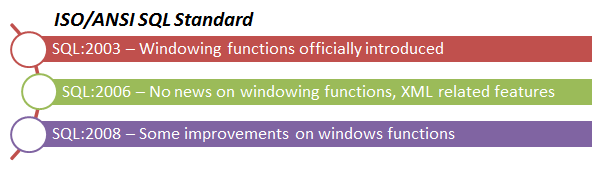

Funkcja okienna (analityczna) liczy agregację **na zbiorze wierszy powiązanym
z bieżącym wierszem** — bez zwijania wyniku jak `GROUP BY`. Ten sam wiersz
zostaje, a obok dostaje wartość policzoną 'w ramach działań na oknie'.

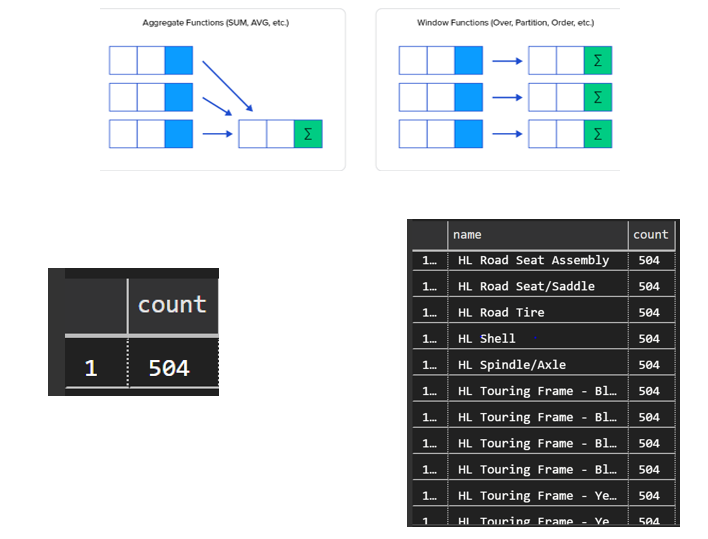

Precyzyjnie sytuacja wygląda następująco:

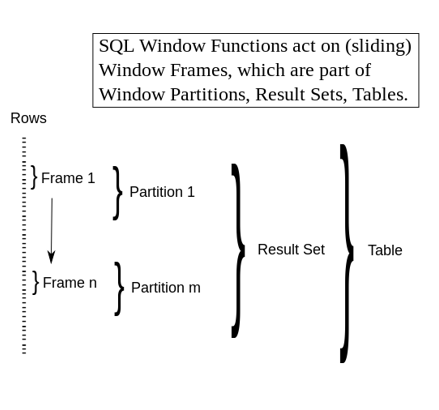

Słownik pojęć (za slajdami 47–51):

- **Result Set** — zbiór wierszy po `WHERE` (funkcje okienne działają **po**
  `FROM`/`WHERE`/`GROUP BY`/`HAVING`, tuż przed końcowym `ORDER BY`);
- **WINDOW PARTITION** — rozłączne grupy po `PARTITION BY` (brak = jedna
  partycja = cała tabela);
- **WINDOW ORDER** — porządek **wewnątrz partycji** (`ORDER BY` w `OVER`),
  niezależny od `ORDER BY` całego zapytania;
- **WINDOW FRAME** — podzbiór partycji dla bieżącego wiersza, definiowany
  `ROWS`/`RANGE`/`GROUPS`. Ramka jest inna dla każdego wiersza — to 'okno
  przesuwne'.

SQL03 wprowadza nową klauzulę WINDOW - jest ona wspierana zarówno przez Oracle Database (21c+), jak i MS SQL Server (2022+).

Składnia:
```sql 
WINDOW window_name AS (
  [ <PARTITION BY clause> ]
  [ <ORDER BY clause> ]
  [ <ROW or RANGE clause> ]
) [, other windows]
```
Przykładowo:
```sql
  SELECT someID, SUM() OVER win
  FROM tabela
  WINDOW win AS (PARTITION BY atrybut);
```

W wersji skróconej, nie definiujemy osobno okna i nie nadajemy mu nazwy, tylko bezpośrednio (inline) po wyrażeniu `OVER`.

> Warto pamiętać, iż operacje na oknach realizowane są pomiędzy 4-5, czyli zaraz po `HAVING` a przed `SELECT`:

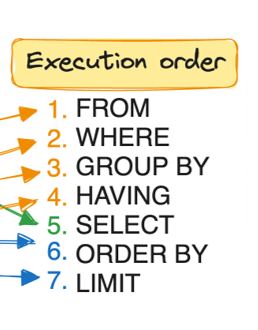

>**Domyślna ramka** (gdy jest `ORDER BY` w OVER):
`RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`
— czyli 'od początku partycji do bieżącego **wiersza i jego sobowtóry z
równymi wartościami ORDER BY**'. Bez `ORDER BY` w OVER ramka = cała partycja.


>**WAŻNE**: `OVER` wolno stosować **tylko w liście SELECT i ORDER BY**.
> Typowa **pułapka** to próba definiowania okna w WHERE/HAVING/GROUP BY. Jest to niemożliwe i gdy tylko spróbujesz filtrować po
> funkcji okienkowej — silnik odmówi. **Dlaczego?** Bo w momencie wykonywania `WHERE`, `GROUP BY` czy `HAVING` okna jeszcze nie istnieją:

> ```sql
> SELECT CustomerId, SUM(Total) OVER () FROM Invoice
> WHERE SUM(Total) OVER () > 100;
> ```
>
> - PostgreSQL: `ERROR: window functions are not allowed in WHERE`
> - MSSQL: `Msg 4108: Windowed functions can only appear in the SELECT or
>   ORDER BY clauses.`
> - Oracle: `ORA-00934: group function is not allowed here`
>   (a w `HAVING`: `ORA-30483: window functions are not allowed here`)
>
> **Rozwiązanie:** podzapytanie / CTE, a filtrowanie w zapytaniu zewnętrznym —
> zobacz sekcję 19 ("filtruj po oknie").
>
> Ciekawostka: niektóre silniki (Teradata, Snowflake, DuckDB) mają klauzulę
> `QUALIFY`, która filtruje **po** funkcjach okiennych bez CTE:
> `SELECT ... QUALIFY ROW_NUMBER() OVER (...) = 1`. W PostgreSQL/MSSQL/Oracle
> jej nie ma — wzorzec CTE pozostaje obowiązkowy.

### Klauzula WINDOW — nazwane okno, używane wielokrotnie

Standard SQL:2003, wsparcie: PostgreSQL, Oracle 21c+, MSSQL 2022+.
Jedna definicja — wiele użyć; do nazwanego okna można **dopisać ramkę**:

In [4]:
%%sql pg
-- WINDOW: nazwij definicję okna i użyj jej w kilku funkcjach
SELECT genre_id,
       COUNT(*)  OVER w AS utworow,
       ROUND(AVG(unit_price) OVER w, 2) AS srednia_cena
FROM track
WINDOW w AS (PARTITION BY genre_id)
ORDER BY genre_id, utworow
LIMIT 10;


Switching to connection 'pg'

10 rows affected.

genre_id,utworow,srednia_cena
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99


In [8]:
%%sql mssql
SELECT TOP (10) GenreId,
       COUNT(*) OVER w AS Utworow,
       CAST(AVG(UnitPrice) OVER w AS DECIMAL(10,2)) AS SredniaCena
FROM Track
WINDOW w AS (PARTITION BY GenreId)
ORDER BY GenreId, Utworow;


Switching to connection 'mssql'

GenreId,Utworow,SredniaCena
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99


In [11]:
%%sql oracle
SELECT  GenreId,
       COUNT(*) OVER w AS Utworow,
       ROUND(AVG(UnitPrice) OVER w, 2) AS SredniaCena
FROM Track
WINDOW w AS (PARTITION BY GenreId)
ORDER BY GenreId, Utworow
FETCH FIRST 10 ROWS ONLY;


genreid,utworow,sredniacena
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99
1,1297,0.99


In [12]:
%%sql pg
-- do nazwanego okna można DOCZEPIC dodatkowe elementy definicyjne ramki (w przykładzie nie uda się zmienić PARTITION)
SELECT name,
       unit_price,
       SUM(unit_price) OVER (w ORDER BY unit_price
                             ROWS BETWEEN 1 PRECEDING AND CURRENT ROW) AS suma_2
FROM track
WINDOW w AS (PARTITION BY genre_id)
ORDER BY name
LIMIT 8;


Switching to connection 'pg'

8 rows affected.

name,unit_price,suma_2
'Round Midnight,0.99,1.98
"""?""",1.99,3.98
"""40""",0.99,1.98
"""Eine Kleine Nachtmusik"" Serenade In G, K. 525: I. Allegro",0.99,1.98
#1 Zero,0.99,1.98
#9 Dream,0.99,1.98
(Anesthesia) Pulling Teeth,0.99,1.98
(Da Le) Yaleo,0.99,1.98


### Typy funkcji okiennych

| rodzina | funkcje | sekcja |
|---|---|---|
| agregujące | `SUM`, `AVG`, `COUNT`, `MIN`, `MAX` | 7 |
| rankingowe | `ROW_NUMBER`, `RANK`, `DENSE_RANK`, `NTILE` | 10 |
| pozycyjne | `LAG`, `LEAD`, `FIRST_VALUE`, `LAST_VALUE`, `NTH_VALUE` | 11 |
| percentylowe | `PERCENT_RANK`, `CUME_DIST`, `PERCENTILE_CONT/DISC` | 12 |

Jeszcze jedna pułapka teoretyczna: `SUM(SUM(x)) OVER (...)` — agregat okienny
**na wyniku grupowania** działa: najpierw GROUP BY zwija wiersze, potem okno
liczy po grupach (przykład w sekcji 7).

## 7. `OVER ()` i `PARTITION BY` — agregaty bez GROUP BY

`OVER ()` — pusta specyfikacja: **jedno okno = cała tabela**. Wynik równoważny
skalarnemu podzapytaniu `(SELECT SUM(...) FROM ...)` — tylko bez ponownego
skanowania tabeli.

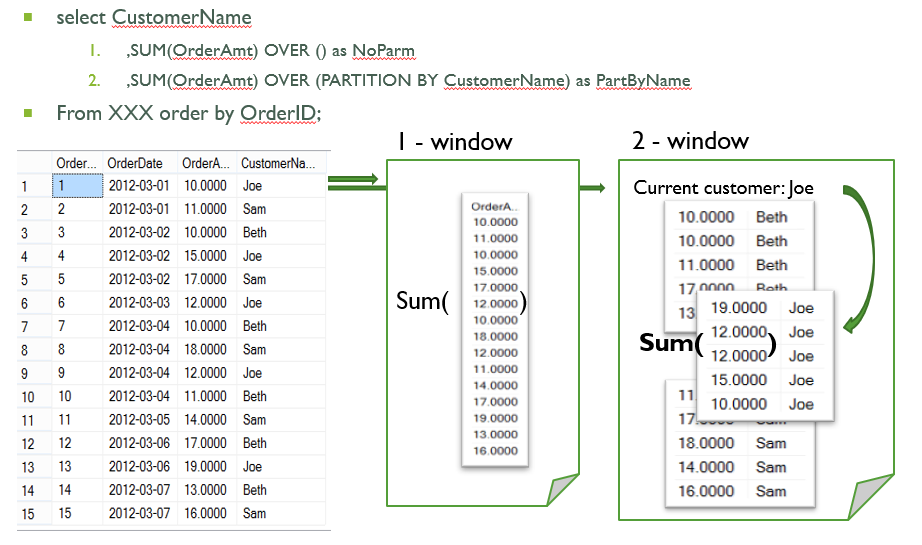

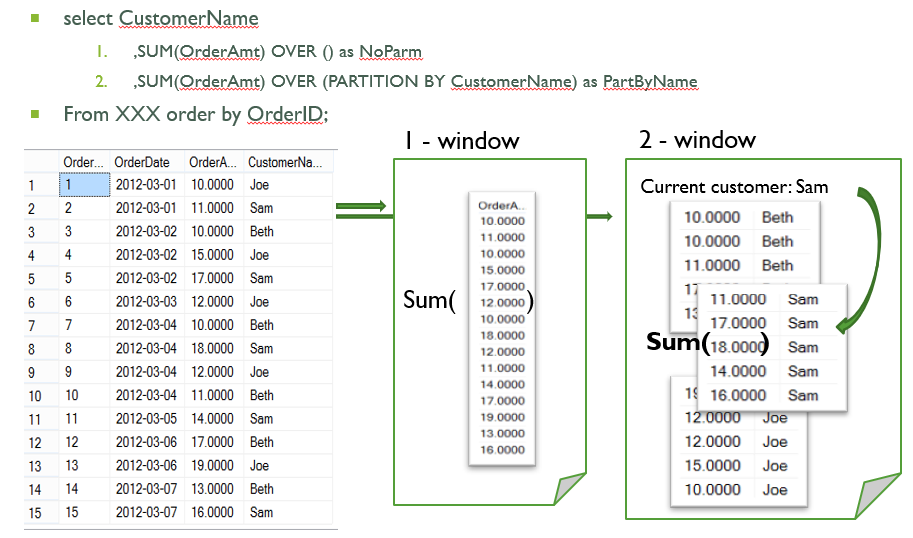

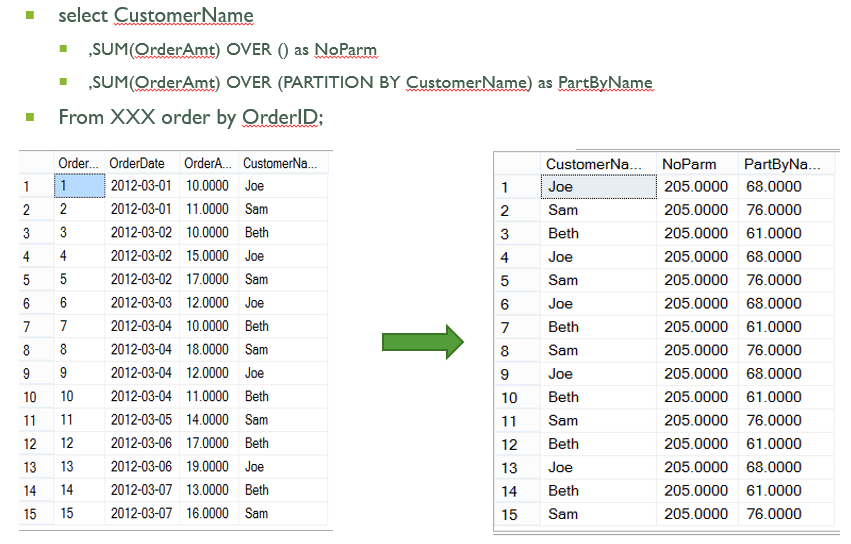

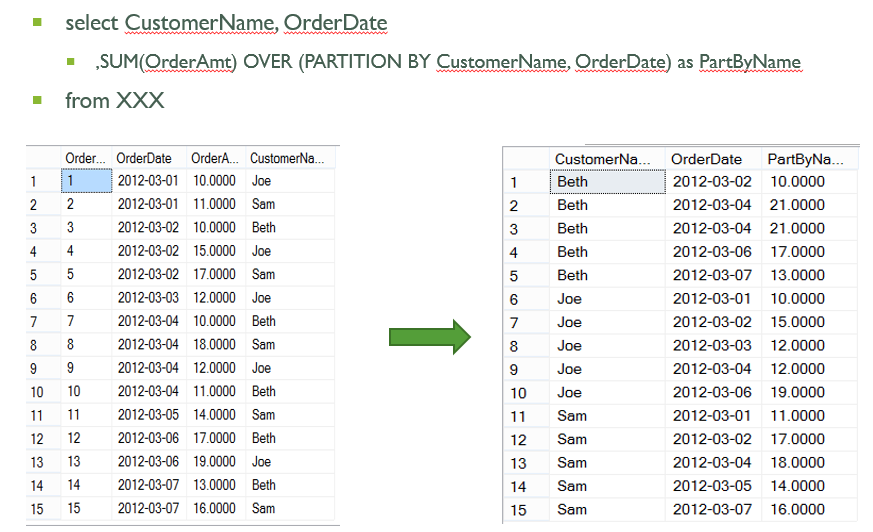

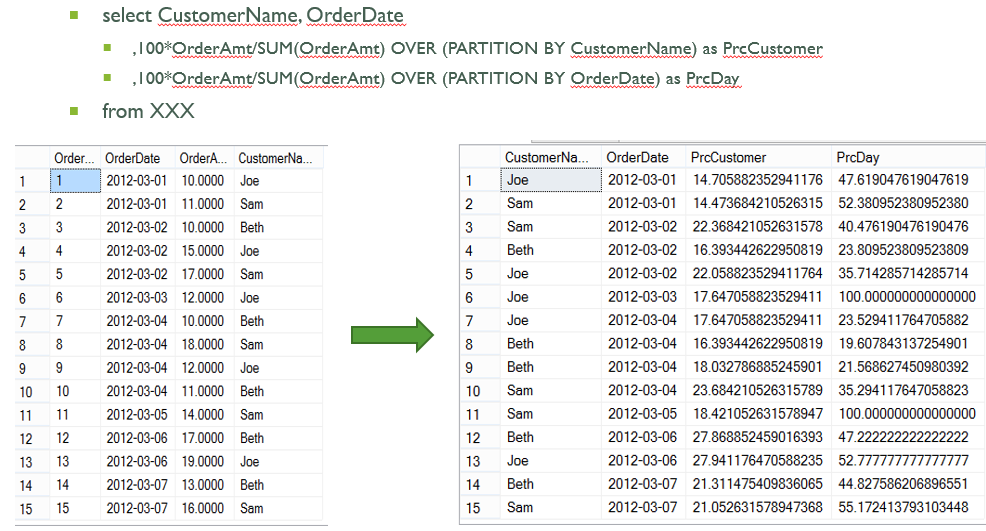

In [56]:
%%sql pg
-- OVER() = suma/srednia z całej tabeli w każdym wierszu (klient nr 2, 7 faktur)
SELECT invoice_id,
       invoice_date,
       total,
       ROUND(AVG(total) OVER (), 2)          AS srednia_firmowa,
       ROUND(100 * total / SUM(total) OVER (), 2) AS procent_firmy
FROM invoice
WHERE customer_id = 2
ORDER BY invoice_id;


7 rows affected.

invoice_id,invoice_date,total,srednia_firmowa,procent_firmy
1,2021-01-01 00:00:00,1.98,5.37,5.26
12,2021-02-11 00:00:00,13.86,5.37,36.84
67,2021-10-12 00:00:00,8.91,5.37,23.68
196,2023-05-19 00:00:00,1.98,5.37,5.26
219,2023-08-21 00:00:00,3.96,5.37,10.53
241,2023-11-23 00:00:00,5.94,5.37,15.79
293,2024-07-13 00:00:00,0.99,5.37,2.63


In [57]:
%%sql pg
-- odpowiednik "na piechotę" (podzapytanie skalarne) — wynik ten sam, plan gorszy
SELECT invoice_id,
       total,
       (SELECT ROUND(AVG(total), 2) FROM invoice)                     AS srednia_firmowa,
       ROUND(100 * total / (SELECT SUM(total) FROM invoice), 2)       AS procent_firmy
FROM invoice
WHERE customer_id = 2
ORDER BY invoice_id;


7 rows affected.

invoice_id,total,srednia_firmowa,procent_firmy
1,1.98,5.65,0.09
12,13.86,5.65,0.60
67,8.91,5.65,0.38
196,1.98,5.65,0.09
219,3.96,5.65,0.17
241,5.94,5.65,0.26
293,0.99,5.65,0.04


**PARTITION BY** — okno zawężone do grupy (tu: klienta). Porównaj udział
w sprzedaży klienta z udziałem w danym dniu:

In [58]:
%%sql pg
SELECT invoice_id,
       customer_id,
       invoice_date,
       total,
       ROUND(SUM(total) OVER (PARTITION BY customer_id), 2) AS suma_klienta,
       ROUND(100 * total / SUM(total) OVER (PARTITION BY customer_id), 1) AS proc_u_klienta,
       ROUND(100 * total / SUM(total) OVER (PARTITION BY invoice_date), 1) AS proc_w_dniu
FROM invoice
WHERE customer_id IN (2, 12)
ORDER BY customer_id, invoice_date;


14 rows affected.

invoice_id,customer_id,invoice_date,total,suma_klienta,proc_u_klienta,proc_w_dniu
1,2,2021-01-01 00:00:00,1.98,37.62,5.3,100.0
12,2,2021-02-11 00:00:00,13.86,37.62,36.8,100.0
67,2,2021-10-12 00:00:00,8.91,37.62,23.7,100.0
196,2,2023-05-19 00:00:00,1.98,37.62,5.3,100.0
219,2,2023-08-21 00:00:00,3.96,37.62,10.5,100.0
241,2,2023-11-23 00:00:00,5.94,37.62,15.8,100.0
293,2,2024-07-13 00:00:00,0.99,37.62,2.6,100.0
34,12,2021-05-23 00:00:00,0.99,37.62,2.6,100.0
155,12,2022-11-14 00:00:00,1.98,37.62,5.3,100.0
166,12,2022-12-25 00:00:00,13.86,37.62,36.8,100.0


In [59]:
%%sql oracle
SELECT InvoiceId,
       CustomerId,
       InvoiceDate,
       Total,
       ROUND(SUM(Total) OVER (PARTITION BY CustomerId), 2) AS SumaKlienta,
       ROUND(100 * Total / SUM(Total) OVER (PARTITION BY CustomerId), 1) AS ProcUKlienta,
       ROUND(100 * Total / SUM(Total) OVER (PARTITION BY TRUNC(InvoiceDate)), 1) AS ProcWDniu
FROM Invoice
WHERE CustomerId IN (2, 12)
ORDER BY CustomerId, InvoiceDate;


Switching to connection 'oracle'

invoiceid,customerid,invoicedate,total,sumaklienta,procuklienta,procwdniu
1,2,2021-01-01 00:00:00,1.98,37.62,5.3,100
12,2,2021-02-11 00:00:00,13.86,37.62,36.8,100
67,2,2021-10-12 00:00:00,8.91,37.62,23.7,100
196,2,2023-05-19 00:00:00,1.98,37.62,5.3,100
219,2,2023-08-21 00:00:00,3.96,37.62,10.5,100
241,2,2023-11-23 00:00:00,5.94,37.62,15.8,100
293,2,2024-07-13 00:00:00,0.99,37.62,2.6,100
34,12,2021-05-23 00:00:00,0.99,37.62,2.6,100
155,12,2022-11-14 00:00:00,1.98,37.62,5.3,100
166,12,2022-12-25 00:00:00,13.86,37.62,36.8,100


In [60]:
%%sql mssql
SELECT InvoiceId,
       CustomerId,
       InvoiceDate,
       Total,
       CAST(SUM(Total) OVER (PARTITION BY CustomerId) AS DECIMAL(10,2)) AS SumaKlienta,
       CAST(100. * Total / SUM(Total) OVER (PARTITION BY CustomerId) AS DECIMAL(10,1)) AS ProcUKlienta
FROM Invoice
WHERE CustomerId IN (2, 12)
ORDER BY CustomerId, InvoiceDate;


Switching to connection 'mssql'

InvoiceId,CustomerId,InvoiceDate,Total,SumaKlienta,ProcUKlienta
1,2,2021-01-01 00:00:00,1.98,37.62,5.3
12,2,2021-02-11 00:00:00,13.86,37.62,36.8
67,2,2021-10-12 00:00:00,8.91,37.62,23.7
196,2,2023-05-19 00:00:00,1.98,37.62,5.3
219,2,2023-08-21 00:00:00,3.96,37.62,10.5
241,2,2023-11-23 00:00:00,5.94,37.62,15.8
293,2,2024-07-13 00:00:00,0.99,37.62,2.6
34,12,2021-05-23 00:00:00,0.99,37.62,2.6
155,12,2022-11-14 00:00:00,1.98,37.62,5.3
166,12,2022-12-25 00:00:00,13.86,37.62,36.8


**Zestaw wszystkich agregatów okiennych naraz** (slajd 105): pozycje faktur
klienta 2 podsumowane bez GROUP BY:

In [61]:
%%sql pg
-- wszystkie podsumowania linii faktury bez GROUP BY (analogia do slajdu 105)
SELECT il.invoice_line_id,
       il.invoice_id,
       il.quantity,
       SUM(il.quantity) OVER (PARTITION BY il.invoice_id) AS pozycji_w_fakturze,
       AVG(il.quantity) OVER (PARTITION BY il.invoice_id) AS srednio,
       MIN(il.quantity) OVER (PARTITION BY il.invoice_id) AS minq,
       MAX(il.quantity) OVER (PARTITION BY il.invoice_id) AS maxq
FROM invoice_line il
WHERE il.invoice_id IN (1, 2)
ORDER BY il.invoice_id, il.invoice_line_id;


Switching to connection 'pg'

6 rows affected.

invoice_line_id,invoice_id,quantity,pozycji_w_fakturze,srednio,minq,maxq
1,1,1,2,1.00000000000000000000,1,1
2,1,1,2,1.00000000000000000000,1,1
3,2,1,4,1.00000000000000000000,1,1
4,2,1,4,1.00000000000000000000,1,1
5,2,1,4,1.00000000000000000000,1,1
6,2,1,4,1.00000000000000000000,1,1


**Agregat okna na agregacie** — `SUM(SUM(x)) OVER (...)` z `GROUP BY`
(slajd 104): najpierw zwijamy miesiące, **potem** liczymy okno po grupach:

In [62]:
%%sql mssql
-- suma narastająca MIESIĘCZNYCH sum sprzedaży w 2025 (SUM po SUM!)
SELECT MONTH(InvoiceDate)                  AS Miesiac,
       CAST(SUM(Total) AS DECIMAL(10,2))   AS SumaMies,
       CAST(SUM(SUM(Total)) OVER (ORDER BY MONTH(InvoiceDate)) AS DECIMAL(10,2)) AS Narastajaco
FROM Invoice
WHERE YEAR(InvoiceDate) = 2025
GROUP BY MONTH(InvoiceDate)
ORDER BY Miesiac;


Switching to connection 'mssql'

Miesiac,SumaMies,Narastajaco
1,37.62,37.62
2,27.72,65.34
3,37.62,102.96
4,33.66,136.62
5,37.62,174.24
6,37.62,211.86
7,37.62,249.48
8,37.62,287.10
9,37.62,324.72
10,37.62,362.34


In [63]:
%%sql pg
SELECT EXTRACT(MONTH FROM invoice_date) AS miesiac,
       ROUND(SUM(total), 2)             AS suma_mies,
       ROUND(SUM(SUM(total)) OVER (ORDER BY EXTRACT(MONTH FROM invoice_date)), 2) AS narastajaco
FROM invoice
WHERE EXTRACT(YEAR FROM invoice_date) = 2025
GROUP BY EXTRACT(MONTH FROM invoice_date)
ORDER BY miesiac;


Switching to connection 'pg'

12 rows affected.

miesiac,suma_mies,narastajaco
1,37.62,37.62
2,27.72,65.34
3,37.62,102.96
4,33.66,136.62
5,37.62,174.24
6,37.62,211.86
7,37.62,249.48
8,37.62,287.10
9,37.62,324.72
10,37.62,362.34


In [64]:
%%sql oracle
SELECT EXTRACT(MONTH FROM InvoiceDate) AS Miesiac,
       ROUND(SUM(Total), 2)            AS SumaMies,
       ROUND(SUM(SUM(Total)) OVER (ORDER BY EXTRACT(MONTH FROM InvoiceDate)), 2) AS Narastajaco
FROM Invoice
WHERE EXTRACT(YEAR FROM InvoiceDate) = 2025
GROUP BY EXTRACT(MONTH FROM InvoiceDate)
ORDER BY Miesiac;


Switching to connection 'oracle'

miesiac,sumamies,narastajaco
1,37.62,37.62
2,27.72,65.34
3,37.62,102.96
4,33.66,136.62
5,37.62,174.24
6,37.62,211.86
7,37.62,249.48
8,37.62,287.1
9,37.62,324.72
10,37.62,362.34


## 8. `OVER (ORDER BY ...)` — sumy narastające

Dodanie `ORDER BY` do `OVER` zmienia domyślną ramkę na `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW` — czyli **suma narastająca**
(od początku partycji do bieżącego wiersza). Porządek w oknie to **nie to samo** co porządek wyniku zapytania:

In [65]:
%%sql pg
-- suma narastająca po kolei faktur klienta 2 (A): wynik w kolejności listy
SELECT invoice_id,
       invoice_date,
       total,
       ROUND(SUM(total) OVER (PARTITION BY customer_id ORDER BY invoice_date, invoice_id), 2) AS narastajaco
FROM invoice
WHERE customer_id = 2
ORDER BY invoice_id;


Switching to connection 'pg'

7 rows affected.

invoice_id,invoice_date,total,narastajaco
1,2021-01-01 00:00:00,1.98,1.98
12,2021-02-11 00:00:00,13.86,15.84
67,2021-10-12 00:00:00,8.91,24.75
196,2023-05-19 00:00:00,1.98,26.73
219,2023-08-21 00:00:00,3.96,30.69
241,2023-11-23 00:00:00,5.94,36.63
293,2024-07-13 00:00:00,0.99,37.62


In [66]:
%%sql pg
-- (B): ta sama kolumna okienna, inny porządek WYNIKU — wartości się zgadzają,
-- bo okno ma własny ORDER BY
SELECT invoice_id,
       invoice_date,
       total,
       ROUND(SUM(total) OVER (PARTITION BY customer_id ORDER BY invoice_date, invoice_id), 2) AS narastajaco
FROM invoice
WHERE customer_id = 2
ORDER BY total DESC;


7 rows affected.

invoice_id,invoice_date,total,narastajaco
12,2021-02-11 00:00:00,13.86,15.84
67,2021-10-12 00:00:00,8.91,24.75
241,2023-11-23 00:00:00,5.94,36.63
219,2023-08-21 00:00:00,3.96,30.69
196,2023-05-19 00:00:00,1.98,26.73
1,2021-01-01 00:00:00,1.98,1.98
293,2024-07-13 00:00:00,0.99,37.62


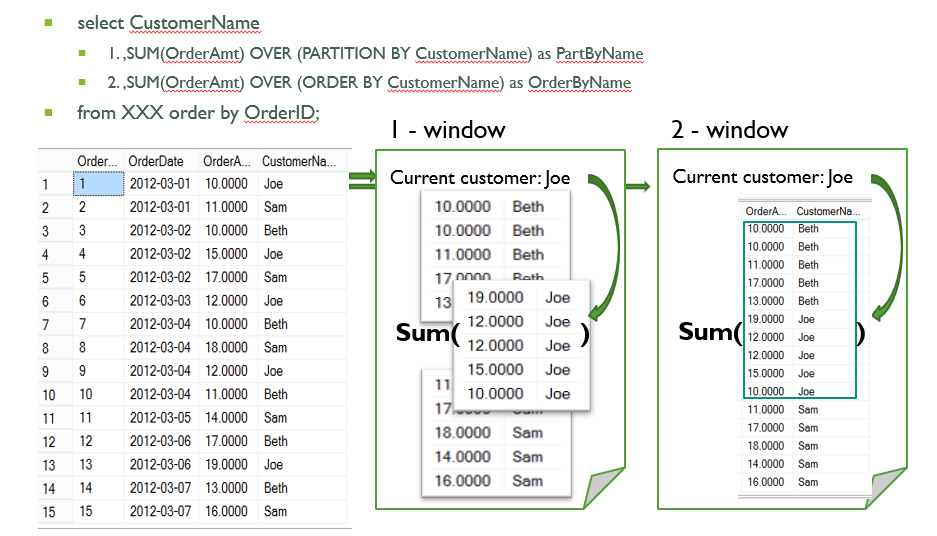

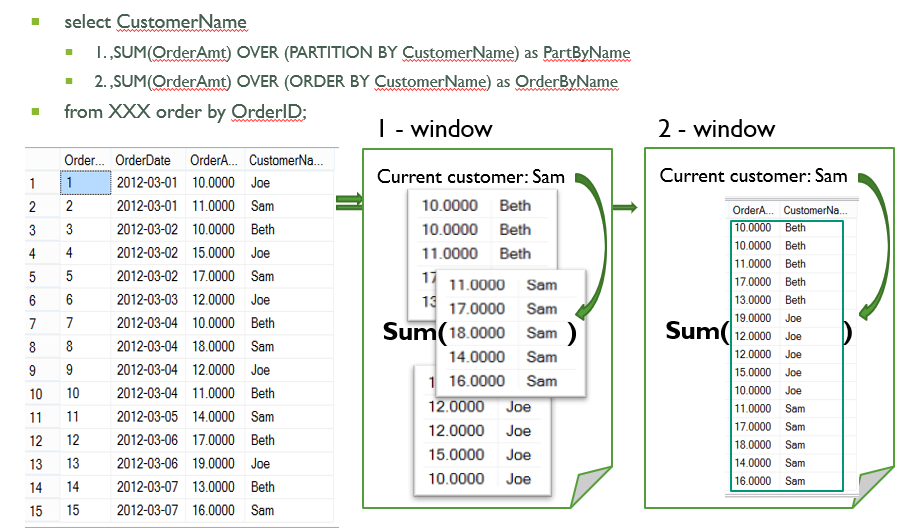

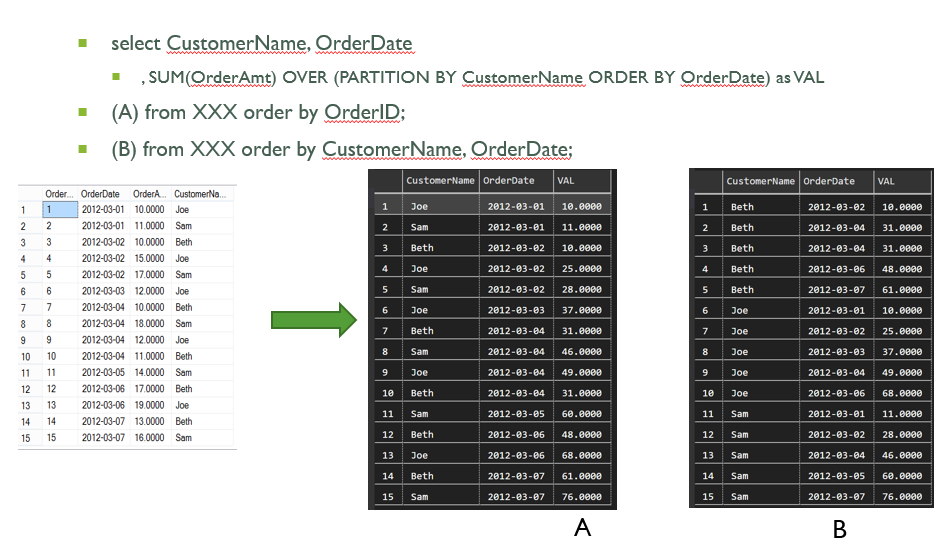

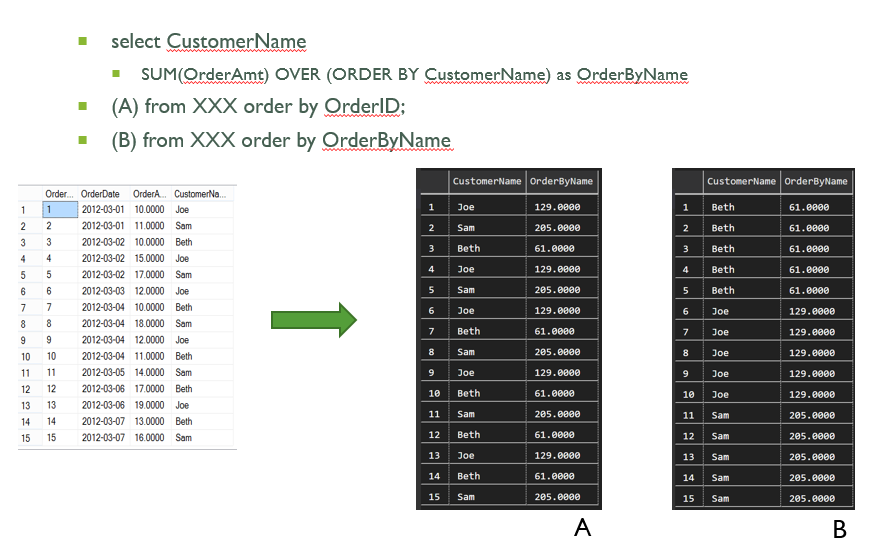

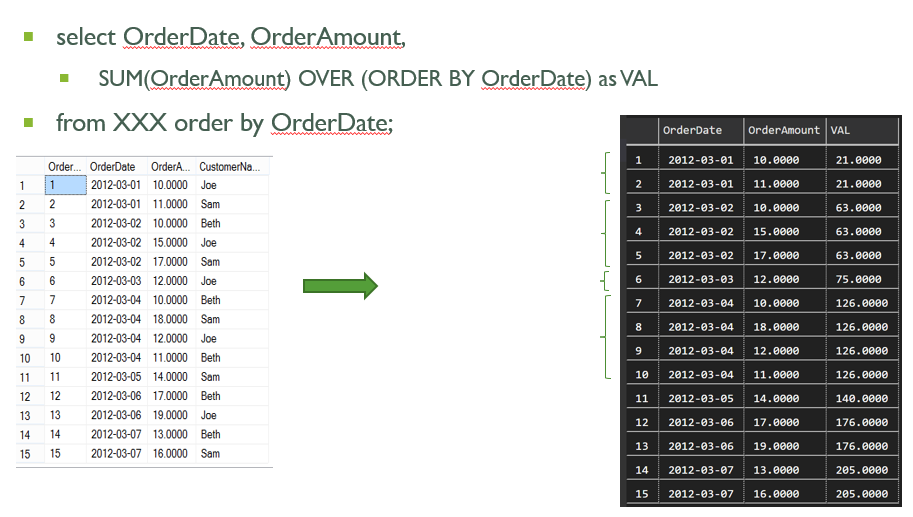

> **Pułapka (niedookreślony porządek).** Jeśli `ORDER BY` w okniu nie wyznacza
> porządku jednoznacznie (tu: same daty bez `invoice_id` — w jednym dniu może
> być kilka faktur), silnik may zwrócić wiersze "ex aequo" w dowolnej kolejności,
> a `ROW_NUMBER` przydzieli wtedy numery przypadkowo. **Zawsze dokładaj
> tie-breaker** (np. klucz główny).



### NULLS FIRST / NULLS LAST w oknie

Oracle jednoznacznie rozstrzyga kolejność NULL-i (`NULLS FIRST|LAST`, domyślnie NULLS LAST dla ASC)

MSSQL kładzie NULL-i na początku dla ASC (odwrotnie niż Oracle!) i **nie zna** składni `NULLS FIRST/LAST`

PG zna obie klauzule.

In [ ]:
%%sql oracle
-- NULL-e w oknie: NULLS FIRST / NULLS LAST (domyślnie ASC = NULLS LAST)
SELECT CustomerId,
       State,
       ROW_NUMBER() OVER (ORDER BY State NULLS FIRST)  AS RnNullsFirst,
       ROW_NUMBER() OVER (ORDER BY State NULLS LAST)   AS RnNullsLast
FROM Customer
WHERE SupportRepId = 4
FETCH FIRST 6 ROWS ONLY;


Switching to connection 'oracle'

customerid,state,rnnullsfirst,rnnullslast
5,None,1,11
49,None,2,16
40,None,3,15
39,None,4,14
35,None,5,13
4,None,6,12


In [68]:
%%sql pg
SELECT customer_id,
       state,
       ROW_NUMBER() OVER (ORDER BY state NULLS FIRST) AS rn_nulls_first,
       ROW_NUMBER() OVER (ORDER BY state NULLS LAST)  AS rn_nulls_last
FROM customer
WHERE support_rep_id = 4
LIMIT 6;


Switching to connection 'pg'

6 rows affected.

customer_id,state,rn_nulls_first,rn_nulls_last
27,AZ,11,1
20,CA,12,2
16,CA,13,3
13,DF,14,4
22,FL,15,5
23,MA,16,6


In [69]:
%%sql mssql
-- MSSQL: brak NULLS FIRST/LAST; NULL-e są PIERWSZE przy ASC (odwrotnie niż Oracle!)
SELECT TOP (6) CustomerId,
       State,
       ROW_NUMBER() OVER (ORDER BY State)       AS RnAsc,
       ROW_NUMBER() OVER (ORDER BY State DESC)  AS RnDesc
FROM Customer
WHERE SupportRepId = 4;


Switching to connection 'mssql'

CustomerId,State,RnAsc,RnDesc
26,TX,20,1
10,SP,19,2
55,NSW,18,3
32,MB,17,4
23,MA,16,5
22,FL,15,6


## 9. `ROWS` / `RANGE` / `GROUPS` — precyzyjne ramki

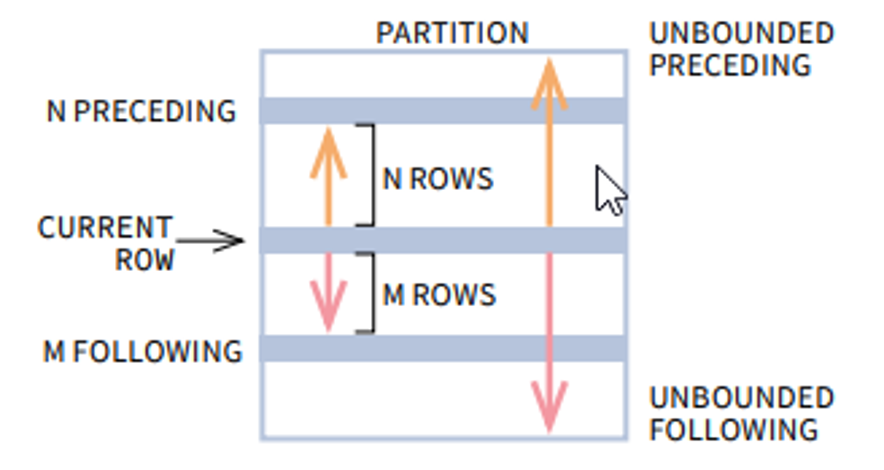

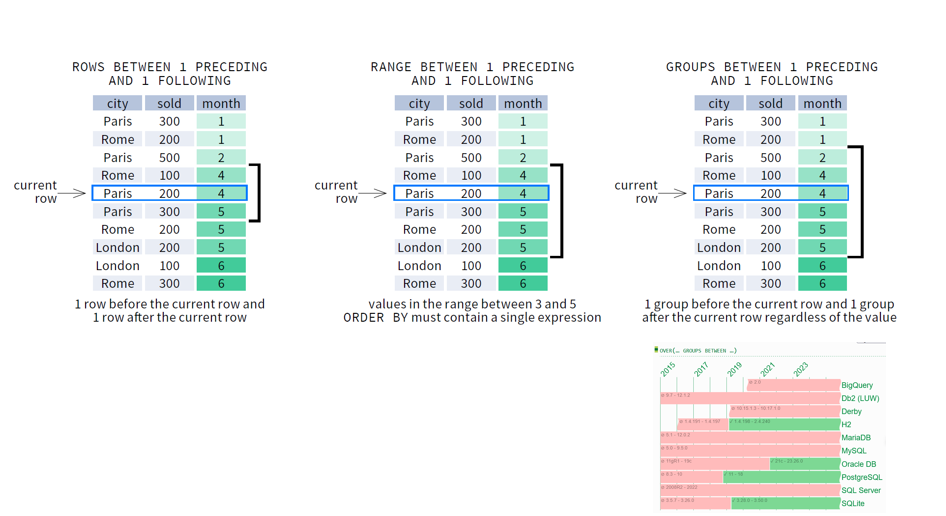

- **ROWS** — ramka liczy **fizyczne wiersze** (pozycje względem bieżącego);
- **RANGE** — ramka liczy **wartości** ORDER BY ('od wartości o n mniejszej
  do większej'); wszystkie wiersze z równą wartością ORDER BY wchodzą razem;
- **GROUPS** — ramka liczy **grupy wierszy o równej wartości** ORDER BY.


Niektórzy opisują ROWS jako operator fizyczny, podczas gdy RANGE jest operatorem logicznym, głównie dlatego, że:
- Klauzula ROWS ogranicza wiersze w partycji, określając stałą liczbę wierszy poprzedzających lub następujących po bieżącym wierszu.
- Klauzula RANGE logicznie ogranicza wiersze w partycji, określając zakres wartości w odniesieniu do wartości w bieżącym wierszu.
  - RANGE będzie zawierał te wiersze w ramce okna, które mają takie same wartości ORDER BY jak bieżący wiersz. 
- Wiersze poprzedzające i następujące po sobie są definiowane na podstawie kolejności w klauzuli ORDER BY.

Słowa kluczowe: `CURRENT ROW`, `UNBOUNDED PRECEDING/FOLLOWING`,
`n PRECEDING/FOLLOWING`, spójnik `BETWEEN ... AND ...`.

W tej klauzuli można użyć kilku słów kluczowych do zdefiniowania ramy okna używanej przez funkcje okna. 
- CURRENT ROW: 
  - identyfikuje bieżący wiersz
  - Można stosować z ROWS i RANGE
- UNBOUNDED PRECEDING: 
  - Początek partycji
  - Można stosować z ROWS i RANGE
- UNBOUNDED FOLLOWING: 
  - Koniec partycji
  - Można stosować z ROWS i RANGE
- n PRECEDING: 
  - Służy do określania liczby wierszy przed bieżącym wierszem
  - Można stosować tylko z ROWS.
  - Wiersze poprzedzające są definiowane na podstawie kolejności w klauzuli ORDER BY
- n FOLLOWING: 
  - Służy do określania liczby wierszy po bieżącym wierszu
  - Można stosować tylko z ROWS.
  - Wiersze następujące są definiowane na podstawie kolejności w klauzuli ORDER BY
- BETWEEN X AND Y 
  - Używane z opcją ROWS lub RANGE w celu określenia dolnego (początkowego) i górnego (końcowego) punktu granicznego okna.
  - X - <window frame bound> Definiuje punkt początkowy obwiedni
  - Y - <window frame bound> Definiuje punkt końcowy obwiedni
  - Górna granica nie może być mniejsza niż dolna granica.

Przy okazji **jedna ramka dla wszystkich**: bez `BETWEEN` podajesz tylko początek (`` ... AND CURRENT ROW`` domyślnie).

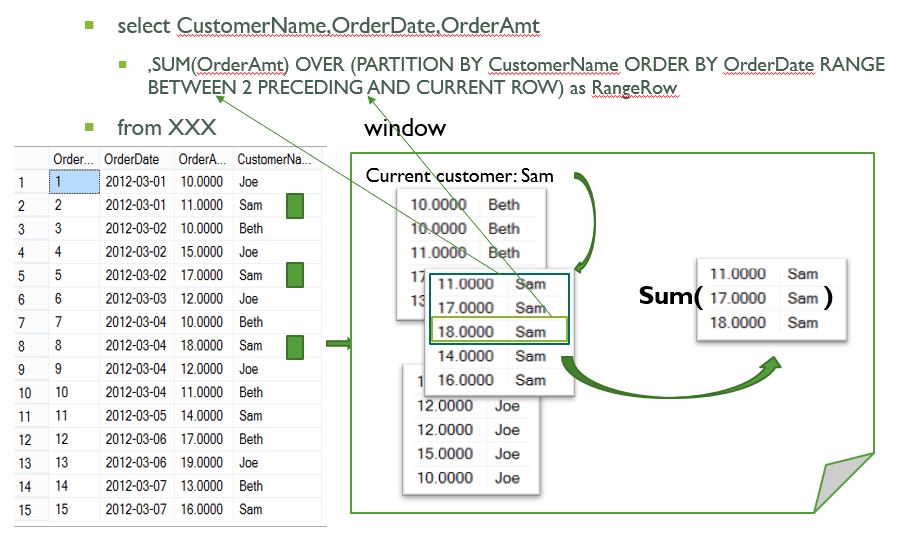

Do zabawy małą, kontrolowaną tabelką (VALUES) — jeden klient, kilka płatności:

**PostgreSQL:**

In [13]:
%%sql pg
-- tabelka próbna: d = dzień płatności, kwota
WITH platnosci AS (
  SELECT * FROM (VALUES (1, 10), (2, 20), (2, 35), (3, 30), (5, 50)) v(d, kwota)
)
SELECT d, kwota,
       SUM(kwota) OVER (ORDER BY d ROWS BETWEEN 1 PRECEDING AND CURRENT ROW) AS rows_1p,
       SUM(kwota) OVER (ORDER BY d RANGE BETWEEN 1 PRECEDING AND 1 FOLLOWING) AS range_wart,
       SUM(kwota) OVER (ORDER BY d GROUPS BETWEEN 1 PRECEDING AND CURRENT ROW) AS groups_1p
FROM platnosci
ORDER BY d, kwota;


5 rows affected.

d,kwota,rows_1p,range_wart,groups_1p
1,10,10,65,10
2,20,30,95,65
2,35,55,95,65
3,30,65,85,85
5,50,80,50,80


In [71]:
%%sql oracle
WITH platnosci AS (
  SELECT 1 d, 10 kwota FROM DUAL UNION ALL
  SELECT 2 d, 20 kwota FROM DUAL UNION ALL
  SELECT 2 d, 35 kwota FROM DUAL UNION ALL
  SELECT 3 d, 30 kwota FROM DUAL UNION ALL
  SELECT 5 d, 50 kwota FROM DUAL
)
SELECT d, kwota,
       SUM(kwota) OVER (ORDER BY d ROWS BETWEEN 1 PRECEDING AND CURRENT ROW)    AS rows_1p,
       SUM(kwota) OVER (ORDER BY d RANGE BETWEEN 1 PRECEDING AND 1 FOLLOWING)   AS range_wart,
       SUM(kwota) OVER (ORDER BY d GROUPS BETWEEN 1 PRECEDING AND CURRENT ROW)  AS groups_1p
FROM platnosci
ORDER BY d, kwota;


Switching to connection 'oracle'

d,kwota,rows_1p,range_wart,groups_1p
1,10,10,65,10
2,20,30,95,65
2,35,55,95,65
3,30,65,85,85
5,50,80,50,80


In [72]:
%%sql mssql
WITH platnosci AS (
  SELECT * FROM (VALUES (1, 10), (2, 20), (2, 35), (3, 30), (5, 50)) v(d, kwota)
)
SELECT d, kwota,
       SUM(kwota) OVER (ORDER BY d ROWS BETWEEN 1 PRECEDING AND CURRENT ROW) AS rows_1p
FROM platnosci
ORDER BY d, kwota;


Switching to connection 'mssql'

d,kwota,rows_1p
1,10,10
2,20,55
2,35,45
3,30,50
5,50,80


Zwróć uwagę na wiersz `d=2`:
- `ROWS 1 PRECEDING`: okno = 1 fizyczny wiersz przed + bieżący (20+10=30, 35+20=55);
- `RANGE 1 PRECEDING AND 1 FOLLOWING`: okno po **wartościach** — d=2 obejmuje
  d=1..3, czyli 10+20+35+30=95 dla obu wierszy d=2 (wraz z sobowtórami!);
- `GROUPS 1 PRECEDING`: poprzednia **grupa** (d=1) + własna grupa (d=2):
  10+20+35=65 dla obu wierszy d=2.

> **Pułapka (MSSQL `RANGE` z offsetem).** `RANGE BETWEEN n PRECEDING ...`
> w MSSQL **nie istnieje** — `Msg 4194: RANGE is only supported with UNBOUNDED
> and CURRENT ROW window frame delimiters`. W MSSQL ramki wartościowe robimy
> tylko przez `ROWS` albo przez samo `RANGE UNBOUNDED/CURRENT`.
> `GROUPS` też brak (`Incorrect syntax near 'GROUPS'`) — to domena PG/Oracle.

### RANGE na wartościach — intuicja (slajdy 93–95)

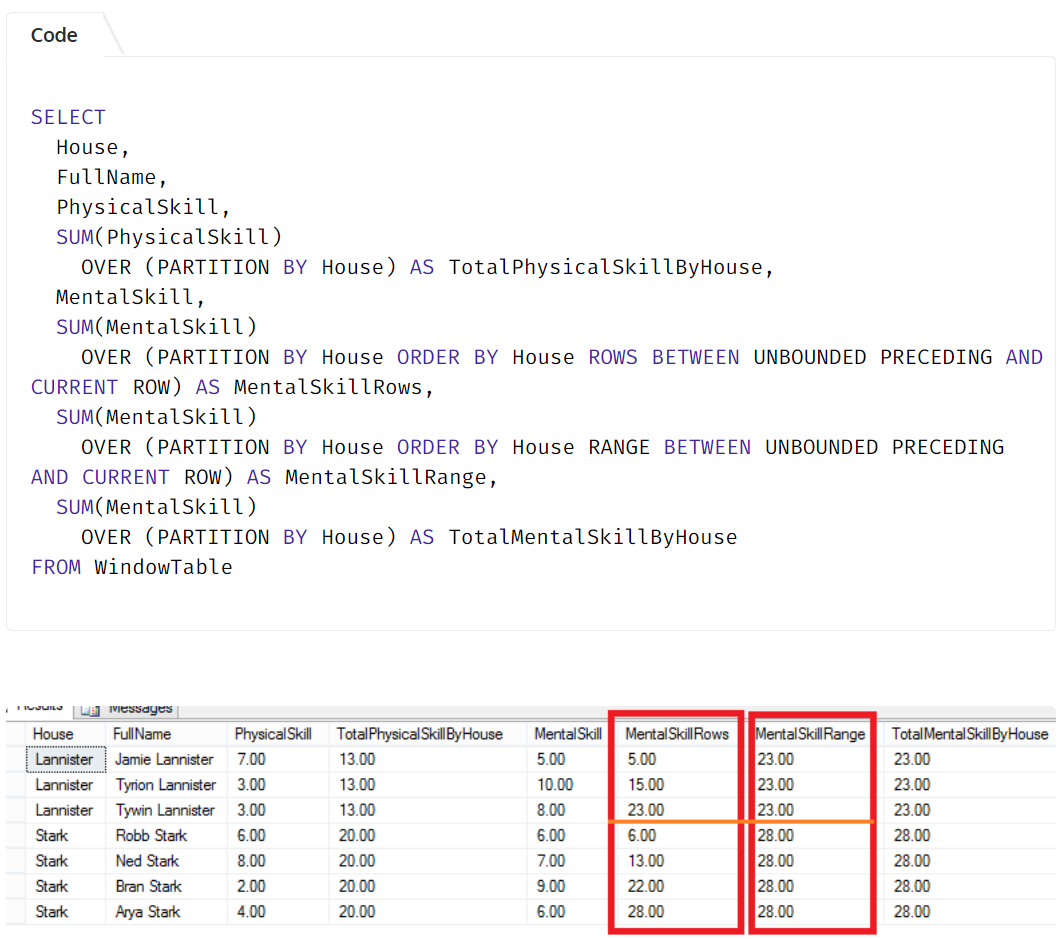

`RANGE BETWEEN 100 PRECEDING AND 50 FOLLOWING` znaczy: **wiersze, których
wartość ORDER BY mieści się w przedziale** `[bieżąca-100, bieżąca+50]`.
Kolumna ORDER BY musi być numeryczna, datowa lub interwałowa.

In [14]:
%%sql pg
-- RANGE na wartości: kto w promieniu +/-1 minuty utworu?
WITH utw AS (
  SELECT track_id, name, milliseconds / 60000.0 AS minuty
  FROM track
  WHERE album_id = 1
)
SELECT name, ROUND(minuty, 1) AS min,
       COUNT(*) OVER (ORDER BY minuty
                      RANGE BETWEEN 1 PRECEDING AND 1 FOLLOWING) AS podobnych,
       ROUND(SUM(minuty) OVER (ORDER BY minuty
                      RANGE BETWEEN 1 PRECEDING AND 1 FOLLOWING), 1) AS suma_min
FROM utw
ORDER BY minuty
LIMIT 10;


10 rows affected.

name,min,podobnych,suma_min
C.O.D.,3.3,6,21.0
Snowballed,3.4,6,21.0
Put The Finger On You,3.4,8,29.8
Night Of The Long Knives,3.4,8,29.8
Inject The Venom,3.5,8,29.8
Let's Get It Up,3.9,9,34.3
Breaking The Rules,4.4,7,27.6
Evil Walks,4.4,7,27.6
Spellbound,4.5,4,17.2
For Those About To Rock (We Salute You),5.7,1,5.7


In [74]:
%%sql oracle
WITH utw AS (
  SELECT TRACKID AS TrackId, NAME AS Utwor,
         ROUND(Milliseconds / 60000.0, 1) AS Minuty
  FROM Track
  WHERE AlbumId = 1
)
SELECT Utwor, Minuty,
       COUNT(*) OVER (ORDER BY Minuty
                      RANGE BETWEEN 1 PRECEDING AND 1 FOLLOWING) AS PodobnyCzas,
       ROUND(SUM(Minuty) OVER (ORDER BY Minuty
                      RANGE BETWEEN 1 PRECEDING AND 1 FOLLOWING), 1) AS SumaMin
FROM utw
ORDER BY Minuty
FETCH FIRST 10 ROWS ONLY;


Switching to connection 'oracle'

utwor,minuty,podobnyczas,sumamin
C.O.D.,3.3,6,20.9
Put The Finger On You,3.4,8,29.7
Snowballed,3.4,8,29.7
Night Of The Long Knives,3.4,8,29.7
Inject The Venom,3.5,9,34.2
Let's Get It Up,3.9,9,34.2
Evil Walks,4.4,8,30.9
Breaking The Rules,4.4,8,30.9
Spellbound,4.5,5,20.7
For Those About To Rock (We Salute You),5.7,1,5.7


### Ramki na datach — średnia krocząca 3 dni (RANGE z interwałem)

Średnia z dni `[d-2, d]` — niezależnie od tego, ile faktur dziennie wpadło.
W PG ramkę datową wyraża `INTERVAL`, w Oracle `NUMTODSINTERVAL`; MSSQL —
patrz pułapka wyżej — musi użyć `ROWS` po konkretnych dniach.

In [75]:
%%sql pg
-- średnia krocząca 3-dniowa po dacie (klient 2)
SELECT d::date AS dzien,
       kwota,
       ROUND(AVG(kwota) OVER (ORDER BY d
              RANGE BETWEEN INTERVAL '2 days' PRECEDING AND CURRENT ROW), 2) AS srednia_3d
FROM (SELECT DISTINCT invoice_date AS d, total AS kwota
      FROM invoice WHERE customer_id = 2) v
ORDER BY d;


Switching to connection 'pg'

7 rows affected.

dzien,kwota,srednia_3d
2021-01-01,1.98,1.98
2021-02-11,13.86,13.86
2021-10-12,8.91,8.91
2023-05-19,1.98,1.98
2023-08-21,3.96,3.96
2023-11-23,5.94,5.94
2024-07-13,0.99,0.99


In [76]:
%%sql oracle
SELECT TRUNC(InvoiceDate) AS Dzien,
       Total              AS Kwota,
       ROUND(AVG(Total) OVER (ORDER BY TRUNC(InvoiceDate)
              RANGE BETWEEN NUMTODSINTERVAL(2,'DAY') PRECEDING AND CURRENT ROW), 2) AS Srednia3d
FROM Invoice
WHERE CustomerId = 2
ORDER BY InvoiceDate;


Switching to connection 'oracle'

dzien,kwota,srednia3d
2021-01-01 00:00:00,1.98,1.98
2021-02-11 00:00:00,13.86,13.86
2021-10-12 00:00:00,8.91,8.91
2023-05-19 00:00:00,1.98,1.98
2023-08-21 00:00:00,3.96,3.96
2023-11-23 00:00:00,5.94,5.94
2024-07-13 00:00:00,0.99,0.99


In [77]:
%%sql mssql
-- MSSQL: brak RANGE z offsetem -> przybliżenie ROWS po dniu (okno 3 wiersze = 3 dni)
WITH dz AS (
  SELECT CAST(InvoiceDate AS date) AS Dzien,
         CAST(SUM(Total) AS DECIMAL(10,2)) AS Kwota
  FROM Invoice
  WHERE CustomerId = 2 AND YEAR(InvoiceDate) = 2021
  GROUP BY CAST(InvoiceDate AS date)
)
SELECT Dzien, Kwota,
       CAST(AVG(Kwota) OVER (ORDER BY Dzien
              ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS DECIMAL(10,2)) AS Srednia_wierszy
FROM dz
ORDER BY Dzien;


Switching to connection 'mssql'

Dzien,Kwota,Srednia_wierszy
2021-01-01,1.98,1.98
2021-02-11,13.86,7.92
2021-10-12,8.91,8.25


>Zapytanie MSSQL liczy coś innego niż PG/Oracle: średnia z **3 ostatnich
>wierszy** (dni z fakturami), a nie z **3 dni kalendarzowych**. To typowy
>kompromis dialektowy — i argument, by 'biznesowe' definicje okien zapisywać
>w jednym miejscu aplikacji, nie w SQL trzech dialektów.

### GROUPS — ramka po grupach równych wartości

Ile faktur weszło do ramki 'bieżąca grupa + jedna poprzednia'? Przy miesięcznych
sumach 2025 bardzo widać semantykę grup:

In [78]:
%%sql pg
-- GROUPS: bieżąca "grupa" (miesiąc) + poprzednia grupa = okno 2-miesięczne
SELECT m, s,
       SUM(s) OVER (ORDER BY m GROUPS BETWEEN 1 PRECEDING AND CURRENT ROW) AS suma_2gr,
       SUM(s) OVER (ORDER BY m ROWS  BETWEEN 1 PRECEDING AND CURRENT ROW)  AS suma_2w
FROM (SELECT EXTRACT(MONTH FROM invoice_date) AS m,
             ROUND(SUM(total), 2)             AS s
      FROM invoice
      WHERE EXTRACT(YEAR FROM invoice_date) = 2025
      GROUP BY 1) t
ORDER BY m;


Switching to connection 'pg'

12 rows affected.

m,s,suma_2gr,suma_2w
1,37.62,37.62,37.62
2,27.72,65.34,65.34
3,37.62,65.34,65.34
4,33.66,71.28,71.28
5,37.62,71.28,71.28
6,37.62,75.24,75.24
7,37.62,75.24,75.24
8,37.62,75.24,75.24
9,37.62,75.24,75.24
10,37.62,75.24,75.24


In [79]:
%%sql oracle
SELECT M, S,
       ROUND(SUM(S) OVER (ORDER BY M GROUPS BETWEEN 1 PRECEDING AND CURRENT ROW), 2) AS Suma2gr,
       ROUND(SUM(S) OVER (ORDER BY M ROWS  BETWEEN 1 PRECEDING AND CURRENT ROW), 2)  AS Suma2w
FROM (SELECT EXTRACT(MONTH FROM InvoiceDate) AS M,
             SUM(Total)                      AS S
      FROM Invoice
      WHERE EXTRACT(YEAR FROM InvoiceDate) = 2025
      GROUP BY EXTRACT(MONTH FROM InvoiceDate))
ORDER BY M;


Switching to connection 'oracle'

m,s,suma2gr,suma2w
1,37.62,37.62,37.62
2,27.72,65.34,65.34
3,37.62,65.34,65.34
4,33.66,71.28,71.28
5,37.62,71.28,71.28
6,37.62,75.24,75.24
7,37.62,75.24,75.24
8,37.62,75.24,75.24
9,37.62,75.24,75.24
10,37.62,75.24,75.24


### Domyślna ramka — RANGE vs ROWS na duplikatach

Bez jawnie podanej ramki (z ORDER BY) dostajesz `RANGE ... CURRENT ROW`:
wiersze o **równej wartości ORDER BY** zawsze wchodzą razem. To najczęstsze
źródło 'dziwnych' sum:

In [80]:
%%sql pg
-- dwa utwory o identycznej cenie = sobowtóry w domyślnym RANGE
SELECT name, unit_price,
       SUM(unit_price) OVER (ORDER BY unit_price)                    AS domyslnie_range,
       SUM(unit_price) OVER (ORDER BY unit_price ROWS UNBOUNDED PRECEDING) AS jawne_rows
FROM track
WHERE genre_id = 1
ORDER BY unit_price, name
LIMIT 8;


Switching to connection 'pg'

8 rows affected.

name,unit_price,domyslnie_range,jawne_rows
"""40""",0.99,1284.03,1183.05
(Da Le) Yaleo,0.99,1284.03,160.38
(Oh) Pretty Woman,0.99,1284.03,1198.89
(Wish I Could) Hideaway,0.99,1284.03,210.87
1/2 Full,0.99,1284.03,746.46
19th Nervous Breakdown,0.99,1284.03,1031.58
2 A.M.,0.99,1284.03,458.37
2 Minutes To Midnight,0.99,1284.03,434.61


> **Dobra praktyka** 
> Okna porządkowe zawsze pisz z **jednoznacznym ORDER BY** i **jawną ramką** (`ROWS ...`), nawet gdyby domyślna pasowała — czytelnik (i przyszły ty) nie musi zgadywać, czy chodziło o wiersze, czy wartości. Testuj każdą funkcję okienną osobno, dokumentuj co jest PARTITION.

## 10. Funkcje rankingowe — ROW_NUMBER, RANK, DENSE_RANK, NTILE

- `ROW_NUMBER()` — kolejne numery; pełny porządek (tie-breaker konieczny!);
- `RANK()` — określa pozycję wiersza w partycji w rankingu sportowym tzn. miejsca ex aequo powodują opuszczenie (brak) kolejnego miejsca/miejsc w numeracji - miejsca ex aequo, a **po nich dziura** (1,1,3 — klasyka sportowa);
- `DENSE_RANK()` — działa tak samo jak RANK(), tylko po miejscach ex aequo następuje kolejne miejsce w numeracji - ex aequo bez dziur (1,1,2);
- `NTILE(n)` — dzieli partycję na n możliwie równych wiaderek (kwartyle, decyle...);
- `PERCENT_RANK()` – określa w wartościach od 0 do 1 udział danego wiersza w stosunku do poprzedzających go wierszy partycji,
- `CUME_DIST()` – działa tak samo jak PERCENT_RANK(), tylko określany jest udział wiersza wobec poprzedzających go wierszy z nim włącznie. 

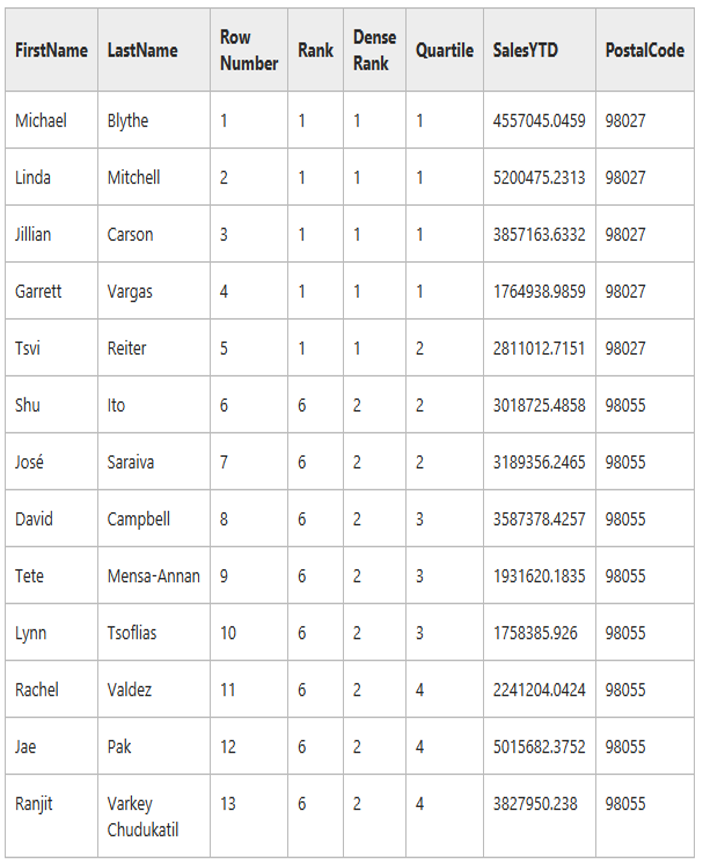

In [18]:
%%sql pg
-- rankingi faktur 2025 po kwocie: duplikaty kwot dadzą ex aequo
SELECT invoice_id,
       total,
       ROW_NUMBER() OVER (ORDER BY total DESC, invoice_id) AS rn,
       RANK()       OVER (ORDER BY total DESC)             AS rnk,
       DENSE_RANK() OVER (ORDER BY total DESC)             AS drnk,
       PERCENT_RANK() OVER (ORDER BY total DESC)             AS pcrnk,
       CUME_DIST() OVER (ORDER BY total DESC)             AS crnk
FROM invoice
WHERE EXTRACT(YEAR FROM invoice_date) = 2025
ORDER BY total DESC, invoice_id
LIMIT 12;


12 rows affected.

invoice_id,total,rn,rnk,drnk,pcrnk,crnk
404,25.86,1,1,1,0.0,0.0125
334,13.86,2,2,2,0.012658227848101266,0.15
341,13.86,3,2,2,0.012658227848101266,0.15
348,13.86,4,2,2,0.012658227848101266,0.15
355,13.86,5,2,2,0.012658227848101266,0.15
362,13.86,6,2,2,0.012658227848101266,0.15
369,13.86,7,2,2,0.012658227848101266,0.15
376,13.86,8,2,2,0.012658227848101266,0.15
383,13.86,9,2,2,0.012658227848101266,0.15
390,13.86,10,2,2,0.012658227848101266,0.15


In [20]:
%%sql oracle
SELECT InvoiceId,
       Total,
       ROW_NUMBER() OVER (ORDER BY Total DESC, InvoiceId) AS Rn,
       RANK()       OVER (ORDER BY Total DESC)            AS Rnk,
       DENSE_RANK() OVER (ORDER BY Total DESC)            AS Drnk,
       PERCENT_RANK() OVER (ORDER BY total DESC)             AS pcrnk,
       CUME_DIST() OVER (ORDER BY total DESC)             AS crnk
FROM Invoice
WHERE EXTRACT(YEAR FROM InvoiceDate) = 2025
ORDER BY Total DESC, InvoiceId
FETCH FIRST 12 ROWS ONLY;


invoiceid,total,rn,rnk,drnk,pcrnk,crnk
404,25.86,1,1,1,0,0.0125
334,13.86,2,2,2,0.012658227848101265822784810126582278481,0.15
341,13.86,3,2,2,0.012658227848101265822784810126582278481,0.15
348,13.86,4,2,2,0.012658227848101265822784810126582278481,0.15
355,13.86,5,2,2,0.012658227848101265822784810126582278481,0.15
362,13.86,6,2,2,0.012658227848101265822784810126582278481,0.15
369,13.86,7,2,2,0.012658227848101265822784810126582278481,0.15
376,13.86,8,2,2,0.012658227848101265822784810126582278481,0.15
383,13.86,9,2,2,0.012658227848101265822784810126582278481,0.15
390,13.86,10,2,2,0.012658227848101265822784810126582278481,0.15


In [21]:
%%sql mssql
SELECT TOP (12) InvoiceId,
       Total,
       ROW_NUMBER() OVER (ORDER BY Total DESC, InvoiceId) AS Rn,
       RANK()       OVER (ORDER BY Total DESC)            AS Rnk,
       DENSE_RANK() OVER (ORDER BY Total DESC)            AS Drnk,
       PERCENT_RANK() OVER (ORDER BY total DESC)             AS pcrnk,
       CUME_DIST() OVER (ORDER BY total DESC)             AS crnk
FROM Invoice
WHERE YEAR(InvoiceDate) = 2025
ORDER BY Total DESC, InvoiceId;


Switching to connection 'mssql'

InvoiceId,Total,Rn,Rnk,Drnk,pcrnk,crnk
404,25.86,1,1,1,0.0,0.0125
334,13.86,2,2,2,0.012658227848101266,0.15
341,13.86,3,2,2,0.012658227848101266,0.15
348,13.86,4,2,2,0.012658227848101266,0.15
355,13.86,5,2,2,0.012658227848101266,0.15
362,13.86,6,2,2,0.012658227848101266,0.15
369,13.86,7,2,2,0.012658227848101266,0.15
376,13.86,8,2,2,0.012658227848101266,0.15
383,13.86,9,2,2,0.012658227848101266,0.15
390,13.86,10,2,2,0.012658227848101266,0.15


**Top-N z ex aequo** — `WITH TIES` szanuje remisy (wszędzie od 2021/2022, w PG
od 13):

In [22]:
%%sql mssql
-- TOP (n) WITH TIES: zwróci więcej niż 3, jeśli są remisy na granicy
SELECT TOP (3) WITH TIES LastName, HireDate
FROM Employee
ORDER BY HireDate;


LastName,HireDate
Peacock,2002-04-01 00:00:00
Edwards,2002-05-01 00:00:00
Adams,2002-08-14 00:00:00


In [85]:
%%sql oracle
SELECT LastName, HireDate
FROM Employee
ORDER BY HireDate
FETCH FIRST 3 ROWS WITH TIES;


Switching to connection 'oracle'

lastname,hiredate
Peacock,2002-04-01 00:00:00
Edwards,2002-05-01 00:00:00
Adams,2002-08-14 00:00:00


In [86]:
%%sql pg
SELECT last_name, hire_date
FROM employee
ORDER BY hire_date
FETCH FIRST 3 ROWS WITH TIES;


Switching to connection 'pg'

3 rows affected.

last_name,hire_date
Peacock,2002-04-01 00:00:00
Edwards,2002-05-01 00:00:00
Adams,2002-08-14 00:00:00


**NTILE** — kwartyle kwot faktur (2025), w partycji kraju:

In [87]:
%%sql pg
SELECT billing_country, total,
       NTILE(4) OVER (ORDER BY total)              AS kwartyl_globalny,
       NTILE(4) OVER (PARTITION BY billing_country
                      ORDER BY total)              AS kwartyl_w_kraju,
       ROW_NUMBER() OVER (PARTITION BY billing_country
                      ORDER BY total, invoice_id)  AS rn_w_kraju
FROM invoice
WHERE billing_country IN ('USA', 'Canada')
ORDER BY billing_country, total, rn_w_kraju
LIMIT 15;


15 rows affected.

billing_country,total,kwartyl_globalny,kwartyl_w_kraju,rn_w_kraju
Canada,0.99,1,1,1
Canada,0.99,1,1,2
Canada,0.99,1,1,3
Canada,0.99,1,1,4
Canada,0.99,1,1,5
Canada,0.99,1,1,6
Canada,0.99,1,1,7
Canada,0.99,1,1,8
Canada,1.98,2,1,9
Canada,1.98,2,1,10


In [88]:
%%sql mssql
SELECT TOP (15) BillingCountry, Total,
       NTILE(4) OVER (ORDER BY Total)             AS KwartylGlobalny,
       NTILE(4) OVER (PARTITION BY BillingCountry
                      ORDER BY Total)             AS KwartylWKraju,
       ROW_NUMBER() OVER (PARTITION BY BillingCountry
                      ORDER BY Total, InvoiceId)  AS RnWKraju
FROM Invoice
WHERE BillingCountry IN ('USA', 'Canada')
ORDER BY BillingCountry, Total, RnWKraju;


Switching to connection 'mssql'

BillingCountry,Total,KwartylGlobalny,KwartylWKraju,RnWKraju
Canada,0.99,1,1,1
Canada,0.99,1,1,2
Canada,0.99,1,1,3
Canada,0.99,1,1,4
Canada,0.99,1,1,5
Canada,0.99,1,1,6
Canada,0.99,1,1,7
Canada,0.99,1,1,8
Canada,1.98,2,1,9
Canada,1.98,2,1,10


### `DISTINCT ON` (PostgreSQL) — pierwszy wiersz z grupy

„Pierwsza faktura każdego klienta", „ostatnie zamówienie per obsługujący" —
klasyczny wzorzec **top-1 w grupie**. PostgreSQL ma na to niedoceniane
rozszerzenie: `SELECT DISTINCT ON (kolumny) ... ORDER BY kolumny, tie-breaker`
— z każdej grupy wartości `(kolumny)` zostaje **dokładnie jeden** wiersz:
pierwszy w porządku z `ORDER BY`.

In [89]:
%%sql pg
-- ostatnia faktura każdego klienta: DISTINCT ON + ORDER BY ... DESC
SELECT DISTINCT ON (customer_id)
       customer_id, invoice_id, invoice_date, total
FROM invoice
ORDER BY customer_id, invoice_date DESC, invoice_id DESC
LIMIT 8;

Switching to connection 'pg'

8 rows affected.

customer_id,invoice_id,invoice_date,total
1,382,2025-08-07 00:00:00,8.91
2,293,2024-07-13 00:00:00,0.99
3,391,2025-09-20 00:00:00,0.99
4,392,2025-10-03 00:00:00,1.98
5,361,2025-05-06 00:00:00,8.91
6,404,2025-11-13 00:00:00,25.86
7,370,2025-06-19 00:00:00,0.99
8,394,2025-10-04 00:00:00,3.96


Mechanizm: (1) sortowanie wg `ORDER BY`, (2) zwinięcie
wierszy o tej samej wartości `customer_id`, (3) z każdej grupy zostaje pierwszy.
59 wierszy = 59 klientów. **Warunek poprawności:** wiodące wyrażenia
`ORDER BY` muszą się zgadzać z listą w `DISTINCT ON` — inaczej silnik
zwróci „pierwszy losowy" z grupy.

`DISTINCT ON` to **rozszerzenie PostgreSQL** (jest też w DuckDB). W MSSQL
i Oracle go nie ma:

> **Pułapka (przenośność).** Te same zapytanie w MSSQL:
> `Msg 156: Incorrect syntax near the keyword 'ON'.`, a w Oracle:
> `ORA-00936: missing expression`. Przenośny odpowiednik — wzorzec
> `ROW_NUMBER() ... WHERE rn = 1` (sekcja 10) albo, dla min/max,
> **zagregowany związek**: `MIN(...) KEEP (DENSE_RANK FIRST/LAST ...)`
> (Oracle) — na ćwiczeniach pokazywaliśmy odpowiedniki.


In [56]:
%%sql pg
-- przenośna wersja: ROW_NUMBER w CTE + filtr rn = 1 (działa wszędzie)
WITH ostatnie AS (
  SELECT customer_id, invoice_id, invoice_date, total,
         ROW_NUMBER() OVER (PARTITION BY customer_id
                            ORDER BY invoice_date DESC, invoice_id DESC) AS rn
  FROM invoice)
SELECT customer_id, invoice_id, invoice_date, total
FROM ostatnie
WHERE rn = 1
ORDER BY customer_id
LIMIT 5;

5 rows affected.

customer_id,invoice_id,invoice_date,total
1,382,2025-08-07 00:00:00,8.91
2,293,2024-07-13 00:00:00,0.99
3,391,2025-09-20 00:00:00,0.99
4,392,2025-10-03 00:00:00,1.98
5,361,2025-05-06 00:00:00,8.91


In [91]:
%%sql mssql
WITH Ostatnie AS (
  SELECT CustomerId, InvoiceId, InvoiceDate, Total,
         ROW_NUMBER() OVER (PARTITION BY CustomerId
                            ORDER BY InvoiceDate DESC, InvoiceId DESC) AS rn
  FROM Invoice)
SELECT CustomerId, InvoiceId, InvoiceDate, Total
FROM Ostatnie
WHERE rn = 1
ORDER BY CustomerId;

Switching to connection 'mssql'

CustomerId,InvoiceId,InvoiceDate,Total
1,382,2025-08-07 00:00:00,8.91
2,293,2024-07-13 00:00:00,0.99
3,391,2025-09-20 00:00:00,0.99
4,392,2025-10-03 00:00:00,1.98
5,361,2025-05-06 00:00:00,8.91
6,404,2025-11-13 00:00:00,25.86
7,370,2025-06-19 00:00:00,0.99
8,394,2025-10-04 00:00:00,3.96
9,340,2025-02-02 00:00:00,8.91
10,383,2025-08-12 00:00:00,13.86


## 11. Funkcje pozycyjne — LAG, LEAD, FIRST_VALUE, LAST_VALUE

`LAG`/`LEAD` zerka do **poprzedniego/następnego wiersza** partycji:
`LEAD(kolumna, offset, domyślna)`. **Nie dopuszczają ramki** w `OVER` —
oknem jest zawsze cała partycja.

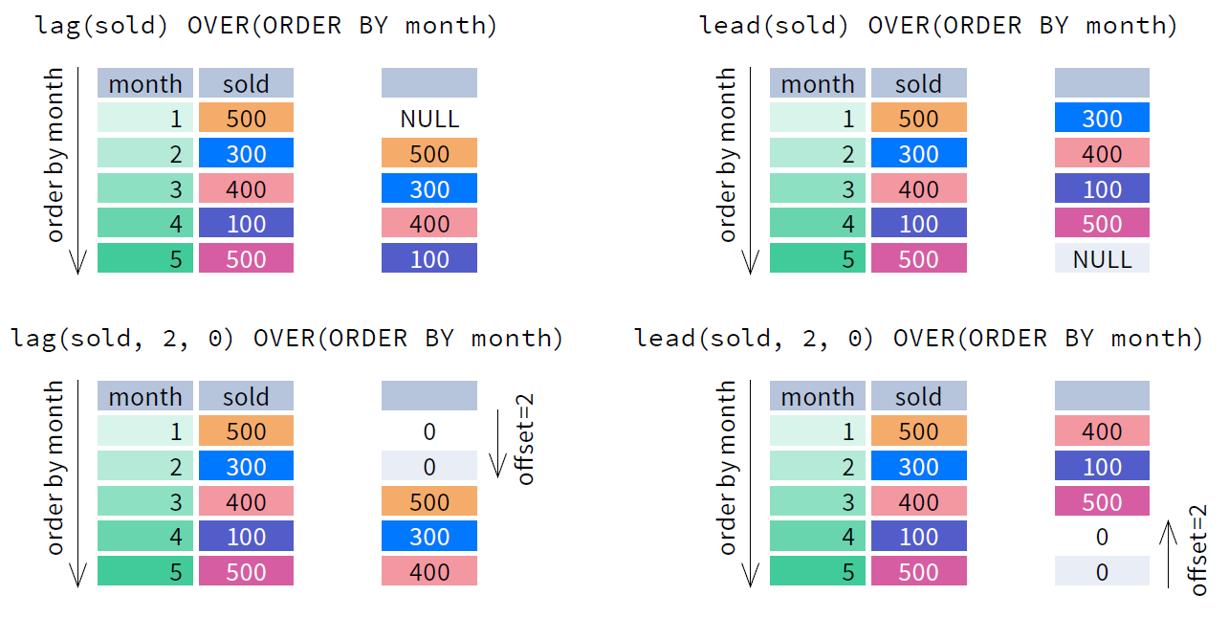

In [92]:
%%sql pg
-- LAG/LEAD: różnica do poprzedniej faktury klienta oraz podgląd za 2 faktury
SELECT invoice_id,
       invoice_date,
       total,
       LAG(total)          OVER (ORDER BY invoice_date, invoice_id) AS poprzednia,
       LEAD(total, 2, 0)   OVER (ORDER BY invoice_date, invoice_id) AS za_dwa,
       total - LAG(total)  OVER (ORDER BY invoice_date, invoice_id) AS roznica
FROM invoice
WHERE customer_id = 2
ORDER BY invoice_date, invoice_id;


Switching to connection 'pg'

7 rows affected.

invoice_id,invoice_date,total,poprzednia,za_dwa,roznica
1,2021-01-01 00:00:00,1.98,None,8.91,None
12,2021-02-11 00:00:00,13.86,1.98,1.98,11.88
67,2021-10-12 00:00:00,8.91,13.86,3.96,-4.95
196,2023-05-19 00:00:00,1.98,8.91,5.94,-6.93
219,2023-08-21 00:00:00,3.96,1.98,0.99,1.98
241,2023-11-23 00:00:00,5.94,3.96,0,1.98
293,2024-07-13 00:00:00,0.99,5.94,0,-4.95


In [53]:
%%sql oracle
SELECT InvoiceId,
       InvoiceDate,
       Total,
       LAG(Total)        OVER (ORDER BY InvoiceDate, InvoiceId) AS Poprzednia,
       LEAD(Total, 2, 0) OVER (ORDER BY InvoiceDate, InvoiceId) AS ZaDwa,
       Total - LAG(Total) OVER (ORDER BY InvoiceDate, InvoiceId) AS Roznica
FROM Invoice
WHERE CustomerId = 2
ORDER BY InvoiceDate, InvoiceId;


Switching to connection 'oracle'

invoiceid,invoicedate,total,poprzednia,zadwa,roznica
1,2021-01-01 00:00:00,1.98,None,8.91,None
12,2021-02-11 00:00:00,13.86,1.98,1.98,11.88
67,2021-10-12 00:00:00,8.91,13.86,3.96,-4.95
196,2023-05-19 00:00:00,1.98,8.91,5.94,-6.93
219,2023-08-21 00:00:00,3.96,1.98,0.99,1.98
241,2023-11-23 00:00:00,5.94,3.96,0,1.98
293,2024-07-13 00:00:00,0.99,5.94,0,-4.95


In [54]:
%%sql mssql
SELECT InvoiceId,
       InvoiceDate,
       Total,
       LAG(Total)         OVER (ORDER BY InvoiceDate, InvoiceId) AS Poprzednia,
       LEAD(Total, 2, 0)  OVER (ORDER BY InvoiceDate, InvoiceId) AS ZaDwa,
       Total - LAG(Total) OVER (ORDER BY InvoiceDate, InvoiceId) AS Roznica
FROM Invoice
WHERE CustomerId = 2
ORDER BY InvoiceDate, InvoiceId;


Switching to connection 'mssql'

InvoiceId,InvoiceDate,Total,Poprzednia,ZaDwa,Roznica
1,2021-01-01 00:00:00,1.98,None,8.91,None
12,2021-02-11 00:00:00,13.86,1.98,1.98,11.88
67,2021-10-12 00:00:00,8.91,13.86,3.96,-4.95
196,2023-05-19 00:00:00,1.98,8.91,5.94,-6.93
219,2023-08-21 00:00:00,3.96,1.98,0.99,1.98
241,2023-11-23 00:00:00,5.94,3.96,0.00,1.98
293,2024-07-13 00:00:00,0.99,5.94,0.00,-4.95


**FIRST_VALUE / LAST_VALUE** — wartość z początku/końca bieżącej ramki. I tu najbardziej znana pułapka SQL-a:

In [95]:
%%sql pg
-- pułapka domyślnej ramki: LAST_VALUE bez jawnej ramki = "ostatnia DO TEGO WIERSZA"
SELECT d, kwota,
       FIRST_VALUE(kwota) OVER w AS pierwsza,
       LAST_VALUE(kwota)  OVER w AS ostatna_bez_ramki,
       LAST_VALUE(kwota)  OVER (w ROWS BETWEEN UNBOUNDED PRECEDING
                                     AND UNBOUNDED FOLLOWING) AS ostatnia_ok
FROM (VALUES (1,10),(2,20),(3,30)) v(d,kwota)
WINDOW w AS (ORDER BY d);


Switching to connection 'pg'

3 rows affected.

d,kwota,pierwsza,ostatna_bez_ramki,ostatnia_ok
1,10,10,10,30
2,20,10,20,30
3,30,10,30,30


In [96]:
%%sql mssql
SELECT d, kwota,
       FIRST_VALUE(kwota) OVER w AS pierwsza,
       LAST_VALUE(kwota)  OVER w AS ostatnia_bez_ramki,
       LAST_VALUE(kwota)  OVER (w ROWS BETWEEN UNBOUNDED PRECEDING
                                     AND UNBOUNDED FOLLOWING) AS ostatnia_ok
FROM (VALUES (1,10),(2,20),(3,30)) v(d,kwota)
WINDOW w AS (ORDER BY d);


Switching to connection 'mssql'

d,kwota,pierwsza,ostatnia_bez_ramki,ostatnia_ok
1,10,10,10,30
2,20,10,20,30
3,30,10,30,30


In [97]:
%%sql oracle
SELECT d, kwota,
       FIRST_VALUE(kwota) OVER w AS pierwsza,
       LAST_VALUE(kwota)  OVER w AS ostatnia_bez_ramki,
       LAST_VALUE(kwota)  OVER (w ROWS BETWEEN UNBOUNDED PRECEDING
                                     AND UNBOUNDED FOLLOWING) AS ostatnia_ok
FROM (SELECT 1 d, 10 kwota FROM DUAL UNION ALL
      SELECT 2 d, 20 kwota FROM DUAL UNION ALL
      SELECT 3 d, 30 kwota FROM DUAL)
WINDOW w AS (ORDER BY d);


Switching to connection 'oracle'

d,kwota,pierwsza,ostatnia_bez_ramki,ostatnia_ok
1,10,10,10,30
2,20,10,20,30
3,30,10,30,30


> **Pułapka.** Kolumna `ostatnia_bez_ramki` pokazuje wartość **bieżącego
> wiersza**, bo domyślna ramka (`... AND CURRENT ROW`) kończy się na nim.
> Prawdziwa ostatnia wartość partycji wymaga jawnej ramki do
> `UNBOUNDED FOLLOWING`. (`FIRST_VALUE` nie cierpi na to: jego ramka zaczyna
> się zawsze na początku partycji.)
>
> **Pułapka 2 (ramka przy funkcjach czysto pozycyjnych).** `ROW_NUMBER`/`RANK`/
> `LAG`/`LEAD` **nie mają ramki** — oknem jest cała partycja:
> - Oracle: `ORA-03097: windowing clause not allowed for function ROW_NUMBER`
> - MSSQL: `Msg 10752: The function 'ROW_NUMBER' may not have a window frame.`
> - **PostgreSQL... milczy i ramkę ignoruje** — zapytanie wykona się i zwróci
>   poprawny wynik. Brak błędu to też pułapka: kod wygląda poprawnie,
>   a przeniesiony na Oracle/MSSQL — pada.

In [66]:
%%sql oracle
SELECT 
    g.Name AS Genre,
    t.Name AS TrackName,
    t.Milliseconds,
    ROW_NUMBER() OVER (
        PARTITION BY t.GenreId 
        ORDER BY t.Milliseconds DESC
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW -- Niedozwolona ramka okna
    ) AS TrackRank
FROM Track t
JOIN Genre g ON t.GenreId = g.GenreId;

RuntimeError: (oracledb.exceptions.DatabaseError) ORA-03097: windowing clause not allowed for function ROW_NUMBER
Help: https://docs.oracle.com/error-help/db/ora-03097/
[SQL: SELECT
    g.Name AS Genre,
    t.Name AS TrackName,
    t.Milliseconds,
    ROW_NUMBER() OVER (
        PARTITION BY t.GenreId
        ORDER BY t.Milliseconds DESC
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS TrackRank
FROM Track t
JOIN Genre g ON t.GenreId = g.GenreId;]
(Background on this error at: https://sqlalche.me/e/21/4xp6)


In [67]:
%%sql pg
SELECT 
    g.Name AS Genre,
    t.Name AS TrackName,
    t.Milliseconds,
    ROW_NUMBER() OVER (
        PARTITION BY t.Genre_Id 
        ORDER BY t.Milliseconds DESC
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW -- Niedozwolona ramka okna
    ) AS TrackRank
FROM Track t
JOIN Genre g ON t.Genre_Id = g.Genre_Id;

Switching to connection 'pg'

3503 rows affected.

genre,trackname,milliseconds,trackrank
Rock,Dazed And Confused,1612329,1
Rock,Space Truckin',1196094,2
Rock,Dazed And Confused,1116734,3
Rock,We've Got To Get Together/Jingo,1070027,4
Rock,Funky Piano,934791,5
Rock,Going Down / Highway Star,913658,6
Rock,Santana Jam,882834,7
Rock,The Sun Road,880640,8
Rock,Whole Lotta Love,863895,9
Rock,Mistreated (Alternate Version),854700,10


### `NTH_VALUE` — n-ta wartość w (całej) ramce

Uogólnienie `FIRST_VALUE`/`LAST_VALUE`: wartość z n-tego miejsca ramki. Podobnie jak `LAST_VALUE` cierpi na
**domyślną ramkę** — prawdziwe „n-ta wartość partycji" wymaga jawnej ramki do końca partycji:

In [68]:
%%sql pg
-- druga co do wielkości faktura każdego sprzedawcy:
-- bez jawnej ramki NTH_VALUE widziałby tylko wiersze do bieżącego!
SELECT c.support_rep_id, i.customer_id, i.total,
       NTH_VALUE(i.total, 2) OVER (
           PARTITION BY c.support_rep_id
           ORDER BY i.total DESC
           ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
       ) AS druga_najwieksza
FROM invoice i JOIN customer c USING (customer_id)
ORDER BY c.support_rep_id, i.total DESC
LIMIT 8;

8 rows affected.

support_rep_id,customer_id,total,druga_najwieksza
3,46,21.86,21.86
3,45,21.86,21.86
3,43,16.86,21.86
3,24,15.86,21.86
3,37,14.91,21.86
3,29,13.86,21.86
3,42,13.86,21.86
3,52,13.86,21.86


In [99]:
%%sql oracle
SELECT * FROM (
  SELECT c.SUPPORTREPID, i.CUSTOMERID, i.TOTAL,
         NTH_VALUE(i.TOTAL, 2) OVER (
             PARTITION BY c.SUPPORTREPID
             ORDER BY i.TOTAL DESC
             ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
         ) AS DRUGA
  FROM INVOICE i JOIN CUSTOMER c ON i.CUSTOMERID = c.CUSTOMERID
  ORDER BY c.SUPPORTREPID, i.TOTAL DESC
) WHERE ROWNUM <= 8;

Switching to connection 'oracle'

supportrepid,customerid,total,druga
3,46,21.86,21.86
3,45,21.86,21.86
3,43,16.86,21.86
3,24,15.86,21.86
3,37,14.91,21.86
3,1,13.86,21.86
3,59,13.86,21.86
3,12,13.86,21.86


> **Pułapka 1 (MSSQL nie ma NTH_VALUE).** Próba wykonania:
> `Msg 195: 'NTH_VALUE' is not a recognized built-in function name.`
> Obejście na MSSQL? — wzorzec z `DENSE_RANK`: wartość o randze 2 w oknie
> `DENSE_RANK() OVER (...)` (sekcja 10).
>
> **Pułapka 2 (okno liczone PRZED DISTINCT).** Chcesz „drugą największą
> **unikalną** kwotę" i piszesz `SELECT DISTINCT rep, total,
> NTH_VALUE(total, 2) OVER (...)`? Silnik liczy okno **na wierszach przed
> usunięciem duplikatów** — przy remisach na szczycie `NTH_VALUE(2)`
> zwróci tę samą wartość co pierwsza (np. dwie faktury 21.86 u sprzedawcy 3:
> drugą największą **unikalną** jest 16.86, ale funkcja zwraca 21.86).
> Tak działa standard: DISTINCT stosuje się do **wyniku**, okna liczone
> są wcześniej (kolejność logiczna jak w sekcji 6: okna → DISTINCT).
> Poprawnie: deduplikacja w CTE/podzapytaniu **przed** oknem.


## 12. Percentyle — PERCENT_RANK i CUME_DIST + dobre praktyki

- `PERCENT_RANK()` = `(rang - 1) / (N - 1)` ∈ [0, 1];
- `CUME_DIST()` = `(liczba wierszy <= bieżącego) / N` ∈ (0, 1].

Obydwie wymagają `ORDER BY` w oknie. Na fakturach USA 2025 — gdzie 100%
sprzedaży to duplikaty małych kwot — różnica dobrze widoczna:

In [100]:
%%sql mssql
SELECT TOP (12) InvoiceId, Total,
       CAST(PERCENT_RANK() OVER (ORDER BY Total) AS DECIMAL(10,4)) AS PctRank,
       CAST(CUME_DIST()  OVER (ORDER BY Total) AS DECIMAL(10,4))   AS CumeDist
FROM Invoice
WHERE BillingCountry = 'USA' AND YEAR(InvoiceDate) = 2025
ORDER BY Total, InvoiceId;


Switching to connection 'mssql'

InvoiceId,Total,PctRank,CumeDist
363,0.99,0.0000,0.1875
384,0.99,0.0000,0.1875
405,0.99,0.0000,0.1875
385,1.98,0.2000,0.4375
386,1.98,0.2000,0.4375
406,1.98,0.2000,0.4375
407,1.98,0.2000,0.4375
352,3.96,0.4667,0.5625
408,3.96,0.4667,0.5625
353,5.94,0.6000,0.6875


In [101]:
%%sql pg
SELECT invoice_id, total,
       ROUND(PERCENT_RANK() OVER (ORDER BY total)::numeric, 4) AS pct_rank,
       ROUND(CUME_DIST()  OVER (ORDER BY total)::numeric, 4)   AS cume_dist
FROM invoice
WHERE billing_country = 'USA' AND EXTRACT(YEAR FROM invoice_date) = 2025
ORDER BY total, invoice_id
LIMIT 12;


Switching to connection 'pg'

12 rows affected.

invoice_id,total,pct_rank,cume_dist
363,0.99,0.0000,0.1875
384,0.99,0.0000,0.1875
405,0.99,0.0000,0.1875
385,1.98,0.2000,0.4375
386,1.98,0.2000,0.4375
406,1.98,0.2000,0.4375
407,1.98,0.2000,0.4375
352,3.96,0.4667,0.5625
408,3.96,0.4667,0.5625
353,5.94,0.6000,0.6875


In [102]:
%%sql oracle
SELECT InvoiceId, Total,
       ROUND(PERCENT_RANK() OVER (ORDER BY Total), 4) AS PctRank,
       ROUND(CUME_DIST()  OVER (ORDER BY Total), 4)   AS CumeDist
FROM Invoice
WHERE BillingCountry = 'USA' AND EXTRACT(YEAR FROM InvoiceDate) = 2025
ORDER BY Total, InvoiceId
FETCH FIRST 12 ROWS ONLY;


Switching to connection 'oracle'

invoiceid,total,pctrank,cumedist
363,0.99,0,0.1875
384,0.99,0,0.1875
405,0.99,0,0.1875
385,1.98,0.2,0.4375
386,1.98,0.2,0.4375
406,1.98,0.2,0.4375
407,1.98,0.2,0.4375
352,3.96,0.4667,0.5625
408,3.96,0.4667,0.5625
353,5.94,0.6,0.6875


**Uwaga na dane**: kwoty 0.99–1.98 się powtarzają, więc obie funkcje skaczą
'po paczkach' wierszy o równej wartości — PERCENT_RANK i CUME_DIST liczą
rangi, **nie interpolują**. Do „prawdziwych" percentyli z interpolacją służą
funkcje agregatowe `PERCENTILE_CONT`/`PERCENTILE_DISC` — pokazujemy je
niżej, razem z klasycznymi statystykami opisowymi.

### Dobre praktyki

1. Zawsze określaj `ORDER BY` dla funkcji porządkowych (i tie-breaker!).
2. Pisz ramkę jawnie (`ROWS ...`), nawet gdyby domyślna wystarczała.
3. Testuj każdą funkcję okienną osobno (szczególnie LAST_VALUE!).
4. Dokumentuj, **co jest partycją** — błędny PARTITION BY to błąd logiki, nie składni; zapytanie 'ładnie działa' i zwraca śmieci.


### Statystyki opisowe: MEDIAN, PERCENTILE_(CONT|DISC), STDDEV, VARIANCE

Percentyle Okienne (`PERCENT_RANK`, `CUME_DIST`) liczą **rangi**. Do
statystyk „liczbowych" — mediany, kwartyli, odchylenia standardowego — służą
**agregaty statystyczne**. To nie są funkcje okienne: mają składnię
`funkcja(p) WITHIN GROUP (ORDER BY kolumna)` (PG, Oracle, MSSQL) albo
działają jak zwykły agregat (Oracle `MEDIAN`, `STDDEV`, `VARIANCE`;
MSSQL `STDEV`, `VAR`).

In [103]:
%%sql pg
-- PG: percentile_cont/disc + mode; MEDIAN nie istnieje (PERCENTILE_CONT(0.5) = mediana)
SELECT ROUND(AVG(total)::numeric, 4)                    AS srednia,
       ROUND(stddev_samp(total)::numeric, 4)            AS odchylenie,
       ROUND(variance(total)::numeric, 4)               AS wariancja,
       percentile_cont(0.5) WITHIN GROUP (ORDER BY total::numeric) AS mediana,
       percentile_cont(0.9) WITHIN GROUP (ORDER BY total::numeric) AS p90,
       percentile_disc(0.5) WITHIN GROUP (ORDER BY total)          AS mediana_dyskretna,
       mode() WITHIN GROUP (ORDER BY total)             AS dominanta
FROM invoice;

Switching to connection 'pg'

1 rows affected.

srednia,odchylenie,wariancja,mediana,p90,mediana_dyskretna,dominanta
5.6519,4.7453,22.5181,3.96,13.86,3.96,1.98


In [104]:
%%sql mssql
-- MSSQL: PERCENTILE_CONT wymaga OVER() (to funkcja okienna!); MEDIAN nie istnieje
SELECT DISTINCT
       CAST(STDEV(Total) OVER () AS DECIMAL(10,4)) AS Odchylenie,
       CAST(VAR(Total)    OVER () AS DECIMAL(10,4)) AS Wariancja,
       CAST(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY Total) OVER () AS DECIMAL(10,2)) AS Mediana,
       CAST(PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY Total) OVER () AS DECIMAL(10,2)) AS P90
FROM Invoice;

Switching to connection 'mssql'

Odchylenie,Wariancja,Mediana,P90
4.7453,22.5181,3.96,13.86


In [105]:
%%sql oracle
-- Oracle: jako jedyny ma MEDIAN; STDDEV/VARIANCE to zwykłe agregaty
SELECT ROUND(AVG(TOTAL), 4)                      AS SREDNIA,
       ROUND(STDDEV_SAMP(TOTAL), 4)              AS ODSY,
       ROUND(VARIANCE(TOTAL), 4)                 AS WARIANCJA,
       MEDIAN(TOTAL)                             AS MEDIANA,
       PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY TOTAL) AS P90
FROM INVOICE;

Switching to connection 'oracle'

srednia,odsy,wariancja,mediana,p90
5.6519,4.7453,22.5181,3.96,13.86


Te same dane, trzy silniki — i **identyczne wyniki**:
średnia 5.6519, odchylenie próbkowe 4.7453, wariancja 22.5181, mediana
(interpolowana) 3.96, p90 = 13.86, dominanta 1.98. Różnice są czysto
składniowe (tabela niżej) + dwie pułapki:

> **Pułapka 1 (bez OVER w MSSQL).** `SELECT PERCENTILE_CONT(0.5) WITHIN
> GROUP (ORDER BY Total) FROM Invoice`
> — MSSQL: `Msg 10753: The function 'PERCENTILE_CONT' must have an OVER
> clause.` W MSSQL percentyle stały się funkcjami okiennymi — wymagają
> `OVER ()` (także `OVER (PARTITION BY ...)`). PG i Oracle traktują je
> jako agregaty — `OVER` jest tam zabronione.
>
> **Pułapka 2 (MEDIAN tylko w Oracle).** PG: `ERROR: function
> median(numeric) does not exist`, MSSQL: `Msg 195: 'MEDIAN' is not a
> recognized built-in function name.` Przenośna mediana to wszędzie
> `PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY x)` (w MSSQL z `OVER ()`).

| | PostgreSQL 18 | MS SQL 2025 | Oracle 26ai |
|---|---|---|---|
| `MEDIAN(x)` | ✗ → `percentile_cont(0.5)…` | ✗ → jak w PG + `OVER ()` | ✓ (zwykły agregat) |
| `PERCENTILE_CONT/DISC` | ✓ agregat (`WITHIN GROUP`) | ✓ ale **funkcja okienna** (`OVER` wymagane) | ✓ agregat |
| `MODE()` | ✓ `mode() WITHIN GROUP` | ✗ → `top 1 with ties` po `GROUP BY` | ✗ → `STATS_MODE` |
| odchylenie/wariancja | `stddev_samp`, `variance` | `STDEV`, `VAR` (bez ` Samp`) | `STDDEV_SAMP`, `VARIANCE` |


## 13. Zabawa z oknami — ramki zależne od wiersza

Ciekawa sytuacja: **ramka, której offset liczy się z danych bieżącego wiersza**.

- PostgreSQL: `ROWS BETWEEN <wyrażenie z kolumn> PRECEDING` — błąd
  `InvalidColumnReference: argument of ROWS must not contain variables`
  (ramka musi być stała);
- MSSQL: `Msg 102: Incorrect syntax near 'CEILING'` — offset ramki
  to tylko literał/parametr;
- **Oracle: działa!** offset ramki może być wyrażeniem (tu `CEIL(Total*10)`).

In [69]:
%%sql oracle
-- jedyny z trójki, który to potrafi: ramka "skacze" zależnie od wartości Total
SELECT InvoiceId,
       Total,
       ROUND(SUM(Total) OVER (ORDER BY InvoiceId
            ROWS BETWEEN CEIL(Total*10) PRECEDING AND CURRENT ROW), 2) AS OknoSuma,
       COUNT(*)  OVER (ORDER BY InvoiceId
            ROWS BETWEEN CEIL(Total*10) PRECEDING AND CURRENT ROW)     AS OknoWierszy
FROM Invoice
WHERE CustomerId = 2
ORDER BY InvoiceId;


Switching to connection 'oracle'

invoiceid,total,oknosuma,oknowierszy
1,1.98,1.98,1
12,13.86,15.84,2
67,8.91,24.75,3
196,1.98,26.73,4
219,3.96,30.69,5
241,5.94,36.63,6
293,0.99,37.62,7


Dla klienta 2 okno rośnie z kwotą faktury: przy `Total = 3.96` ramka obejmuje
`CEIL(39.6) = 40` poprzednich wierszy (czyli praktycznie całą historię), a przy
`Total = 0.99` tylko 10. Czy to użyteczne? Rzadko — ale pokazuje, że „okno"
to pełnoprawne wyrażenie, nie tylko stała konfiguracja.

Kolejne ciekawe rozwiązanie to: **średnia ważona bez GROUP BY** — suma dotychczasowa
podzielona przez liczbę wierszy, okno przesuwane 3-wierszowe:

In [70]:
%%sql pg
-- średnia krocząca z rozkładu sumy narastającej (ROWS 2 PRECEDING)
SELECT invoice_id,
       total,
       ROUND(SUM(total) OVER (ORDER BY invoice_id
              ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS suma_3,
       ROUND(AVG(total) OVER (ORDER BY invoice_id
              ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS srednia_3
FROM invoice
WHERE customer_id = 2
ORDER BY invoice_id;


Switching to connection 'pg'

7 rows affected.

invoice_id,total,suma_3,srednia_3
1,1.98,1.98,1.98
12,13.86,15.84,7.92
67,8.91,24.75,8.25
196,1.98,24.75,8.25
219,3.96,14.85,4.95
241,5.94,11.88,3.96
293,0.99,10.89,3.63


> **Pułapka (ORA-03097 na ROW_NUMBER).** Przy okazji zabaw oknem częsty błąd:
> próba opcji ramki dla funkcji `ROW_NUMBER`/`RANK`/`LAG`. To funkcje
> porządkowe — Oracle odpowiada `ORA-03097: windowing clause not allowed
> for function ROW_NUMBER`. W PG — jak pisałem — ramka zostanie po cichu
> zignorowana. Testuj na dwóch silnikach!

## 14. CTE i rekurencja

**CTE** (`WITH name AS (...)`) = nazwany podzapytanie widoczne w jednym SELECT.

Poprzedzająca zapytanie SELECT klauzula WITH pozwala nadać nazwę relacjom powstałym w wyniku umieszczonych tam podzapytań. 
DMBS optymalizuje wykonanie takiego zapytania, np. implementując takie podzapytanie w postaci widoku zmaterializowanego lub tabeli tymczasowej. 

Zdefiniowane w ramach WITH podzapytania można następnie wykorzystać w zapytaniu, co sprawia, że staje się ono bardziej czytelne.

Zalety: czytelność, wielokrotne użycie, rekurencja. 

CTE **nie jest** materializacją — optymalizator zwykle wkleja je jak widok (wyjątki: PG ≤ 11 i starszy Oracle potrafił CTE z wielokrotnym użyciem trzymać jako tymczasowy blob).

Fragment składni zapytania SELECT z klauzulą WITH ma postać:
```sql
    WITH {NazwaPodzapytania AS (podzapytanie) [, …]}
    SELECT [DISTINCT | ALL] {wyrażenie [alias] [, ...]} | *
    FROM {NazwaRelacjiPerspektywyNazwaPodzapytania [alias] 
                [operator_złączenia  
                NazwaRelacjiPerspektywyNazwaPodzapytania [alias]
                [ON warunek_złączenia]] [, ...]}
    Reszta_składni_polecenia_SELECT
```

> **Pułapka nawyków z GROUP BY pozycyjnym.** W przykładach będzie
> `GROUP BY 1` — **działa w PostgreSQL, ale NIE w Oracle**
> (`ORA-03162: group-by value ... must not use positional referencing`,
> parametr `GROUP_BY_POSITION_ENABLED = FALSE`) ani w MSSQL
> (`Msg 164: Each GROUP BY expression must contain at least one column
> that is not an outer reference`). W notatniku używam pozycyjnego tylko
> w PG; na ćwiczeniach — zawsze pisz pełne wyrażenie.

### Zwykłe CTE — nazwane podzapytanie na jeden SELECT

Podstawa: `WITH nazwa AS (SELECT ...)` — **podzapytanie z nazwą** widoczne w głównym SELECT (i w kolejnych CTE).

W wykładzie 2 (§ 18) mieliśmy ten sam efekt przez podzapytanie w `FROM` (inline view); CTE różni się **kolejnością czytania** (najpierw definicje, potem główne zapytanie — kod czyta się „od góry") i możliwością **wielokrotnego użycia** tej samej definicji w jednym SELECT.

Ten sam wynik — na dwa sposoby (klienci wydający powyżej 40):

In [71]:
%%sql pg
-- wersja z podzapytaniem (inline view, wykład 2  18)
SELECT c.first_name, c.last_name, s.wydane
FROM customer c
JOIN (SELECT customer_id, SUM(total) AS wydane
      FROM invoice GROUP BY customer_id) s USING (customer_id)
WHERE s.wydane > 40
ORDER BY s.wydane DESC;

14 rows affected.

first_name,last_name,wydane
Helena,Holý,49.62
Richard,Cunningham,47.62
Luis,Rojas,46.62
Ladislav,Kovács,45.62
Hugh,O'Reilly,45.62
Fynn,Zimmermann,43.62
Frank,Ralston,43.62
Julia,Barnett,43.62
Victor,Stevens,42.62
Astrid,Gruber,42.62


In [72]:
%%sql pg
-- ten sam wynik z CTE — definicja u góry, użycie w dole
WITH wydatki AS (
  SELECT customer_id, SUM(total) AS wydane
  FROM invoice
  GROUP BY customer_id
)
SELECT c.first_name, c.last_name, w.wydane
FROM customer c JOIN wydatki w USING (customer_id)
WHERE w.wydane > 40
ORDER BY w.wydane DESC;

14 rows affected.

first_name,last_name,wydane
Helena,Holý,49.62
Richard,Cunningham,47.62
Luis,Rojas,46.62
Ladislav,Kovács,45.62
Hugh,O'Reilly,45.62
Fynn,Zimmermann,43.62
Frank,Ralston,43.62
Julia,Barnett,43.62
Victor,Stevens,42.62
Astrid,Gruber,42.62


**Łańcuch CTE** — każde kolejne CTE może korzystać z poprzednich
(przecinek zamiast WITH). To matroszka podzapytań, która pozostaje czytelna:

In [110]:
%%sql pg
-- CTE #2 korzysta z CTE #1: średnia wydatków klientów, potem filtr
WITH wydatki AS (
  SELECT customer_id, SUM(total) AS wydane
  FROM invoice
  GROUP BY customer_id
),
srednia AS (
  SELECT AVG(wydane) AS s FROM wydatki
)
SELECT w.customer_id, ROUND(w.wydane::numeric, 2) AS wydane,
       ROUND(s.s::numeric, 2)                     AS srednia_wszystkich
FROM wydatki w CROSS JOIN srednia s
WHERE w.wydane > s.s
ORDER BY w.wydane DESC
LIMIT 5;

5 rows affected.

customer_id,wydane,srednia_wszystkich
6,49.62,39.47
26,47.62,39.47
57,46.62,39.47
45,45.62,39.47
46,45.62,39.47


In [111]:
%%sql oracle
WITH wydatki AS (
  SELECT customerid, SUM(total) AS wydane
  FROM invoice
  GROUP BY customerid
),
srednia AS (
  SELECT AVG(wydane) AS s FROM wydatki
)
SELECT w.customerid, ROUND(w.wydane, 2) AS wydane, ROUND(s.s, 2) AS srednia
FROM wydatki w CROSS JOIN srednia s
WHERE w.wydane > s.s
ORDER BY w.wydane DESC
FETCH FIRST 5 ROWS ONLY;

Switching to connection 'oracle'

customerid,wydane,srednia
6,49.62,39.47
26,47.62,39.47
57,46.62,39.47
46,45.62,39.47
45,45.62,39.47



| | PostgreSQL 18 | MS SQL 2025 | Oracle 26ai |
|---|---|---|---|
| zwykłe CTE `WITH x AS (...)` | ✓ | ✓ | ✓ |
| wiele CTE (przecinek) | ✓ | ✓ | ✓ (lista kolumn opcjonalna) |
| zakres życia CTE | jeden SELECT/statement | **jeden batch** (do końca `GO`) | jeden SELECT/statement |
| rekurencja | **wymaga słowa `RECURSIVE`** | ✗ słowo zabronione (jawny błąd!) | lista kolumn w nagłówku |

CTE **nie jest** materializacją — optymalizator zwykle wkleja je jak widok.
(PG od 12 potrafi zmaterializować CTE używane wielokrotnie, z `MATERIALIZED`
kontrolujesz to jawnie.)


### CTE użyte dwa razy — koniec z copy-paste

Druga przewaga nad inline view: **jedną definicję można użyć wielokrotnie**
w jednym SELECT — np. złączyć CTE z samym sobą (porównania parami;
„kto sprzedał więcej od kogo").

In [73]:
%%sql pg
-- rep_sum złączone z rep_sum: porównania parami sprzedaży przedstawicieli
WITH rep_sum AS (
  SELECT c.support_rep_id AS rep,
         ROUND(SUM(i.total), 2) AS suma,
         COUNT(*)             AS faktur
  FROM invoice i
  JOIN customer c ON i.customer_id = c.customer_id
  GROUP BY c.support_rep_id
)
SELECT a.rep, a.suma, b.rep AS kolega, a.suma - b.suma AS roznica
FROM rep_sum a JOIN rep_sum b ON a.rep < b.rep
ORDER BY a.rep, b.rep;

3 rows affected.

rep,suma,kolega,roznica
3,833.04,4,57.64
3,833.04,5,112.88
4,775.40,5,55.24


In [113]:
%%sql oracle
WITH rep_sum AS (
  SELECT c.SupportRepId AS Rep,
         ROUND(SUM(i.Total), 2) AS Suma,
         COUNT(*)             AS Faktur
  FROM Invoice i
  JOIN Customer c ON i.CustomerId = c.CustomerId
  GROUP BY c.SupportRepId
)
SELECT a.Rep, a.Suma, b.Rep AS Kolega, a.Suma - b.Suma AS Roznica
FROM rep_sum a JOIN rep_sum b ON a.Rep < b.Rep
ORDER BY a.Rep, b.Rep;

Switching to connection 'oracle'

rep,suma,kolega,roznica
3,833.04,4,57.64
3,833.04,5,112.88
4,775.4,5,55.24


Ta sama definicja użyta dwa razy — inline view musiałby być zapisany dwa razy.

### `MATERIALIZED` / `NOT MATERIALIZED` — kto liczy CTE (PG 12+)

Domyślnie optymalizator **wkleja** CTE w każde miejsce użycia jak widok —
ale CTE użyte **wielokrotnie** PG sam liczy raz i trzyma wynik. Od PG 12
można tym sterować jawnie: `AS MATERIALIZED` (policz raz i przechowaj —
dobre dla drogiego podzapytania używanego kilka razy) vs
`AS NOT MATERIALIZED` (wklejaj jako widok — warunki z zewnętrznego
zapytania trafiają do środka, mogą zadziałać indeksy).

In [74]:
%%sql pg
-- słowo po AS decyduje: policz-raz-i-trzymaj vs wklejaj-jak-widok
WITH c AS MATERIALIZED     (SELECT COUNT(*) AS c FROM invoice),
     d AS NOT MATERIALIZED (SELECT COUNT(*) AS c FROM invoice)
SELECT c.c AS mat, d.c AS not_mat
FROM c CROSS JOIN d;

1 rows affected.

mat,not_mat
412,412


In [75]:
%%sql pg
-- klasyczny łańcuch: średnia na klienta → faktury ponad jej próg
-- → ile takich faktur ma klient (całość w JEDNYM SELECT)
WITH srednie AS (
  SELECT customer_id, ROUND(AVG(total), 2) AS srednia, COUNT(*) AS n
  FROM invoice
  GROUP BY customer_id
),
duze AS (
  SELECT i.invoice_id, i.customer_id, i.total
  FROM invoice i
  JOIN srednie s USING (customer_id)
  WHERE i.total > s.srednia
)
SELECT customer_id, COUNT(*) AS faktur_ponad_srednia
FROM duze
GROUP BY customer_id
ORDER BY faktur_ponad_srednia DESC, customer_id
LIMIT 6;


6 rows affected.

customer_id,faktur_ponad_srednia
1,3
2,3
3,3
4,3
5,3
8,3


> **Pułapka (CTE ≠ tabela tymczasowa).** CTE żyje **do końca jednego
> SELECT**: w kolejnej komórce `rep_sum` już nie istnieje —
> `ERROR:  relation "rep_sum" does not exist`. Trwały byt między
> zapytaniami to tabela tymczasowa (sekcja 15) albo widok (sekcja 17).

### Rekurencja — hierarchia pracowników

W ogólności możemy podać strukturę wyjściową CTE:
```sql
    WITH cte_name (column1, column2, ...) AS (
        subquery
    )
    SELECT columns FROM cte_name WHERE condition;
```
Przykładowo:
```sql
    WITH CTE_EMP(employee_id, manager_id) AS (
        SELECT employee_id, manager_id FROM employees WHERE manager_id IS NULL
    )
    SELECT * FROM CTE_EMP;

```


In [82]:
%%sql pg 
WITH CTE_EMP(emp_id,fname) AS (
    SELECT employee_id, first_name FROM employee
)
SELECT * FROM CTE_EMP;

8 rows affected.

emp_id,fname
1,Andrew
2,Nancy
3,Jane
4,Margaret
5,Steve
6,Michael
7,Robert
8,Laura



Następnie możemy zdefiniować rekurencyjną zależność w ramach CTE:
```sql
    WITH CTE_Tree(employee_id, reports_to) AS (
        -- Anchor member
        SELECT employee_id, reports_to FROM employees WHERE reports_to IS NULL
    UNION ALL
        -- Recursive member.
        SELECT t.employee_id, t.reports_to FROM employee t
        INNER JOIN CTE_Tree ct ON ct.employee_id = t.reports_to
    )
    SELECT * FROM CTE_Tree;
```

`ReportsTo` wskazuje przełożonego (NULL u szefa i dlatego od tego zaczynamy). 

Ogólna struktura rekurencyjnego CTE (rCTE):
1. **anchor** — wiersze startowe (`ReportsTo IS NULL`),
2. **UNION ALL**,
3. **krok rekurencyjny** — odwołuje się do własnej nazwy CTE.


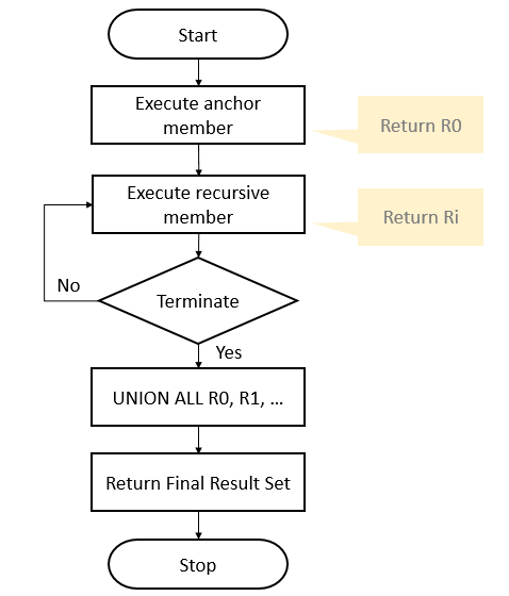

Składnia:

- PG: `WITH RECURSIVE cte AS (anchor UNION ALL krok)`,
- MSSQL: `WITH cte AS (anchor UNION ALL krok)` — **bez** RECURSIVE!,
- Oracle: `WITH cte (kolumny) AS (anchor UNION ALL krok)`.

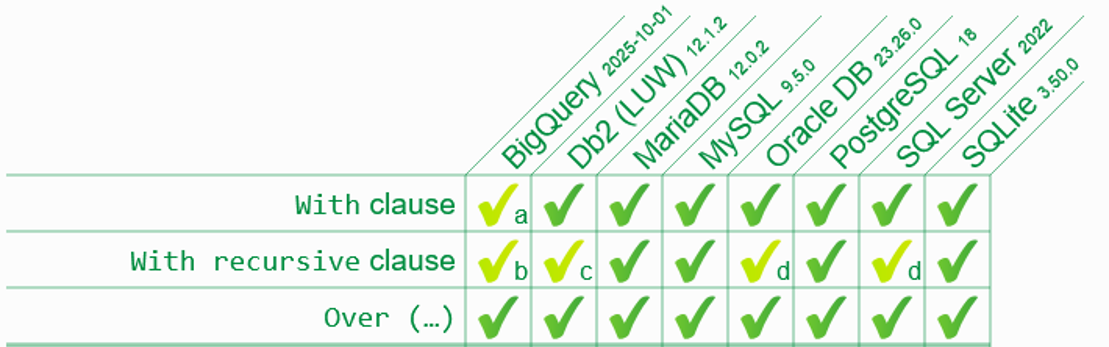

In [89]:
%%sql oracle
WITH CTE_Tree(employeeid, reportsto) AS (
        -- Anchor member
        SELECT employeeid, reportsto FROM employee WHERE reportsto IS NULL
    UNION ALL
        -- Recursive member.
        SELECT t.employeeid, t.reportsto FROM employee t
        INNER JOIN CTE_Tree ct ON ct.employeeid = t.reportsto
    )
    SELECT * FROM CTE_Tree;

employeeid,reportsto
1,None
2,1
6,1
3,2
4,2
5,2
7,6
8,6


In [90]:
%%sql pg
WITH RECURSIVE hierarchia AS (
  SELECT employee_id, last_name, reports_to, 1 AS lvl
  FROM employee
  WHERE reports_to IS NULL
  UNION ALL
  SELECT e.employee_id, e.last_name, e.reports_to, h.lvl + 1
  FROM employee e
  JOIN hierarchia h ON e.reports_to = h.employee_id
)
SELECT employee_id, last_name, reports_to, lvl,
       REPEAT('  ', lvl - 1) || last_name AS drzewo
FROM hierarchia
ORDER BY lvl, employee_id;


Switching to connection 'pg'

8 rows affected.

employee_id,last_name,reports_to,lvl,drzewo
1,Adams,None,1,Adams
2,Edwards,1,2,Edwards
6,Mitchell,1,2,Mitchell
3,Peacock,2,3,Peacock
4,Park,2,3,Park
5,Johnson,2,3,Johnson
7,King,6,3,King
8,Callahan,6,3,Callahan


In [117]:
%%sql mssql
WITH hierarchia AS (
  SELECT EmployeeId, LastName, ReportsTo, 1 AS Lvl
  FROM Employee
  WHERE ReportsTo IS NULL
  UNION ALL
  SELECT e.EmployeeId, e.LastName, e.ReportsTo, h.Lvl + 1
  FROM Employee e
  JOIN hierarchia h ON e.ReportsTo = h.EmployeeId
)
SELECT EmployeeId, LastName, ReportsTo, Lvl,
       SPACE(Lvl - 1) + LastName AS Drzewo
FROM hierarchia
ORDER BY Lvl, EmployeeId;


Switching to connection 'mssql'

EmployeeId,LastName,ReportsTo,Lvl,Drzewo
1,Adams,None,1,Adams
2,Edwards,1,2,Edwards
6,Mitchell,1,2,Mitchell
3,Peacock,2,3,Peacock
4,Park,2,3,Park
5,Johnson,2,3,Johnson
7,King,6,3,King
8,Callahan,6,3,Callahan


In [118]:
%%sql oracle
WITH hierarchia (EmployeeId, LastName, ReportsTo, Lvl) AS (
  SELECT EmployeeId, LastName, ReportsTo, 1
  FROM Employee
  WHERE ReportsTo IS NULL
  UNION ALL
  SELECT e.EmployeeId, e.LastName, e.ReportsTo, h.Lvl + 1
  FROM Employee e
  JOIN hierarchia h ON e.ReportsTo = h.EmployeeId
)
SELECT EmployeeId, LastName, ReportsTo, Lvl,
       LPAD('', (Lvl - 1) * 2, ' ') || LastName AS Drzewo
FROM hierarchia
ORDER BY Lvl, EmployeeId;


Switching to connection 'oracle'

employeeid,lastname,reportsto,lvl,drzewo
1,Adams,None,1,Adams
2,Edwards,1,2,Edwards
6,Mitchell,1,2,Mitchell
3,Peacock,2,3,Peacock
4,Park,2,3,Park
5,Johnson,2,3,Johnson
7,King,6,3,King
8,Callahan,6,3,Callahan


Wynik: Adams (szef, lvl 1) → Edwards/Mitchell (2) → ich podwładni (3)...

**Ważne**: tego samego drzewka nie da się wyrazić zwykłym JOIN-em — to graf acykliczny o znanej głębokości dopiero po przejściu.

### SEARCH / CYCLE — kontrola rekurencji

Rekurencja domyślnie szuka **do skutku**: jeśli graf ma cykl, zapytanie
wpada w pętlę. Standard (i Oracle 21c+, PG 14+) daje klauzule:

- `SEARCH DEPTH FIRST BY kol SET pkol` — deterministyczny porządek
  przejścia (numery ścieżki);
- `CYCLE kol SET flag TO 'Y' DEFAULT 'N' USING kol2` — detekcja cyklu
  (flaga + kolumna ścieżki).

MSSQL nie ma żadnej z nich — tam możemy wykorzystać opcję `OPTION (MAXRECURSION n)`, a cykle trzeba wyłapać samemu (np. śledząc ścieżkę w kolumnie tekstowej).


Zatem w PG i Oracle możemy określić kolejność wierszy przy użyciu klauzuli SEARCH, która może używać dwóch metod:
- BREADTH FIRST BY 
  - Wiersze równorzędne są zwracane przed przetworzeniem wierszy podrzędnych.
- DEPTH FIRST BY
  - Wiersze podrzędne są zwracane przed przetworzeniem elementów równorzędnych

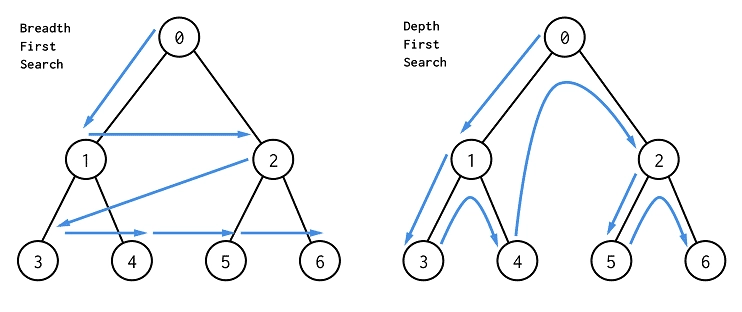

In [91]:
%%sql oracle
WITH hierarchia (EmployeeId, LastName, ReportsTo, Lvl) AS (
  SELECT EmployeeId, LastName, ReportsTo, 1
  FROM Employee
  WHERE ReportsTo IS NULL
  UNION ALL
  SELECT e.EmployeeId, e.LastName, e.ReportsTo, h.Lvl + 1
  FROM Employee e
  JOIN hierarchia h ON e.ReportsTo = h.EmployeeId
) SEARCH DEPTH FIRST BY EmployeeId SET Ord
SELECT EmployeeId, LastName, Lvl, Ord,
       LPAD('', (Lvl - 1) * 2, ' ') || LastName AS Drzewo
FROM hierarchia
ORDER BY Ord;


Switching to connection 'oracle'

employeeid,lastname,lvl,ord,drzewo
1,Adams,1,1,Adams
2,Edwards,2,2,Edwards
3,Peacock,3,3,Peacock
4,Park,3,4,Park
5,Johnson,3,5,Johnson
6,Mitchell,2,6,Mitchell
7,King,3,7,King
8,Callahan,3,8,Callahan


In [120]:
%%sql pg
WITH RECURSIVE hierarchia AS (
  SELECT employee_id, last_name, reports_to, 1 AS lvl
  FROM employee
  WHERE reports_to IS NULL
  UNION ALL
  SELECT e.employee_id, e.last_name, e.reports_to, h.lvl + 1
  FROM employee e
  JOIN hierarchia h ON e.reports_to = h.employee_id
) SEARCH DEPTH FIRST BY employee_id SET ord
SELECT employee_id, last_name, lvl, ord,
       REPEAT('  ', lvl - 1) || last_name AS drzewo
FROM hierarchia
ORDER BY ord;


Switching to connection 'pg'

8 rows affected.

employee_id,last_name,lvl,ord,drzewo
1,Adams,1,{(1)},Adams
2,Edwards,2,"{(1),(2)}",Edwards
3,Peacock,3,"{(1),(2),(3)}",Peacock
4,Park,3,"{(1),(2),(4)}",Park
5,Johnson,3,"{(1),(2),(5)}",Johnson
6,Mitchell,2,"{(1),(6)}",Mitchell
7,King,3,"{(1),(6),(7)}",King
8,Callahan,3,"{(1),(6),(8)}",Callahan


In [121]:
%%sql pg
-- CYCLE: gdyby ktoś zapętlił ReportsTo, PG terminuje z flagą is_cycle
WITH RECURSIVE hierarchia AS (
  SELECT employee_id, last_name, reports_to
  FROM employee
  WHERE reports_to IS NULL
  UNION ALL
  SELECT e.employee_id, e.last_name, e.reports_to
  FROM employee e
  JOIN hierarchia h ON e.reports_to = h.employee_id
) CYCLE employee_id SET is_cycle USING path
SELECT last_name, is_cycle, path
FROM hierarchia
ORDER BY array_length(path, 1), employee_id;


8 rows affected.

last_name,is_cycle,path
Adams,False,{(1)}
Edwards,False,"{(1),(2)}"
Mitchell,False,"{(1),(6)}"
Peacock,False,"{(1),(2),(3)}"
Park,False,"{(1),(2),(4)}"
Johnson,False,"{(1),(2),(5)}"
King,False,"{(1),(6),(7)}"
Callahan,False,"{(1),(6),(8)}"


> **Pułapka (nieskończona rekurencja).** Bez warunku stopu rCTE wpada w pętlę:
> - MSSQL przerwie po 100 iteracjach z błędem
>   `Msg 530: The statement terminated. The maximum recursion 100 has been
>   exhausted before statement completion.` — można to zmienić przez
>   `OPTION (MAXRECURSION n)` (0 = bez limitu, na własne ryzyko);
> - PG nie ma limitu iteracji — cykl ***wykryje*** tylko z `CYCLE`,
>   bez niego zapytanie kręci się w nieskończoność (aż do cancel);
> - Oracle: rCTE bez stopu = `ORA-32044: cycle detected while executing
>   recursive WITH clause` (kiedy faktycznie istnieje cykl).
>
> Kolejna pułapka syntaktyczna: **ORDER BY w CTE** bez TOP/LIMIT/FETCH —
> MSSQL: `Msg 1033: The ORDER BY clause is invalid in views, inline
> functions, derived tables, subqueries, and common table expressions...`
> (PG dopuszcza — ale tylko w połączeniu z LIMIT; porządek CTE nie
> „przecieka" do zapytania zewnętrznego!).

**Dobre praktyki** – WITH Clause
- Unikaj zagnieżdżeń – użyj CTEs
    - ~~ SELECT FROM (SELECT FROM (SELECT ...)) ~~
- Definiuj CTEs w logicznym porządku
    - ~~ WITH cte AS (SELECT a, b, c FROM table) AS ~~
    - Lepiej: WITH cte(revenue, expenses, profit) AS 
- Jawnie nazwij kolumny w CTE
    - Definuj CTEs od najprostszych do bardziej skomplikowanych. Czytelnik będzie śledzić logikę.
- Unikaj zbyt zagmatwanych rekurencji
    - Rekurencyjne CTEs mogą być trudne do zrozumienia. Jeśli CTE robi się zbyt skomplikowana, podziel na wiele kroków lub porządnie dokumentuj każdy krok.
- Dokumentuj cel każdej CTE
    - Dodaj komentarze wyjaśniające cel CTE:
        - WITH department_totals AS (
            -- Suma sprzedaży na dział
        )
- Testuj każdą CTE oddzielnie
    - Możesz testować każdą CTE osobno, kopiując ją do nowego zapytania. To upraszcza debugowanie.

## 15. Tabele tymczasowe

Kiedy: zapytanie liczy to samo kilka razy (cache), albo przekracza limity
złożoności w jednym SELECT. Typowy scenariusz na ćwiczeniach: zmaterializować
agregat per kraj, potem robić z niego raporty.

| | nazwa | zasięg życia | widoczność |
|---|---|---|---|
| MSSQL | `#lokalna` / `##globalna` | sesja / wszystkie sesje | właściciel / wszyscy (do zakończenia sesji twórcy) |
| PG | `CREATE TEMP TABLE` / `CREATE TEMP VIEW` | sesja (albo transakcja z `ON COMMIT`) | tylko moja sesja (schemat `pg_temp`) |
| Oracle | GTT (`GLOBAL TEMPORARY TABLE`, scope: transaction/session) / PTT (`PRIVATE TEMPORARY TABLE`) | definicja trwała, **dane** do końca transakcji/sesji | definicja w schemacie, dane prywatne |

W naszym środowisku: PG i MSSQL tworzą obiekty tymczasowe bez problemu,
w Oracle nie mamy uprawnień DDL (`ORA-01031`) — składnię Oracle pokazuję
jako tekst.

**MSSQL** — tabelka `#` żyje w tej sesji (jupysql trzyma jedno połączenie
do MSSQL, więc kolejne komórki ją widzą):

In [93]:
%%sql mssql
-- SELECT ... INTO: najszybszy sposób zmaterializować wynik SELECT-a
SELECT BillingCountry AS Kraj,
       CAST(SUM(Total) AS DECIMAL(10,2)) AS Sprzedaz2025,
       COUNT(*)                          AS Faktur
INTO #kraje2025
FROM Invoice
WHERE YEAR(InvoiceDate) = 2025
GROUP BY BillingCountry;

SELECT TOP (5) *
FROM #kraje2025
ORDER BY Sprzedaz2025 DESC;


21 rows affected.

Kraj,Sprzedaz2025,Faktur
USA,85.14,16
Canada,72.27,14
France,40.59,6
Brazil,37.62,7
Czech Republic,36.75,3


In [94]:
%%sql mssql
-- czy istnieje? OBJECT_ID('tempdb..#nazwa'); tabelka wciąż dostępna — to ta sama sesja
SELECT OBJECT_ID('tempdb..#kraje2025') AS IdObiektu;


IdObiektu
-1578060349


In [124]:
%%sql mssql
-- ##globalna: widoczna dla innych sesji, do zakończenia sesji twórcy
CREATE TABLE ##alarm (
  Kraj    nvarchar(50),
  Faktur  int
);
INSERT INTO ##alarm
SELECT Kraj, Faktur FROM #kraje2025 WHERE Faktur < 5;
SELECT * FROM ##alarm;


16 rows affected.

Kraj,Faktur
Argentina,3
Austria,1
Belgium,2
Czech Republic,3
Denmark,1
Finland,2
Germany,2
Hungary,1
India,3
Ireland,2


**PostgreSQL** — `CREATE TEMP TABLE ... AS` i temp widok (schemat `pg_temp`):

**Oracle** — brak uprawnień, ale składnia dla porządku (na ćwiczeniach w
własnym schemacie zadziała):

```sql
-- GTT: definicja trwała, dane znikają po COMMIT (albo po sesji)
CREATE GLOBAL TEMPORARY TABLE tmp_kraje2025 (
  kraj     VARCHAR2(50),
  sprzedaz NUMBER(10,2)
) ON COMMIT DELETE ROWS;         -- lub ON COMMIT PRESERVE ROWS

-- PTT (18c+): cała tabela w schemacie prywatnym sesji
CREATE PRIVATE TEMPORARY TABLE ora$ptt_kraje2025
ON COMMIT DROP DEFINITION AS
SELECT BillingCountry AS Kraj, SUM(Total) AS Sprzedaz
FROM Invoice GROUP BY BillingCountry;
```

> **Pułapka (sesje vs komórki).** Jupysql trzyma dla każdego aliasu jedno
> połączenie — dlatego `#kraje2025` „przetrwała" między komórkami w MSSQL.
> Ale jeśli połączysz się ponownie (albo w drugim oknie), tabelki **nie ma**:
> próba SELECT da `Msg 208: Invalid object name '#kraje2025'`. Tymczasowość
> dotyczy sesji, nie bazy.

In [96]:
%%sql pg
CREATE TEMP TABLE tmp_kraje2025 AS
SELECT billing_country AS kraj,
       ROUND(SUM(total), 2) AS sprzedaz,
       COUNT(*)             AS faktur
FROM invoice
WHERE EXTRACT(YEAR FROM invoice_date) = 2025
GROUP BY billing_country;

SELECT *
FROM tmp_kraje2025
ORDER BY sprzedaz DESC
LIMIT 5;


21 rows affected.

5 rows affected.

kraj,sprzedaz,faktur
USA,85.14,16
Canada,72.27,14
France,40.59,6
Brazil,37.62,7
Czech Republic,36.75,3


In [97]:
%%sql pg
-- temp WIDOK: zapytanie zachowane na czas sesji, bez kopiowania danych
CREATE TEMP VIEW v_kraje_duze AS
SELECT * FROM tmp_kraje2025 WHERE faktur >= 5;

SELECT count(*) AS duze_kraje FROM v_kraje_duze;


1 rows affected.

duze_kraje
5


In [127]:
%%sql pg
-- PG: temp obiekty znikają z sesją; W TEJ samej sesji wciąż są:
SELECT to_regclass('pg_temp.tmp_kraje2025') AS jest_tabela,
       to_regclass('pg_temp.v_kraje_duze')  AS jest_widok;


1 rows affected.

jest_tabela,jest_widok
tmp_kraje2025,v_kraje_duze


## 16. Zmienne

Zmienne w dialektach proceduralnych SQL (T-SQL, PL/pgSQL, PL/SQL) służą do tymczasowego przechowywania danych w pamięci podczas wykonywania poleceń SQL, skryptów, procedur lub funkcji, jednak różnią się składnią deklaracji, operatorem przypisania oraz strukturą bloku kodu.


**T-SQL (Microsoft SQL Server)**

W T-SQL nazwy zmiennych zawsze zaczynają się od znaku @. Zmienne deklaruje się poleceniem DECLARE i można to zrobić w dowolnym miejscu w kodzie skryptu lub procedury.
Deklaracja, przypisanie, użycie w jednym batchu (w jupysql: jedna komórka = jeden batch!):

> Deklaracja: DECLARE @nazwa TYP;

> Przypisanie: SET @nazwa = wartosc; lub SELECT @nazwa = kolumna FROM tabela;

In [100]:
%%sql mssql
-- UWAGA: bez średników! jupysql dzieli komórkę po ';' i robi z każdej
-- części osobny batch — zmienna zgubiłaby się między nimi.

-- deklaracja
DECLARE @od   date
-- przypisanie
SET @od = '2025-01-01'

-- deklaracja i przypisanie
DECLARE @kraj nvarchar(50) = N'Poland'

SELECT @kraj                        AS Kraj,
       COUNT(*)                     AS Faktur,
       CAST(SUM(Total) AS DECIMAL(10,2)) AS Suma
FROM Invoice
WHERE BillingCountry = @kraj
  AND InvoiceDate >= @od


Kraj,Faktur,Suma
Poland,1,0.99


In [129]:
%%sql mssql
-- w jednym batchu można też SET-em i SELECT-em z tabeli
DECLARE @max_total decimal(10,2)
SELECT @max_total = MAX(Total) FROM Invoice

SELECT @max_total AS MaxFaktura,
       COUNT(*)   AS TyleSamych
FROM Invoice
WHERE Total = @max_total


MaxFaktura,TyleSamych
25.86,1


> **Pułapka (batch = komórka).** Zmienna `@kraj` żyje **do końca batcha**.
> jupysql dodatkowo **dzieli tekst komórki po średnikach** — każdy fragment
> idzie jako osobny batch. Dlatego w przykładach wyżej **nie ma średników**:
> gdyby były, `DECLARE` poszedłoby w jednym batchu, a `SELECT` w drugim:
> `Msg 137: Must declare the scalar variable "@kraj".`
> (W SSMS batche separuje polecenie `GO` — w Jupyter go nie ma.)
>

> Standardowy SQL **nie ma zmiennych sesyjnych**. W PG ich rolę pełnią
> ustawienia `SET my.kraj = 'USA'` + `current_setting('my.kraj')` —
> ale to konfiguracja sesji, nie „zmienna" w sensie T-SQL.

| | PostgreSQL | MS SQL | Oracle (SQL*Plus) |
|---|---|---|---|
| zmienna T-SQL-owa | ✗ | `DECLARE @x int = 1` | ✗ |
| podstawienie tekstu | `psql` `\set` (klient) | ✗ | `&x` / `&&x`, `DEFINE` |
| parametr aplikacyjny | `$1` (prepared) | `@x` (sp_executesql) | bind `:x` |

W czystym SQL (poza funkcją, procedurą lub blokiem DO/DECLARE) żaden z systemów Oracle oraz PostgreSQL nie obsługują tradycyjnych zmiennych deklaratywnych w taki sposób, jak robi to T-SQL (DECLARE @zmienna).

Oba systemy oferują jednak mechanizmy sesyjne oraz klienta, które pozwalają przekazywać wartości między zapytaniami bez tworzenia bloków kodów proceduralnych.

W czystym SQL w PostgreSQL można wykorzystać zmienne sesyjne użytkownika (Custom GUC)

PostgreSQL pozwala na ustawianie własnych parametrów konfiguracyjnych w ramach sesji za pomocą SET i odczytywanie ich funkcją current_setting().

In [106]:
%config SqlMagic.named_parameters="enabled"

In [110]:
%%sql pg
-- Ustawienie zmiennej w sesji
SET custom.user_id = '1';

-- Użycie zmiennej w zapytaniu SQL
SELECT * FROM employee WHERE employee_id = current_setting('custom.user_id')::integer;

1 rows affected.

employee_id,last_name,first_name,title,reports_to,birth_date,hire_date,address,city,state,country,postal_code,phone,fax,email
1,Adams,Andrew,General Manager,None,1962-02-18 00:00:00,2002-08-14 00:00:00,11120 Jasper Ave NW,Edmonton,AB,Canada,T5K 2N1,+1 (780) 428-9482,+1 (780) 428-3457,andrew@chinookcorp.com


Oracle (bez bloku PL/SQL)

W środowiskach narzędziowych Oracle (np. SQL*Plus, SQL Developer, SQLcl) stosuje się zmienne wiązane (bind variables) lub zmienne podstawienia:
- Zmienne wiązane (Bind Variables) - zmienne istnieją w sesji klienta i są przekazywane do silnika bazy danych za pomocą dwukropka :
```sql
    -- Deklaracja zmiennej w sesji narzędzia
    VARIABLE v_id NUMBER;

    -- Przypisanie wartości (wymaga pojedynczego EXEC / polecenia)
    EXEC :v_id := 42;

    -- Użycie w czystym SQL
    SELECT * FROM users WHERE id = :v_id;
```
- Zmienne podstawienia (Substitution Variables) - działają na poziomie klienta (odpowiednik makra podmieniającego tekst przed wysłaniem do bazy):
```sql
-- Definicja zmiennej klienta
DEFINE v_id = 42;

-- Użycie w zapytaniu (znak &)
SELECT * FROM users WHERE id = &v_id;
```

Niestety tutaj nie zadziałają. 

In [114]:
%%sql oracle

-- Deklaracja zmiennej w sesji narzędzia
VARIABLE v_id NUMBER;

-- Przypisanie wartości (wymaga pojedynczego EXEC / polecenia)
DEFINE v_id = 1;

-- Użycie w czystym SQL
SELECT * FROM employee WHERE employeeid = :v_id;

RuntimeError: If using snippets, you may pass the --with argument explicitly.
For more details please refer: https://jupysql.ploomber.io/en/latest/compose.html#with-argument


Original error message from DB driver:
(oracledb.exceptions.DatabaseError) ORA-00900: invalid SQL statement
Help: https://docs.oracle.com/error-help/db/ora-00900/
[SQL: VARIABLE v_id NUMBER;]
(Background on this error at: https://sqlalche.me/e/21/4xp6)



## 17. Widoki — proste, złożone, modyfikowalne, CHECK OPTION, materializowane

**Widok** = zapisane zapytanie z nazwą. 
- wybór danych i wyrażeń zbudowanych na podstawie danych pobranych z jednej lub kilku relacji i z innych perspektyw

Perspektywy są widoczne przez użytkownika jako tabele
- Na poziomie bazy danych są przechowywane jedynie w postaci ich definicji 
    - nie dotyczy to tzw. perspektyw zmaterializowanych
- każde odwołanie się do perspektywy powoduje jej wykonanie / budowę

Perspektywy definiowane są z następujących powodów:
- aby ograniczyć dostęp do niektórych danych w relacji,
- aby ułatwić użytkownikowi pobieranie rezultatów skomplikowanych zapytań za pomocą prostych zapytań opartych na perspektywach,
- aby zwolnić użytkownika od wnikania w struktury danych,
- aby udostępnić informację widzianą w różny sposób przez różnych użytkowników.

Wybór i definicja perspektyw jest etapem fizycznego projektowania bazy danych


Podstawowa składnia polecenia definiującego perspektywę jest następująca:
```sql
    CREATE VIEW Nazwa_perspektywy [({atrybut_perspektywy [, ...]})]
    AS polecenie_SELECT
    [WITH CHECK OPTION [CONSTRAINT nazwa_ograniczenia]] |
    [WITH READ ONLY]
```
gdzie 
- atrybuty perspektywy są nowymi nazwami wyrażeń (atrybutów) wyspecyfikowanych w klauzurze SELECT polecenia SELECT (lista ta nie musi wystąpić jeśli wszystkie wyrażenia są atrybutami relacji/perspektywy; wtedy perspektywa będzie posiadać atrybuty o nazwach takich samych jak odpowiednie atrybuty relacji/perspektywy, z której pobierane są dane)
- opcjonalna klauzula WITH CHECK OPTION (dotycząca tylko perspektyw prostych) dopuszcza aktualizację poprzez perspektywę pod warunkiem, że zmienione lub nowe rekordy nadal będą się pojawiały w widoku (będą spełniały warunek po klauzurze WHERE ciała polecenia SELECT)
- po WITH CHECK OPTION można dodatkowo umieścić klauzulę CONSTRAINT nazwa_ograniczenia umożliwiającą nadanie nazwy tworzonemu ograniczeniu. Opcjonalna klauzula WITH READ ONLY (dotycząca tylko perspektyw prostych) uniemożliwia aktualizowanie danych poprzez widok.


Widok prosty:
- SELECT z jednej tabeli + WHERE. 
- Precyzyjniej - Perspektywy proste to takie, w których polecenie SELECT posiada następujące cechy:
nie zawierają złączeń, nie zawierają porządkowania, kwalifikatora DISTINCT, klauzuli GROUP BY, funkcji grupowych lub analitycznych, nie zawierają podzapytań skorelowanych lub podzapytań w klauzurze SELECT, nie zawierają klauzul CONNECT BY i START WITH.

Widok złożony: 
- agregaty, JOIN-y, DISTINCT — takich widoków **zwykle nie można modyfikować** 
    - (silnik nie umie rozpropagować INSERT na tabele bazowe).
- precyzyjniej - nie prosta :)

Wyróżniamy także **perspektywy modyfikowalne**
- nie wymaga oddzielnego poleceniem CREATE czy konkretnego słowa kluczowego – jest to raczej pewna właściwość widoku, która umożliwia używanie instrukcji języka manipulacji danymi (DML), takich jak INSERT, UPDATE i DELETE, bezpośrednio w nim (na relacjach ją budujących). 
    - zmiany wprowadzone w widoku są następnie przekazywane do bazowej tabeli podstawowej

Perspektywami modyfikowalnymi nazywa się więc perspektywy, które:
- nie zawierają złączeń, za wyjątkiem takich złączeń, dla których relacje łączone zachowują klucz (key-preserved tables) w perspektywie. 
    - Jeśli perspektywa zawiera złączenie, dla którego relacje łączone zachowują klucz to operacja DML na perspektywie musi dotyczyć tylko takiej jednej relacji. 
- dodatkowo: 
    - dla wykonania operacji INSERT perspektywa musi wybierać atrybuty klucza głównego i wszystkie atrybuty obowiązkowe relacji zachowującej klucz,
    - dla wykonania operacji UPDATE wszystkie modyfikowane atrybuty muszą pochodzić z relacji zachowującej klucz,
    - dla wykonania operacji DELETE operacja złączenia może dotyczyć tylko jednej relacji zachowującej klucz.
    - nie zawierają porządkowania, kwalifikatora DISTINCT, klauzuli GROUP BY, funkcji grupowych lub analitycznych,
    - nie zawierają podzapytań skorelowanych i podzapytań w klauzurze SELECT
    - nie zawierają klauzul CONNECT BY i START WITH,
    - nie zawierają wyrażeń lub pseudokolumn (polecenia INSERT i UPDATE na perspektywie nie mogą ich dotyczyć).


**Live na PostgreSQL** — jako tabelę bazową bierzemy temp tabelę (w bazach
chinook mamy tylko SELECT). Najpierw prosty widok:

In [130]:
%%sql pg
-- Przygotowanie: mini-tabela dzial/pracownik/kwota (symulacja dzialu IT)
DROP VIEW IF EXISTS v_it;
CREATE TEMP TABLE tmp_rep AS
SELECT x.id, x.dzial, x.osoba, x.kwota
FROM (VALUES (1, 'IT',  'Kowalski', 100),
             (2, 'IT',  'Nowak',    150),
             (3, 'HR',  'Wiśniewska', 90),
             (4, 'IT',  'Zieliński', 120)) AS x(id, dzial, osoba, kwota);

SELECT * FROM tmp_rep ORDER BY id;


Switching to connection 'pg'

4 rows affected.

4 rows affected.

id,dzial,osoba,kwota
1,IT,Kowalski,100
2,IT,Nowak,150
3,HR,Wiśniewska,90
4,IT,Zieliński,120


In [131]:
%%sql pg
-- widok prosty: filtrowanie jednej tabeli
CREATE TEMP VIEW v_it AS
SELECT id, osoba, kwota FROM tmp_rep WHERE dzial = 'IT';

SELECT * FROM v_it ORDER BY kwota DESC;


3 rows affected.

id,osoba,kwota
2,Nowak,150
4,Zieliński,120
1,Kowalski,100


Widok można **modyfikować** (INSERT/UPDATE/DELETE), jeśli jest „prosty"
wystarczająco: SELECT z jednej tabeli, bez agregatów/DISTINCT/GROUP BY,
wszystkie kolumny NOT NULL z tabeli bazowe dostępne...

In [132]:
%%sql pg
-- UPDATE przez widok — OK (widok prosty)
UPDATE v_it SET kwota = kwota + 10 WHERE osoba = 'Kowalski';
SELECT * FROM v_it ORDER BY osoba;


1 rows affected.

3 rows affected.

id,osoba,kwota
1,Kowalski,110
2,Nowak,150
4,Zieliński,120


**WITH CHECK OPTION** — widok pilnuje, by modyfikacje nie „wyprowadzały"
wierszy poza widok (UPDATE-ować kolumnę z WHERE? — nie!):

In [133]:
%%sql pg
CREATE TEMP VIEW v_it_chk AS
SELECT id, dzial, osoba, kwota FROM tmp_rep WHERE dzial = 'IT'
WITH CHECK OPTION;

-- UPDATE zgodny z definicją widoku — OK
UPDATE v_it_chk SET kwota = kwota * 2 WHERE osoba = 'Nowak';
SELECT * FROM v_it_chk ORDER BY osoba;


1 rows affected.

3 rows affected.

id,dzial,osoba,kwota
1,IT,Kowalski,110
2,IT,Nowak,300
4,IT,Zieliński,120


> **Pułapka (CHECK OPTION).** Próba zmiany `dzial` przez ten widok:
>
> ```sql
> UPDATE v_it_chk SET dzial = 'HR' WHERE osoba = 'Zieliński';
> ```
>
> PostgreSQL: `ERROR: new row violates check option for view "v_it_chk"`
> (SQLSTATE 44000). Bez `WITH CHECK OPTION` UPDATE by przeszedł — wiersz
> „ucieka" z widoku (zostaje w tabeli, ale przestaje spełniać WHERE).
> Oracle: `ORA-01402: view WITH CHECK OPTION where-clause violation`.
> MSSQL: `Msg 550: The attempted insert or update failed because the target
> view either specifies WITH CHECK OPTION...`.

### `CREATE OR REPLACE VIEW` — zmiana definicji bez DROP

Klasyczne tworzenie widoku nie jest możliwe, gdy widok już istnieje (
`ERROR: relation "v_it" already exists` w PG,
`Msg 2714: There is already an object named 'v_it' in the database.` w MSSQL,
`ORA-00955: name is already used by an existing object` w Oracle).
Ratunek zależy od silnika:

- PostgreSQL / Oracle: `CREATE **OR REPLACE** VIEW ...`;
- MSSQL: ~~`OR REPLACE`~~ → `CREATE **OR ALTER** VIEW ...` (od 2016 SP1);
- także MySQL/MariaDB: `OR REPLACE`.

**Live na PostgreSQL** — rozbudujemy definicję widoku `v_it` o jedną
kolumnę:

In [134]:
%%sql pg
-- v_it istnieje od sekcji 17 — podmieniamy definicję bez DROP
CREATE OR REPLACE TEMP VIEW v_it AS
SELECT id, osoba, kwota, dzial              -- dorzucamy dzial (na końcu!)
FROM tmp_rep WHERE dzial = 'IT';

SELECT * FROM v_it ORDER BY kwota DESC;

3 rows affected.

id,osoba,kwota,dzial
2,Nowak,300,IT
4,Zieliński,120,IT
1,Kowalski,110,IT


> **Pułapka (OR REPLACE nie zrobi wszystkiego).** Podmiana definicji ma
> **twarde ograniczenia** — nowe `CREATE OR REPLACE` musi zostać
> „wkomponowane" w istniejącą strukturę kolumn:
>
> ```sql
> -- usunięcie kolumny z definicji?
> CREATE OR REPLACE TEMP VIEW v_it AS
> SELECT id, osoba FROM tmp_rep WHERE dzial = 'IT';
> ```
>
> PostgreSQL: `ERROR: cannot drop columns from view` (SQLSTATE 42P16).
> Zmiana nazwy kolumny też nie: `ERROR: cannot change name of view column
> "id" to "cid"` (podpowiedź: `ALTER VIEW ... RENAME COLUMN`). Podmienić
> wolno tylko „dopisek z tyłu": nowe kolumny na końcu, te same nazwy
> i typy starych. Pełną swobodę daje jedynie `DROP VIEW` + `CREATE VIEW`
> — ale wtedy tracisz uprawnienia/komentarze zgromadzone na obiekcie.
>
> Zmiana **treści** SELECT-a (filtr, JOIN-y, wyrażenia w tych samych
> kolumnach) — jest zawsze dozwolona; ograniczenia dotyczą tylko
> **listy kolumn** widoku.


**A po co w ogóle REPLACE?** Bo `DROP + CREATE` psuje
uprawnienia (GRANT-y), komentarze i zależności. `OR REPLACE` zachowuje
uprawnienia nadane na widok — dlatego to standardowy sposób iterowania
widoków w środowisku produkcyjnym. W Oracle dodatkowo `CREATE OR REPLACE
FORCE VIEW` pozwala podmienić widok nawet, gdy tabela bazowa nie istnieje
(widok powstaje INVALID, „naprawi się" po utworzeniu tabeli).

Konta studenckie w Oracle nie mają uprawnień DDL
(`CREATE OR REPLACE VIEW` → `ORA-01031: insufficient privileges`), a w MSSQL
`CREATE VIEW permission denied` — dlatego bardziej niż samą składnię poćwicz
na ćwiczeniach we własnym schemacie; tu — na widokach temp w PG.


### Widoki na JOIN-ach — key-preserved wsparcie różne

Oracle (od zawsze) i MSSQL pozwalają modyfikować widok na JOIN-ie, jeśli
modyfikowane kolumny pochodzą z jednej, **key-preserved** tabeli (klucz
główny tej tabeli jest unikalny w wyniku JOIN). PostgreSQL tego **nie robi**
bez triggerów:

```sql
-- przykład (Oracle/MSSQL): UPDATE patrzy tylko na kolumny z Employee
CREATE VIEW v_emp_kraje AS
SELECT e.EmployeeId, e.LastName, c.Country,
       COUNT(*) OVER (PARTITION BY c.Country) AS KlientowWKraju
FROM Employee e JOIN Customer c ON c.SupportRepId = e.EmployeeId;

UPDATE v_emp_kraje SET LastName = 'X' WHERE EmployeeId = 1;  -- Oracle/MSSQL: OK
```

> **Pułapka (PG).** Ten sam widok w PG przy UPDATE odpowie:
> `ERROR: cannot update view "v_emp_kraje"` z podpowiedzią
> `HINT: Views that do not select from a single table... cannot be updated
> automatically... consider making an INSTEAD OF trigger`.
> (Dokładny tekst: Views that do not select from a single table cannot be
> updated automatically.) — na ćwiczeniach: trigger INSTEAD OF albo
> modyfikacja przez CTE z WRITING...— patrz dokumentacja PG.

Widok 
```sql
CREATE VIEW HR_Employees AS 
SELECT employee_id, last_name, department_id, salary 
FROM employees 
WHERE department_id = 40
WITH CHECK OPTION; 
```
Pozwala na:
```sql
UPDATE HR_Employees 
SET Salary = 65000 WHERE EmployeeID = 101;
```
Ale już nie na:
```sql
UPDATE HR_Employees 
SET Department = 60 WHERE EmployeeID = 105;
```

### Materializowane

Zwykły widok "liczy" się **przy każdym SELECT**. Materialized view = osobna
tabela + odświeżanie (good dla ciężkich raportów):

```sql
-- Oracle
CREATE MATERIALIZED VIEW mv_kraje2025
BUILD IMMEDIATE REFRESH FAST ON COMMIT AS
SELECT BillingCountry, SUM(Total) Suma
FROM Invoice
WHERE EXTRACT(YEAR FROM InvoiceDate) = 2025
GROUP BY BillingCountry;

-- PostgreSQL (bez REFRESH FAST; brak MV tymczasowych!)
CREATE MATERIALIZED VIEW mv_kraje2025 AS ... ;   -- + REFRESH MATERIALIZED VIEW
```

MS SQL nie ma MV — jego odpowiednikiem są **widoki indeksowane**
(`CREATE VIEW ... WITH SCHEMABINDING` + unikalny indeks klastrowany;
dane aktualizują się przy zapisie).

> **Pułapki widoków (slajdy 188-199).**
> 1. `SELECT *` w widoku zamraża **listę kolumn na moment tworzenia** —
>    ALTER tabeli nie dokłada nowych kolumn do widoku (MSSQL/Oracle),
>    a w PG ALTER może nawet zepsuć widok (invalid view).
> 2. Widok nie zamraża **planu** — optymalizator liczy go za każdym razem
>    (chyba że MV/indexed view).
> 3. ORDER BY w definicji widoku formalnie nic nie gwarantuje —
>    zewnętrzny SELECT bez ORDER BY może zwrócić dowolną kolejność.
> 4. Zagnieżdżanie widoków (widok na widoku) bywa problemem wydajnościowym:
>    liczba warstw rośnie, plan wykonania staje się nieczytelny.

## 18. Pseudokolumny — ROWID i ROWNUM (Oracle)

Pseudokolumna wygląda jak kolumna, ale nie jest przechowywana. Oracle ma
przydatne dwie (MSSQL i PG nie mają odpowiedników):

- **ROWID** — fizyczny adres wiersza (plik:blok:wiersz) — najszybszy dostęp,
  ale **nietrwały** (po rebuild/move się zmienia!),
- **ROWNUM** — numer kolejny wiersza **w bieżącym wyniku** (przed sortowaniem!),
  również w UPDATE/DELETE do ograniczenia.

In [135]:
%%sql oracle
SELECT ROWID AS Adres,
       EmployeeId,
       LastName
FROM Employee
FETCH FIRST 5 ROWS ONLY;


Switching to connection 'oracle'

adres,employeeid,lastname
AAAUD5AAAAAAAOEAAA,1,Adams
AAAUD5AAAAAAAOEAAB,2,Edwards
AAAUD5AAAAAAAOEAAC,3,Peacock
AAAUD5AAAAAAAOEAAD,4,Park
AAAUD5AAAAAAAOEAAE,5,Johnson


In [136]:
%%sql oracle
-- ROWNUM: TOP-N i stronicowanie "historycznie"
SELECT ROWNUM AS Nr,
       LastName,
       HireDate
FROM Employee
ORDER BY HireDate;


nr,lastname,hiredate
3,Peacock,2002-04-01 00:00:00
2,Edwards,2002-05-01 00:00:00
1,Adams,2002-08-14 00:00:00
4,Park,2003-05-03 00:00:00
5,Johnson,2003-10-17 00:00:00
6,Mitchell,2003-10-17 00:00:00
7,King,2004-01-02 00:00:00
8,Callahan,2004-03-04 00:00:00


> **Pułapka (ROWNUM + ORDER BY).** `ROWNUM` jest nadawany **przed**
> sortowaniem — więc `WHERE ROWNUM <= 3 ORDER BY HireDate` zwraca
> „pierwsze 3 z naturalnej kolejności, potem posortowane", a NIE trzy
> najwcześniejsze daty! Poprawny historyczny Top-N (do 12c):
> `SELECT * FROM (SELECT ... ORDER BY HireDate) WHERE ROWNUM <= 3;`
> — albo współcześnie: `FETCH FIRST 3 ROWS ONLY`.

In [137]:
%%sql oracle
-- Poprawny historyczny Top-N: sortowanie WEWNĄTRZ, ROWNUM na zewnątrz
SELECT ROWNUM AS N, InvoiceId, Total
FROM (SELECT InvoiceId, Total
      FROM Invoice
      ORDER BY Total DESC)
WHERE ROWNUM <= 5;

n,invoiceid,total
1,404,25.86
2,299,23.86
3,96,21.86
4,194,21.86
5,89,18.86


In [138]:
%%sql oracle
-- Stronicowanie przed 12c: numerujemy w podzapytaniu, wybieramy stronę
SELECT *
FROM (SELECT ROWNUM AS N, t.*
      FROM (SELECT InvoiceId, Total
            FROM Invoice
            ORDER BY Total DESC) t)
WHERE N BETWEEN 6 AND 10;

n,invoiceid,total
6,89,18.86
7,88,17.91
8,313,16.86
9,306,16.86
10,208,15.86


> **Pułapka (ROWNUM rośnie dopiero po przyjęciu wiersza).** Warunek
> `WHERE ROWNUM > 5` zwraca **zawsze pusty wynik**: kandydat na wiersz 1
> dostaje `ROWNUM = 1`, nie spełnia `> 5`, odrzucany — i tak w kółko,
> numer nigdy nie „dorasta" do 6. To samo `ROWNUM = 2` — pusto.
> Działają tylko `ROWNUM <= n` i `ROWNUM = 1`; dalsze strony robi się
> dopiero numerując w podzapytaniu — jak wyżej z `BETWEEN 6 AND 10`.
>
> **Kontrola wyników:** Top-5 to kwoty 25.86, 23.86, 21.86, 21.86, 18.86
> (InvoiceId 404, 299, 96, 194, 89) — identycznie jak `FETCH FIRST 5 ROWS
> ONLY`; strona 2 zaczyna się od 18.86 (InvoiceId 89), potem 17.91,
> 16.86, 16.86, 15.86. Czego ROWNUM nie umie: remisy — faktura 18.86
> występuje dwa razy (89 i 201) i `ROWNUM <= 5` odcina sztucznie,
> a `FETCH FIRST ... WITH TIES` przepuści oba (jak `TOP (n) WITH TIES`
> w MSSQL, sekcja 10).

**A MSSQL?** Zapytanie `SELECT ROWNUM FROM Employee` kończy się tam:

```text
Msg 207, Level 16, State 1
Invalid column name 'ROWNUM'.
```

W MSSQL nie ma ani `ROWNUM`, ani `ROWID` — numer wiersza daje wyłącznie
funkcja okienna `ROW_NUMBER()`, a fizyczny adres wiersza nie jest
ujawniany przez silnik.

| | PostgreSQL | MS SQL | Oracle |
|---|---|---|---|
| fizyczny adres wiersza | `ctid` (strona:krotka, może się zmieniać po VACUUM) | `%%physical%%`... nieujawnione | `ROWID` |
| numer wiersza wyniku | `ROW_NUMBER()` | `ROW_NUMBER()` | `ROWNUM` + `ROW_NUMBER()` |
| TOP-N | `LIMIT n` / `FETCH FIRST` | `TOP (n)` / `TOP WITH TIES` | `ROWNUM <= n` (stare) / `FETCH FIRST` (12c+) |

**PG nt.**: `ctid` istnieje, ale dokumentacja/narzędzia zdecydowanie
odradzają traktowanie go jak ROWID (VACUUM może przesunąć wiersz).

## 19. Przykłady praktyczne — wszystko razem

Cztery typowe zadania raportowe, każde w trzech dialektach,gdzie to możliwe.

### 19.1 Top-3 kraje per rok — CTE + ROW_NUMBER (wzorzec top-N w grupie)

In [139]:
%%sql pg
WITH per_rok AS (
  SELECT EXTRACT(YEAR FROM invoice_date) AS rok,
         billing_country                 AS kraj,
         ROUND(SUM(total), 2)            AS suma,
         ROW_NUMBER() OVER (PARTITION BY EXTRACT(YEAR FROM invoice_date)
                            ORDER BY SUM(total) DESC) AS rn
  FROM invoice
  GROUP BY 1, 2
)
SELECT rok, rn, kraj, suma
FROM per_rok
WHERE rn <= 3
ORDER BY rok, rn;


Switching to connection 'pg'

15 rows affected.

rok,rn,kraj,suma
2021,1,USA,103.95
2021,2,Canada,57.42
2021,3,Germany,53.46
2022,1,USA,102.98
2022,2,Canada,76.26
2022,3,Brazil,41.60
2023,1,USA,103.01
2023,2,Canada,55.44
2023,3,Germany,48.57
2024,1,USA,127.98


In [140]:
%%sql mssql
WITH per_rok AS (
  SELECT YEAR(InvoiceDate)          AS Rok,
         BillingCountry             AS Kraj,
         CAST(SUM(Total) AS DECIMAL(10,2)) AS Suma,
         ROW_NUMBER() OVER (PARTITION BY YEAR(InvoiceDate)
                            ORDER BY SUM(Total) DESC) AS Rn
  FROM Invoice
  GROUP BY YEAR(InvoiceDate), BillingCountry
)
SELECT Rok, Rn, Kraj, Suma
FROM per_rok
WHERE Rn <= 3
ORDER BY Rok, Rn;


Switching to connection 'mssql'

Rok,Rn,Kraj,Suma
2021,1,USA,103.95
2021,2,Canada,57.42
2021,3,Germany,53.46
2022,1,USA,102.98
2022,2,Canada,76.26
2022,3,Brazil,41.60
2023,1,USA,103.01
2023,2,Canada,55.44
2023,3,Germany,48.57
2024,1,USA,127.98


In [141]:
%%sql oracle
WITH per_rok AS (
  SELECT EXTRACT(YEAR FROM InvoiceDate) AS Rok,
         BillingCountry                 AS Kraj,
         ROUND(SUM(Total), 2)           AS Suma,
         ROW_NUMBER() OVER (PARTITION BY EXTRACT(YEAR FROM InvoiceDate)
                            ORDER BY SUM(Total) DESC) AS Rn
  FROM Invoice
  GROUP BY EXTRACT(YEAR FROM InvoiceDate), BillingCountry
)
SELECT Rok, Rn, Kraj, Suma
FROM per_rok
WHERE Rn <= 3
ORDER BY Rok, Rn;


Switching to connection 'oracle'

rok,rn,kraj,suma
2021,1,USA,103.95
2021,2,Canada,57.42
2021,3,Germany,53.46
2022,1,USA,102.98
2022,2,Canada,76.26
2022,3,Brazil,41.6
2023,1,USA,103.01
2023,2,Canada,55.44
2023,3,Germany,48.57
2024,1,USA,127.98


### 19.2 Suma narastająca per sprzedawca (running total)

In [142]:
%%sql mssql
SELECT TOP (15) c.SupportRepId,
       i.InvoiceId,
       i.InvoiceDate,
       CAST(i.Total AS DECIMAL(10,2)) AS Total,
       CAST(SUM(i.Total) OVER (PARTITION BY c.SupportRepId
                     ORDER BY i.InvoiceId
                     ROWS UNBOUNDED PRECEDING) AS DECIMAL(10,2)) AS Narastajaco
FROM Invoice i
JOIN Customer c ON c.CustomerId = i.CustomerId
ORDER BY c.SupportRepId, i.InvoiceId;


Switching to connection 'mssql'

SupportRepId,InvoiceId,InvoiceDate,Total,Narastajaco
3,6,2021-01-19 00:00:00,0.99,0.99
3,7,2021-02-01 00:00:00,1.98,2.97
3,9,2021-02-02 00:00:00,3.96,6.93
3,10,2021-02-03 00:00:00,5.94,12.87
3,11,2021-02-06 00:00:00,8.91,21.78
3,15,2021-03-04 00:00:00,1.98,23.76
3,23,2021-04-05 00:00:00,3.96,27.72
3,26,2021-04-14 00:00:00,13.86,41.58
3,27,2021-04-22 00:00:00,0.99,42.57
3,30,2021-05-06 00:00:00,3.96,46.53


In [143]:
%%sql pg
SELECT c.support_rep_id,
       i.invoice_id,
       i.invoice_date::date AS dzien,
       i.total,
       ROUND(SUM(i.total) OVER (PARTITION BY c.support_rep_id
              ORDER BY i.invoice_id
              ROWS UNBOUNDED PRECEDING), 2) AS narastajaco
FROM invoice i
JOIN customer c ON c.customer_id = i.customer_id
ORDER BY c.support_rep_id, i.invoice_id
LIMIT 15;


Switching to connection 'pg'

15 rows affected.

support_rep_id,invoice_id,dzien,total,narastajaco
3,6,2021-01-19,0.99,0.99
3,7,2021-02-01,1.98,2.97
3,9,2021-02-02,3.96,6.93
3,10,2021-02-03,5.94,12.87
3,11,2021-02-06,8.91,21.78
3,15,2021-03-04,1.98,23.76
3,23,2021-04-05,3.96,27.72
3,26,2021-04-14,13.86,41.58
3,27,2021-04-22,0.99,42.57
3,30,2021-05-06,3.96,46.53


In [144]:
%%sql oracle
SELECT c.SupportRepId,
       i.InvoiceId,
       TRUNC(i.InvoiceDate) AS Dzien,
       i.Total,
       ROUND(SUM(i.Total) OVER (PARTITION BY c.SupportRepId
              ORDER BY i.InvoiceId
              ROWS UNBOUNDED PRECEDING), 2) AS Narastajaco
FROM Invoice i
JOIN Customer c ON c.CustomerId = i.CustomerId
ORDER BY c.SupportRepId, i.InvoiceId
FETCH FIRST 15 ROWS ONLY;


Switching to connection 'oracle'

supportrepid,invoiceid,dzien,total,narastajaco
3,6,2021-01-19 00:00:00,0.99,0.99
3,7,2021-02-01 00:00:00,1.98,2.97
3,9,2021-02-02 00:00:00,3.96,6.93
3,10,2021-02-03 00:00:00,5.94,12.87
3,11,2021-02-06 00:00:00,8.91,21.78
3,15,2021-03-04 00:00:00,1.98,23.76
3,23,2021-04-05 00:00:00,3.96,27.72
3,26,2021-04-14 00:00:00,13.86,41.58
3,27,2021-04-22 00:00:00,0.99,42.57
3,30,2021-05-06 00:00:00,3.96,46.53


### 19.3 Średnia krocząca 3 dni — RANGE na datach (i kompromis ROWS w MSSQL)

In [145]:
%%sql pg
-- średnia z dni [d-2, d] — po dacie, niezależnie od gęstości faktur
SELECT d,
       kwota,
       ROUND(AVG(kwota) OVER (ORDER BY d
              RANGE BETWEEN INTERVAL '2 days' PRECEDING AND CURRENT ROW), 2) AS srednia_3d
FROM (SELECT invoice_date::date AS d, SUM(total) AS kwota
      FROM invoice
      WHERE EXTRACT(YEAR FROM invoice_date) = 2025
      GROUP BY 1) t
ORDER BY d;


Switching to connection 'pg'

69 rows affected.

d,kwota,srednia_3d
2025-01-02,8.91,8.91
2025-01-07,13.86,13.86
2025-01-15,0.99,0.99
2025-01-28,3.96,3.96
2025-01-29,3.96,3.96
2025-01-30,5.94,4.62
2025-02-02,8.91,8.91
2025-02-07,13.86,13.86
2025-02-15,0.99,0.99
2025-02-28,3.96,3.96


In [146]:
%%sql oracle
SELECT TRUNC(InvoiceDate) AS D,
       SUM(Total)          AS Kwota,
       ROUND(AVG(SUM(Total)) OVER (ORDER BY TRUNC(InvoiceDate)
              RANGE BETWEEN NUMTODSINTERVAL(2,'DAY') PRECEDING AND CURRENT ROW), 2) AS Srednia3d
FROM Invoice
WHERE EXTRACT(YEAR FROM InvoiceDate) = 2025
GROUP BY TRUNC(InvoiceDate)
ORDER BY D;


Switching to connection 'oracle'

d,kwota,srednia3d
2025-01-02 00:00:00,8.91,8.91
2025-01-07 00:00:00,13.86,13.86
2025-01-15 00:00:00,0.99,0.99
2025-01-28 00:00:00,3.96,3.96
2025-01-29 00:00:00,3.96,3.96
2025-01-30 00:00:00,5.94,4.62
2025-02-02 00:00:00,8.91,8.91
2025-02-07 00:00:00,13.86,13.86
2025-02-15 00:00:00,0.99,0.99
2025-02-28 00:00:00,3.96,3.96


In [147]:
%%sql mssql
WITH dz AS (
  SELECT CAST(InvoiceDate AS date) AS D,
         CAST(SUM(Total) AS DECIMAL(10,2)) AS Kwota
  FROM Invoice
  WHERE YEAR(InvoiceDate) = 2025
  GROUP BY CAST(InvoiceDate AS date)
)
SELECT D, Kwota,
       CAST(AVG(Kwota) OVER (ORDER BY D
              ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS DECIMAL(10,2)) AS Srednia3w
FROM dz
ORDER BY D;


Switching to connection 'mssql'

D,Kwota,Srednia3w
2025-01-02,8.91,8.91
2025-01-07,13.86,11.39
2025-01-15,0.99,7.92
2025-01-28,3.96,6.27
2025-01-29,3.96,2.97
2025-01-30,5.94,4.62
2025-02-02,8.91,6.27
2025-02-07,13.86,9.57
2025-02-15,0.99,7.92
2025-02-28,3.96,6.27


### 19.4 Rok do roku (YoY) — LAG po sumach rocznych USA

In [148]:
%%sql pg
WITH roczne AS (
  SELECT EXTRACT(YEAR FROM invoice_date) AS rok,
         ROUND(SUM(total), 2)            AS suma
  FROM invoice
  WHERE billing_country = 'USA'
  GROUP BY 1
)
SELECT rok,
       suma,
       LAG(suma) OVER (ORDER BY rok) AS rok_poprzedni,
       ROUND(100 * (suma - LAG(suma) OVER (ORDER BY rok))
             / LAG(suma) OVER (ORDER BY rok), 1) AS zmiana_pct
FROM roczne
ORDER BY rok;


Switching to connection 'pg'

5 rows affected.

rok,suma,rok_poprzedni,zmiana_pct
2021,103.95,None,None
2022,102.98,103.95,-0.9
2023,103.01,102.98,0.0
2024,127.98,103.01,24.2
2025,85.14,127.98,-33.5


In [149]:
%%sql mssql
WITH roczne AS (
  SELECT YEAR(InvoiceDate) AS Rok,
         CAST(SUM(Total) AS DECIMAL(10,2)) AS Suma
  FROM Invoice
  WHERE BillingCountry = 'USA'
  GROUP BY YEAR(InvoiceDate)
)
SELECT Rok,
       Suma,
       LAG(Suma) OVER (ORDER BY Rok) AS RokPoprzedni,
       CAST(100 * (Suma - LAG(Suma) OVER (ORDER BY Rok))
            / LAG(Suma) OVER (ORDER BY Rok) AS DECIMAL(10,1)) AS ZmianaPct
FROM roczne
ORDER BY Rok;


Switching to connection 'mssql'

Rok,Suma,RokPoprzedni,ZmianaPct
2021,103.95,None,None
2022,102.98,103.95,-0.9
2023,103.01,102.98,0.0
2024,127.98,103.01,24.2
2025,85.14,127.98,-33.5


In [150]:
%%sql oracle
WITH roczne AS (
  SELECT EXTRACT(YEAR FROM InvoiceDate) AS Rok,
         ROUND(SUM(Total), 2)           AS Suma
  FROM Invoice
  WHERE BillingCountry = 'USA'
  GROUP BY EXTRACT(YEAR FROM InvoiceDate)
)
SELECT Rok,
       Suma,
       LAG(Suma) OVER (ORDER BY Rok) AS RokPoprzedni,
       ROUND(100 * (Suma - LAG(Suma) OVER (ORDER BY Rok))
             / LAG(Suma) OVER (ORDER BY Rok), 1) AS ZmianaPct
FROM roczne
ORDER BY Rok;


Switching to connection 'oracle'

rok,suma,rokpoprzedni,zmianapct
2021,103.95,None,None
2022,102.98,103.95,-0.9
2023,103.01,102.98,0
2024,127.98,103.01,24.2
2025,85.14,127.98,-33.5


### 19.5 Filtracja po funkcji okiennej — przez CTE (pamiętaj o sekcji 6!)

Zadanie: klienci, których suma zakupów przewyższa sumę **średniego klienta**
w swoim kraju o więcej niż 2×. Filtr `WHERE` po oknie jest niedozwolony
(Pułapka sekcji 6) — okno liczmy w CTE, filtrujemy w zewnętrznym zapytaniu:

Zacznijmy od intuicyjnej — **błędnej** — próby. Okno w filtrze `WHERE`:

```sql
SELECT customer_id, kraj, suma
FROM klient_kraj
WHERE suma > 2 * AVG(suma) OVER (PARTITION BY kraj)
```

```text
ERROR:  window functions are not allowed in WHERE
LINE 3: WHERE suma > 2 * AVG(suma) OVER (PARTITION BY kraj)
```

Filtr działa na wierszach **zanim** policzą się okna. Poprawnie: **dwa
poziomy** — okno w CTE, filtr w SELECT zewnętrznym:

In [151]:
%%sql pg
WITH klient_kraj AS (
  SELECT c.customer_id,
         i.billing_country AS kraj,
         ROUND(SUM(i.total), 2) AS suma
  FROM customer c JOIN invoice i USING (customer_id)
  GROUP BY c.customer_id, i.billing_country
),
z_oknem AS (
  SELECT customer_id, kraj, suma,
         ROUND(AVG(suma) OVER (PARTITION BY kraj), 2) AS srednia_kraj
  FROM klient_kraj
)
SELECT *
FROM z_oknem
WHERE suma > 2 * srednia_kraj
ORDER BY suma DESC
LIMIT 8;


Switching to connection 'pg'

customer_id,kraj,suma,srednia_kraj


In [152]:
%%sql mssql
WITH klient_kraj AS (
  SELECT c.CustomerId,
         i.BillingCountry AS Kraj,
         CAST(SUM(i.Total) AS DECIMAL(10,2)) AS Suma
  FROM Customer c JOIN Invoice i ON i.CustomerId = c.CustomerId
  GROUP BY c.CustomerId, i.BillingCountry
),
z_oknem AS (
  SELECT CustomerId, Kraj, Suma,
         CAST(AVG(Suma) OVER (PARTITION BY Kraj) AS DECIMAL(10,2)) AS SredniaKraj
  FROM klient_kraj
)
SELECT *
FROM z_oknem
WHERE Suma > 2 * SredniaKraj
ORDER BY Suma DESC;


Switching to connection 'mssql'

CustomerId,Kraj,Suma,SredniaKraj


In [153]:
%%sql oracle
WITH klient_kraj AS (
  SELECT c.CustomerId,
         i.BillingCountry AS Kraj,
         ROUND(SUM(i.Total), 2) AS Suma
  FROM Customer c JOIN Invoice i ON i.CustomerId = c.CustomerId
  GROUP BY c.CustomerId, i.BillingCountry
),
z_oknem AS (
  SELECT CustomerId, Kraj, Suma,
         ROUND(AVG(Suma) OVER (PARTITION BY Kraj), 2) AS SredniaKraj
  FROM klient_kraj
)
SELECT *
FROM z_oknem
WHERE Suma > 2 * SredniaKraj
ORDER BY Suma DESC;


Switching to connection 'oracle'

customerid,kraj,suma,sredniakraj


### 19.6 Sprzedaż wg gatunku — PIVOT, FILTER, CASE i ranking w jednym

Raport: gatunek × [2021|2022|2023] + udział w całości. Wszystkie techniki
dzisiaj omówione:

In [154]:
%%sql pg
WITH gatunki AS (
  SELECT g.name AS gatunek,
         EXTRACT(YEAR FROM i.invoice_date) AS rok
  FROM track t
  JOIN genre g USING (genre_id)
  JOIN invoice_line il USING (track_id)
  JOIN invoice i USING (invoice_id)
)
SELECT gatunek,
       COUNT(*) FILTER (WHERE rok = 2021) AS y2021,
       COUNT(*) FILTER (WHERE rok = 2022) AS y2022,
       COUNT(*) FILTER (WHERE rok = 2023) AS y2023,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS udzial_pct,
       DENSE_RANK() OVER (ORDER BY COUNT(*) DESC) AS pozycja
FROM gatunki
GROUP BY gatunek
ORDER BY pozycja
LIMIT 10;


Switching to connection 'pg'

10 rows affected.

gatunek,y2021,y2022,y2023,udzial_pct,pozycja
Rock,180,157,158,37.3,1
Latin,83,78,81,17.2,2
Metal,62,54,26,11.8,3
Alternative & Punk,63,40,46,10.9,4
Jazz,20,16,16,3.6,5
Blues,11,11,20,2.7,6
TV Shows,0,13,14,2.1,7
R&B/Soul,8,9,7,1.8,8
Classical,0,14,10,1.8,8
Reggae,6,7,8,1.3,9


In [155]:
%%sql mssql
WITH gatunki AS (
  SELECT g.Name AS Gatunek,
         YEAR(i.InvoiceDate) AS Rok
  FROM Track t
  JOIN Genre g ON g.GenreId = t.GenreId
  JOIN InvoiceLine il ON il.TrackId = t.TrackId
  JOIN Invoice i ON i.InvoiceId = il.InvoiceId
)
SELECT TOP (10) Gatunek,
       COUNT(CASE WHEN Rok = 2021 THEN 1 END) AS Y2021,
       COUNT(CASE WHEN Rok = 2022 THEN 1 END) AS Y2022,
       COUNT(CASE WHEN Rok = 2023 THEN 1 END) AS Y2023,
       CAST(100. * COUNT(*) / SUM(COUNT(*)) OVER () AS DECIMAL(10,1)) AS UdzialPct,
       DENSE_RANK() OVER (ORDER BY COUNT(*) DESC) AS Pozycja
FROM gatunki
GROUP BY Gatunek
ORDER BY Pozycja;


Switching to connection 'mssql'

Gatunek,Y2021,Y2022,Y2023,UdzialPct,Pozycja
Rock,180,157,158,37.3,1
Latin,83,78,81,17.2,2
Metal,62,54,26,11.8,3
Alternative & Punk,63,40,46,10.9,4
Jazz,20,16,16,3.6,5
Blues,11,11,20,2.7,6
TV Shows,0,13,14,2.1,7
R&B/Soul,8,9,7,1.8,8
Classical,0,14,10,1.8,8
Reggae,6,7,8,1.3,9


In [156]:
%%sql oracle
WITH gatunki AS (
  SELECT g.Name AS Gatunek,
         EXTRACT(YEAR FROM i.InvoiceDate) AS Rok
  FROM Track t
  JOIN Genre g ON g.GenreId = t.GenreId
  JOIN InvoiceLine il ON il.TrackId = t.TrackId
  JOIN Invoice i ON i.InvoiceId = il.InvoiceId
)
SELECT Gatunek,
       COUNT(CASE WHEN Rok = 2021 THEN 1 END) AS Y2021,
       COUNT(CASE WHEN Rok = 2022 THEN 1 END) AS Y2022,
       COUNT(CASE WHEN Rok = 2023 THEN 1 END) AS Y2023,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS UdzialPct,
       DENSE_RANK() OVER (ORDER BY COUNT(*) DESC) AS Pozycja
FROM gatunki
GROUP BY Gatunek
ORDER BY Pozycja
FETCH FIRST 10 ROWS ONLY;


Switching to connection 'oracle'

gatunek,y2021,y2022,y2023,udzialpct,pozycja
Rock,180,157,158,37.3,1
Latin,83,78,81,17.2,2
Metal,62,54,26,11.8,3
Alternative & Punk,63,40,46,10.9,4
Jazz,20,16,16,3.6,5
Blues,11,11,20,2.7,6
TV Shows,0,13,14,2.1,7
R&B/Soul,8,9,7,1.8,8
Classical,0,14,10,1.8,8
Reggae,6,7,8,1.3,9


## 20. Podsumowanie — ściąga dialektyczna

| temat | PostgreSQL 18 | MS SQL 2025 | Oracle 26ai |
|---|---|---|---|
| korelowane FROM | `LATERAL` (+ `LEFT JOIN LATERAL ... ON TRUE`) | `CROSS/OUTER APPLY` | `LATERAL` + `CROSS/OUTER APPLY` |
| składnik daty | `EXTRACT` / `date_part` | `DATEPART` (bez `EXTRACT`!) | `EXTRACT` / `TO_CHAR` |
| PIVOT / UNPIVOT | ✗ → `FILTER`/`CASE`; unpivot przez `LATERAL (VALUES)` | ✓ (agregat po kolumnie — `COUNT(*)` → `Msg 102`; ✗ multi-IN) | ✓ (+ `UNPIVOT INCLUDE NULLS`, multi-IN par `(a,b)`; `EXTRACT(QUARTER)` w źródle → `ORA-00907`) |
| agregat warunkowy | `SUM(x) FILTER (WHERE …)` | `CASE` wewnątrz agregatu | `CASE` wewnątrz agregatu |
| `GROUPING SETS`/`ROLLUP`/`CUBE` | ✓ | ✓ (alias → `Msg 207`!) | ✓ |
| `GROUPING()` / `GROUPING_ID()` | ✓ / ✗ *(brak — wystarczy `GROUPING`)* | ✓ / ✓ | ✓ / ✓ |
| agregacja tekstowa | `string_agg(DISTINCT… ORDER BY…)` | `STRING_AGG` (✗ DISTINCT → podzapytanie) | `LISTAGG … WITHIN GROUP` (+`ON OVERFLOW TRUNCATE`) |
| `MEDIAN(x)` | ✗ → `percentile_cont(0.5)…` | ✗ (percentyle jako okna, `OVER()`!) | ✓ |
| `PERCENTILE_CONT/DISC` | ✓ agregat | ✓ **okienny** (`Msg 10753` bez OVER) | ✓ agregat |
| `STDDEV`/`VARIANCE` | `stddev_samp`,`variance` | `STDEV`,`VAR` | `STDDEV_SAMP`,`VARIANCE` (+`STATS_MODE`) |
| `NTH_VALUE` | ✓ | ✗ `Msg 195` | ✓ (ramka jawnie!) |
| `DISTINCT ON` | ✓ (rozszerzenie PG) | ✗ `Msg 156` | ✗ `ORA-00936` |
| `NULLIF` | ✓ standard | ✓ standard | ✓ standard |
| zmiana definicji widoku | `CREATE OR REPLACE VIEW` (+temp) | `CREATE OR ALTER VIEW` (✗ OR REPLACE) | `CREATE OR REPLACE VIEW` (+`FORCE`) |
| `WINDOW` (nazwane okno) | ✓ (+ rozszerzanie o ramkę) | ✓ (od 2022) | ✓ (od 21c) |
| okno w WHERE/HAVING | błąd: `window functions are not allowed…` | `Msg 4108` | `ORA-00934`/`ORA-30483` |
| `ROWS` ramka | ✓ | ✓ | ✓ |
| `RANGE` z offsetem | ✓ (`INTERVAL`) | ✗ `Msg 4194` | ✓ (`NUMTODSINTERVAL`) |
| `GROUPS` ramka | ✓ | ✗ `Msg 102` | ✓ |
| NULLS FIRST/LAST | ✓ | ✗ (NULL-e pierwsze w ASC) | ✓ (domyślnie NULLS LAST w ASC) |
| `WITH TIES` | `FETCH FIRST n ROWS WITH TIES` (13+) | `TOP (n) WITH TIES` | `FETCH FIRST n ROWS WITH TIES` (12c+) |
| ramka zależna od wiersza | ✗ | ✗ | ✓ `ROWS BETWEEN <wyrażenie> PRECEDING` |
| ramka przy `ROW_NUMBER`/`LAG` | **ignorowana po cichu!** | `Msg 10752` | `ORA-03097` |
| rCTE | `WITH RECURSIVE` (bez → błąd) | `WITH` (z RECURSIVE → błąd!) | `WITH c (cols) AS (...)` |
| CTE wielokrotne użycie | ✓ (PG 12+ `MATERIALIZED`/`NOT MATERIALIZED`) | ✓ (żyje do końca batcha) | ✓ |
| `SEARCH/CYCLE` | ✓ (14+) / ✓ | ✗ (`OPTION (MAXRECURSION n)`) | ✓ SEARCH (21c+) |
| tabele tymczasowe | `CREATE TEMP TABLE` (sesyjne, `pg_temp`) | `#t`, `##t`, `INTO #t` (`tempdb`) | GTT/PTT (dane per transakcja/sesja) |
| zmienne SQL | ✗ (psql `\set` poza SQL) | `DECLARE @x` (batch!) | SQL*Plus `&x` (klient) |
| widoki modyfikowalne | proste + `WITH CHECK OPTION`; JOIN-view tylko z triggerem | proste + key-preserved JOIN | proste + key-preserved JOIN |
| materializacja widoku | `MATERIALIZED VIEW` + ręczny `REFRESH` | indexed view (`SCHEMABINDING`) | `MATERIALIZED VIEW` (+`REFRESH FAST ON COMMIT`) |
| pseudokolumny | `ctid` (nie używać jak ROWID) | — | `ROWID`, `ROWNUM` (nadawany przed ORDER BY; `> n` i `= n` → pusto!) |

**Co zapamiętać ponad wszystko:**

1. Funkcje okienne rozszerzają SQL o analitykę bez SELF-JOIN — ale tylko w
   SELECT/ORDER BY; filtrowanie po oknie = CTE (sekcja 19.5).
2. Ramka (`ROWS`/`RANGE`/`GROUPS`) to osobny koncept od partycji — domyślna
   ramka z ORDER BY to `RANGE UNBOUNDED PRECEDING` i ona robi „last_value trap".
3. PIVOT to wygoda składniowa; `CASE`/`FILTER` to fundament, który działa
   wszędzie (dynamiczne listy lat i tak wymagają dynamic SQL).
4. Rekurencja: anchor + UNION ALL + krok; MSSQL bez `RECURSIVE`, Oracle
   z listą kolumn; cykle łap `CYCLE` (PG) / `SEARCH` (Oracle) / MAXRECURSION (MSSQL).
5. Dialekty różnią się na poziomie „co jest nielegalne": PG ignoruje ramkę
   przy ROW_NUMBER, MSSQL nie ma RANGE z offsetem, Oracle jako jedyny ma
   ramki zależne od wiersza. **Testuj na dwóch silnikach** — to najlepszy
   sposób znalezienia błędu w swoim SQL-u.
6. Rozszerzenia grupowania (`GROUPING SETS`/`ROLLUP`/`CUBE`) dają sumy
   pośrednie w jednym zapytaniu, a `GROUPING()` pozwala je odróżnić od
   prawdziwych NULL-i w danych. Pisz w nich **pełne wyrażenia, nie aliasy**.
7. „Pierwszy/ostatni wiersz z grupy" to wzorzec: `DISTINCT ON` (tylko PG)
   albo `ROW_NUMBER()=1` w CTE — wszędzie. „N-ta wartość" = `NTH_VALUE`
   z jawną ramką (nie na MSSQL).